# CapsuleCopilot: An Autonomous AI-Agent Audit of Leakage, Label Conflicts, and Robustness in Wireless Capsule Endoscopy Detection

**How to use this notebook (Kaggle):**
1. *Add Data* → search `capsuleyolo/kyucapsule` → attach it. 
2. Settings → Accelerator: **GPU T4 x2** (this notebook uses *both* GPUs). Internet: **ON** (needed for `pip`, ResNet-18 weights, YOLO weights).
3. (Optional) attach the RFC-YOLO PDF as a dataset, or upload it, so Cell 25 can parse it.
4. Run cells in order. Every heavy step writes to `/kaggle/working/capsulecopilot/` and is **skipped if its output already exists**, so after a crash/timeout you can run Cells 1 → 2 → 2B → 2C and then jump straight to the cell you were on.

> Cell numbering follows your brief (0–30). I added three infrastructure cells (**2B, 2C**, and **31 = appendix**) because the shared helper libraries are written to disk with `%%writefile`, which is what makes every later cell restart-safe and lets the DDP/worker subprocesses import them.

---

## CELL 0 — PROJECT OVERVIEW

### Project goal
Build an **AI-agent-assisted audit pipeline** for the SEE-AI wireless-capsule-endoscopy (WCE) detection dataset: clean/validate it, find exact and near-duplicate images, find **label conflicts among byte-identical images**, build leakage-controlled splits, train/evaluate YOLO detectors (including a reproduction of RFC-YOLO), stress-test them with image corruptions, quantify clinical review burden, and emit an **evidence-backed report** in which every claim points to a file, a metric and a value.

### Why this is not "just another YOLO"
The contribution is the *audit*, not a new architecture. A 1-point mAP gain means nothing if (a) near-identical frames sit on both sides of the train/test boundary, (b) the labels of identical images disagree, (c) the gain is inside bootstrap noise, or (d) it vanishes under JPEG compression or blur. This notebook measures each of those separately and lets a verifier agent downgrade any claim that lacks traceable evidence.

### Research gap
SEE-AI has **no patient or video IDs** and anonymised filenames, so patient-level splitting is impossible. Capsule video yields many consecutive, near-identical frames, so a random image-level split can leak. RFC-YOLO (Wang et al., IEEE Access 2026) reports mAP@0.5 of 73.3% vs 69.7% for YOLOv11n on SEE-AI, but, as written, it (i) reports results on the validation set that was also used for checkpoint selection, (ii) does not describe any duplicate/leakage control, and (iii) runs its significance test on the RFAConv-only variant over 3 seeds, not on the full model. Nobody has quantified how much of such gains survive a leakage-controlled split.

### Main hypothesis
**H1** Random splits of SEE-AI contain substantial near-duplicate leakage; a near-duplicate-controlled ("blocked") split lowers reported mAP.
**H2** Some byte-identical image pairs carry conflicting labels, i.e. label noise that caps achievable accuracy.
**H3** Claimed architecture gains (RFC-YOLO vs YOLOv11n) shrink or lose significance under the blocked split, and robustness to corruption differs by model.

### Deliverables
Dataset manifest + label validation · exact/near-duplicate audits · label-conflict audit · 3 splits (random, blocked, deduplicated-blocked) · trained models · main/per-class results · paired-bootstrap statistics · robustness grid · review-burden curves · agent artifacts (`claims.json`, agent results) · `final_report.md/html`, `dashboard.html`, PDF (if reportlab exists) · `final_artifacts.zip`.

### Kaggle GPU strategy (T4 x2)
* **Training**: Ultralytics DDP, `device=[0,1]`. Per-GPU batch 16 (T4 has ~15 GB) → total batch 32 (same as the paper) — set automatically in Cell 2.
* **Embeddings**: `nn.DataParallel` across both GPUs.
* **Evaluation / robustness**: two worker subprocesses, one pinned to each GPU, predicting in parallel.
* **Budget**: default plan = 5 training runs (baseline on blocked / random / deduplicated-blocked, COCO-pretrained on blocked, RFC on blocked), 1 seed. Cell 17 prints wall-clock per run and refuses to start a run if the tracked total would exceed `GPU_BUDGET_HOURS` (30). *I have not measured your epoch times; run one epoch and extrapolate before committing. With only 4 CPU cores on Kaggle, augmentation can bottleneck, so two GPUs may give well under 2x.* Kaggle's session-length and quota rules change; check your quota page.

### Deviations from the brief, and why
1. **Evaluation-leakage guard.** The brief trains on the blocked split and then evaluates on the random test set. Those test images can be in the blocked *training* set, which would silently invalidate the numbers. Cell 20 only evaluates a model on a test set that shares **zero** images with its training set (checked programmatically). To still compare random vs blocked, a baseline is also trained on the random and deduplicated splits.
2. **Deduplicated-blocked order.** Deduplication is applied *to the blocked split* (not before splitting) so its test set is a strict subset of the blocked test set. This makes paired bootstrap comparison possible.
3. **Own mAP evaluator** (so bootstrap over images is possible) with an Ultralytics `val()` cross-check in Cell 20.
4. **RFC-YOLO** is a *reproduction from the paper text*, not the authors' code. Parameter/FLOP counts are printed and compared with the paper's; expect differences (see Cell 19).
5. **Resolution/epochs**: 576 px and 50 epochs (your config) vs the paper's 1280 px and 100 epochs. Absolute numbers are therefore **not like-for-like** with the paper; the report says so.
6. **Seeds**: `SEEDS=[0,1,2]` is kept in CONFIG, but only `TRAIN_SEEDS=[0]` are trained by default (GPU budget). Bootstrap CIs capture *test-sampling* variance only, not training-seed variance, and the report states this.

### Folder structure
```
/kaggle/working/capsulecopilot/
  cc_utils.py  cc_eval.py  cc_train.py  cc_agents.py  ext/rfc_yolo_ext.py   # helper libraries
  config.json
  artifacts/    manifest, validation, embeddings, claims.json, agent results
  audits/       duplicate + label-conflict audits
  splits/       random|blocked|deduplicated_blocked/{images,labels}/{train,val,test}, *.yaml, *_split.csv, *_train.txt ...
  models/       one folder per training run (weights, curves, train_meta.json)
  predictions/  raw detections (*.pkl), confusion_matrices/, results CSVs
  robustness/   robustness_results.csv, robustness_summary.csv
  reports/      final_report.md/.html, dashboard.html, audit_summary.json, PDF
  figures/      all PNGs
```

---

In [1]:
# CELL 1 — INSTALL AND IMPORT LIBRARIES
!pip install -q ultralytics
!pip install -q timm
!pip install -q scikit-learn
!pip install -q seaborn
!pip install -q pyyaml
!pip install -q pypdf tabulate   # extras: PDF claim extraction + markdown tables

import os, sys, random, platform, warnings
import numpy as np
import torch, torchvision
import ultralytics

warnings.filterwarnings("ignore")
os.environ["WANDB_MODE"] = "disabled"          # no external logging services
os.environ["COMET_MODE"] = "disabled"

def set_global_seed(seed: int = 0):
    """Seed python, numpy and torch (CPU + all GPUs)."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_global_seed(0)

try:  # keep Ultralytics from trying to talk to hub/loggers
    from ultralytics import settings
    settings.update({"wandb": False, "clearml": False, "comet": False, "mlflow": False})
except Exception as e:
    print("Could not update ultralytics settings (harmless):", e)

print("Python       :", platform.python_version())
print("torch        :", torch.__version__)
print("torchvision  :", torchvision.__version__)
print("ultralytics  :", ultralytics.__version__)
print("CUDA avail.  :", torch.cuda.is_available(), "| GPUs:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {p.name}, {p.total_memory/1e9:.1f} GB")
if torch.cuda.device_count() < 2:
    print("NOTE: fewer than 2 GPUs detected. Settings -> Accelerator -> 'GPU T4 x2' to use both. "
          "The notebook still runs on 1 GPU (everything auto-adapts).")
if ultralytics.__version__ != "8.3.223":
    print("NOTE: the paper used Ultralytics 8.3.223. The custom RFC hooks in Cell 19 only use stable APIs, "
          "but for closest fidelity run:  !pip install -q ultralytics==8.3.223  and restart.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python       : 3.13.16
torch        : 2.11.0+cu130
torchvision  : 0.26.0+cu130
ultralytics  : 8.4.212
CUDA avail.  : True | GPUs: 2
  GPU 0: Tesla T4, 15.6 GB
  GPU 1: Tesla T4, 15.6 GB
NOTE: the paper used Ultralytics 8.3.223. The custom RFC hooks in Cell 19 only use stable APIs, but for closest fidelity run:  !pip install -q ultralytics==8.3.223  and restart.


**Expected output (Cell 1):** package installs are silent (`-q`); then versions and `CUDA avail. : True | GPUs: 2` with two `Tesla T4` lines (or P100 x1).

**Common errors & fixes**
* `CUDA avail. : False` → Settings → Accelerator → GPU; restart session.
* `pip` errors / no network → Settings → Internet **On**.
* `numpy`/`torch` binary mismatch after pip → *Run → Restart session*, then re-run Cell 1 only (installs are cached).

---

## CELL 2 — CONFIGURATION
Creates the `CONFIG` dictionary, the output folders, and saves `config.json` (all later cells read it, which is what makes them independent).
GPU-dependent choices: per-GPU batch **16** if a GPU has ≥ 15 GB (T4/P100), else **8**; Ultralytics DDP splits the total batch across GPUs.

In [2]:
# CELL 2 — CONFIGURATION
import os, json
from pathlib import Path
import torch

OUTPUT_DIR = "/kaggle/working/capsulecopilot"          # change here if you want another location
os.environ["CC_OUT"] = OUTPUT_DIR                      # helper libraries read this variable
OUT = Path(OUTPUT_DIR)
for sub in ["artifacts", "audits", "splits", "models", "predictions", "robustness", "reports", "figures", "ext"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)

n_gpu = torch.cuda.device_count()
mem_gb = torch.cuda.get_device_properties(0).total_memory / 1e9 if n_gpu else 0
batch_per_gpu = 16 if mem_gb >= 15 else 8              # brief: "8 or 16 depending on GPU memory"

CONFIG = {
    "DATASET_NAME": "capsuleyolo/kyucapsule",
    "DATA_ROOT": None,                  # None = auto-detect in Cell 3; or set e.g. "/kaggle/input/kyucapsule"
    "OUTPUT_DIR": OUTPUT_DIR,
    "IMAGE_SIZE": 576,
    "EPOCHS": 50,
    "BATCH_PER_GPU": batch_per_gpu,
    "BATCH_SIZE": batch_per_gpu * max(n_gpu, 1),   # TOTAL batch handed to Ultralytics (DDP splits it)
    "SEEDS": [0, 1, 2],                 # seeds available for the study
    "TRAIN_SEEDS": [0],                 # seeds actually trained (GPU budget); extend to [0,1,2] if budget allows
    "NUM_CLASSES": 12,
    "COSINE_THRESHOLDS": [0.90, 0.95, 0.98],
    "PRIMARY_COSINE": 0.95,
    "EMBEDDING_MODEL": "resnet18",
    "KNN_K": 20,                        # neighbours stored per image
    "CENTER_EMBEDDINGS": False,         # True = subtract dataset-mean embedding before cosine (see Cell 12 warning)
    "ALLOW_FALLBACK_EMBEDDING": False,  # only if ResNet-18 weights cannot be downloaded
    "JPEG_QUALITIES": [30, 50, 70],
    "NOISE_LEVELS": [0.01, 0.03, 0.05],
    "BLUR_RADII": [1, 2, 3],
    "BRIGHTNESS_FACTORS": [0.7, 1.3],
    "CONTRAST_FACTORS": [0.7, 1.3],
    "SPLIT_FRACS": [0.70, 0.15, 0.15],
    "SPLIT_SEED": 0,
    "COORD_IOU_TOL": 0.95,              # boxes of two duplicates count as "same" if matched IoU >= this
    "EVAL_CONF": 0.001, "EVAL_IOU": 0.7, "MAX_DET": 100,
    "OP_CONF": 0.25,                    # operating point for P / R / F1 / confusion matrices
    "BOOTSTRAP_B": 500,
    "REVIEW_CONF_THRESHOLDS": [0.10, 0.20, 0.30, 0.40, 0.50],
    "TRAIN_SPLIT_ABLATION": True,       # also train baseline on random + deduplicated_blocked splits
    "TRAIN_ARGS": dict(optimizer="SGD", lr0=0.01, momentum=0.937, weight_decay=0.0005,
                       patience=100, workers=4, amp=True, cache=False, deterministic=True),
    "OOM_RETRIES": 2,
    "GPU_BUDGET_HOURS": 30,
    "PAPER_PDF": None,                  # path to RFC-YOLO PDF; None = auto-search /kaggle/input and /kaggle/working
    "USE_LLM": False,                   # optional local-LLM *summarisation* of existing evidence (never invents numbers)
    "LLM_MODEL": "Qwen/Qwen2.5-0.5B-Instruct",
    "MAX_WEIGHTS_MB": 50,
    "N_GPUS": n_gpu,
    "DEVICE": [0, 1] if n_gpu >= 2 else (0 if n_gpu == 1 else "cpu"),
    "PRIOR_RESULTS_FOR_REFERENCE_ONLY": {"exact_duplicate_pairs": 121, "conflicting_pairs": 112},
}
with open(OUT / "config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

print(json.dumps({k: v for k, v in CONFIG.items() if k not in ("TRAIN_ARGS",)}, indent=1)[:1800], "...")
print("\nDevice for training:", CONFIG["DEVICE"], "| total batch:", CONFIG["BATCH_SIZE"])
print("Folders:", sorted(p.name for p in OUT.iterdir()))

{
 "DATASET_NAME": "capsuleyolo/kyucapsule",
 "DATA_ROOT": null,
 "OUTPUT_DIR": "/kaggle/working/capsulecopilot",
 "IMAGE_SIZE": 576,
 "EPOCHS": 50,
 "BATCH_PER_GPU": 16,
 "BATCH_SIZE": 32,
 "SEEDS": [
  0,
  1,
  2
 ],
 "TRAIN_SEEDS": [
  0
 ],
 "NUM_CLASSES": 12,
 "COSINE_THRESHOLDS": [
  0.9,
  0.95,
  0.98
 ],
 "PRIMARY_COSINE": 0.95,
 "EMBEDDING_MODEL": "resnet18",
 "KNN_K": 20,
 "CENTER_EMBEDDINGS": false,
 "ALLOW_FALLBACK_EMBEDDING": false,
 "JPEG_QUALITIES": [
  30,
  50,
  70
 ],
 "NOISE_LEVELS": [
  0.01,
  0.03,
  0.05
 ],
 "BLUR_RADII": [
  1,
  2,
  3
 ],
 "BRIGHTNESS_FACTORS": [
  0.7,
  1.3
 ],
 "CONTRAST_FACTORS": [
  0.7,
  1.3
 ],
 "SPLIT_FRACS": [
  0.7,
  0.15,
  0.15
 ],
 "SPLIT_SEED": 0,
 "COORD_IOU_TOL": 0.95,
 "EVAL_CONF": 0.001,
 "EVAL_IOU": 0.7,
 "MAX_DET": 100,
 "OP_CONF": 0.25,
 "BOOTSTRAP_B": 500,
 "REVIEW_CONF_THRESHOLDS": [
  0.1,
  0.2,
  0.3,
  0.4,
  0.5
 ],
 "TRAIN_SPLIT_ABLATION": true,
 "OOM_RETRIES": 2,
 "GPU_BUDGET_HOURS": 30,
 "PAPER_PDF": null,


**Expected output (Cell 2):** config printout; on T4 x2: `Device for training: [0, 1] | total batch: 32`; folder list (`artifacts, audits, ext, figures, models, predictions, reports, robustness, splits`).

**Common errors & fixes**
* `Device ... cpu` → no GPU attached (see Cell 1).
* Want a smaller/faster run → lower `EPOCHS` (e.g. 30) or `IMAGE_SIZE`; keep identical for every model.
* Total batch not divisible by GPU count → keep `BATCH_PER_GPU * N_GPUS` (already so).

---

## CELL 2B — SHARED HELPER LIBRARY `cc_utils.py` (infrastructure)
Written to disk so every cell (and every subprocess) can `from cc_utils import *`. Contains: path/config access, label parsing, IoU, dataset scanning, union-find, split helpers, embedding loader, similarity-to-set search.

In [3]:
%%writefile /kaggle/working/capsulecopilot/cc_utils.py
"""CapsuleCopilot shared helpers. Imported by every notebook cell: `from cc_utils import *`."""
import os, sys, json, math, time, random, hashlib, shutil, warnings, subprocess, re
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd

OUT = Path(os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"))
CFG_PATH = OUT / "config.json"
SUBDIRS = ["artifacts", "audits", "splits", "models", "predictions", "robustness", "reports", "figures"]
DIRS = {k: OUT / k for k in SUBDIRS}
EXT_DIR = OUT / "ext"
IMG_EXTS = {".jpg", ".jpeg", ".png"}
SPLIT_NAMES = ["random", "blocked", "deduplicated_blocked"]
PARTS = ["train", "val", "test"]


def load_cfg():
    with open(CFG_PATH) as f:
        return json.load(f)


CFG = load_cfg() if CFG_PATH.exists() else {}


def _json_default(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (Path,)): return str(o)
    if isinstance(o, set): return sorted(o)
    return str(o)


def save_json(obj, path, indent=2):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=indent, default=_json_default)
    return str(path)


def read_json(path):
    with open(path) as f:
        return json.load(f)


def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    except Exception:
        pass


def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()


# ------------------------------------------------------------------ dataset scanning
def scan_dataset(root):
    """Recursively list images, txt files, yaml files and docs under `root` (symlinks followed)."""
    root = Path(root)
    images, txts, yamls, docs = [], [], [], []
    for dp, dn, fn in os.walk(root, followlinks=True):
        for f in fn:
            p = Path(dp) / f
            ext = p.suffix.lower()
            if ext in IMG_EXTS: images.append(p)
            elif ext == ".txt": txts.append(p)
            elif ext in (".yaml", ".yml"): yamls.append(p)
            elif ext in (".md", ".json", ".csv", ".names", ".pdf", ".rst"): docs.append(p)
    return dict(images=sorted(images, key=str), txts=sorted(txts, key=str),
                yamls=sorted(yamls, key=str), docs=sorted(docs, key=str))


def pair_images_labels(images, txts):
    """Pair each image with a label file by stem; ties (same stem in several folders) are broken by
    the longest matching parent-folder suffix, treating 'images' == 'labels'."""
    by_stem = defaultdict(list)
    for t in txts:
        by_stem[t.stem].append(t)
    pairs = {}
    for im in images:
        c = by_stem.get(im.stem, [])
        if len(c) == 1:
            pairs[im] = c[0]
        elif len(c) > 1:
            def score(t):
                a, b, s = list(im.parent.parts)[::-1], list(t.parent.parts)[::-1], 0
                for x, y in zip(a, b):
                    if x == y or (x == "images" and y == "labels"): s += 1
                    else: break
                return s
            pairs[im] = max(c, key=score)
        else:
            pairs[im] = None
    return pairs


# ------------------------------------------------------------------ YOLO labels
def parse_label_file(path):
    """Return (rows, malformed). rows: list of (cls:int, x, y, w, h) floats (well-formed lines only).
    malformed: list of (line_no, text, reason)."""
    rows, bad = [], []
    if not path or not Path(path).is_file():
        return rows, bad
    with open(path, "r", errors="replace") as f:
        for ln, line in enumerate(f, 1):
            s = line.strip()
            if not s:
                continue
            parts = s.split()
            if len(parts) != 5:
                bad.append((ln, s, f"wrong_field_count({len(parts)})")); continue
            try:
                c = float(parts[0]); vals = [float(v) for v in parts[1:]]
            except ValueError:
                bad.append((ln, s, "non_numeric")); continue
            if c != int(c):
                bad.append((ln, s, "non_integer_class")); continue
            rows.append((int(c), *vals))
    return rows, bad


def xywhn_to_xyxy(a, W=1.0, H=1.0):
    a = np.asarray(a, dtype=np.float64).reshape(-1, 4)
    out = np.empty_like(a)
    out[:, 0] = (a[:, 0] - a[:, 2] / 2) * W; out[:, 1] = (a[:, 1] - a[:, 3] / 2) * H
    out[:, 2] = (a[:, 0] + a[:, 2] / 2) * W; out[:, 3] = (a[:, 1] + a[:, 3] / 2) * H
    return out


def iou_matrix(a, b):
    """IoU between xyxy arrays a (n,4) and b (m,4)."""
    a = np.asarray(a, dtype=np.float64).reshape(-1, 4); b = np.asarray(b, dtype=np.float64).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-12)


# ------------------------------------------------------------------ manifest / names / splits
def load_manifest():
    return pd.read_csv(DIRS["artifacts"] / "dataset_manifest.csv",
                       dtype={"image_id": str, "sha256": str, "classes_present": str, "box_classes": str},
                       keep_default_na=False)


def load_class_names():
    p = DIRS["artifacts"] / "class_names.json"
    if p.exists():
        return read_json(p)["names"]
    return [f"class_{i}" for i in range(CFG.get("NUM_CLASSES", 12))]


def class_label(i):
    n = load_class_names()
    return n[i] if 0 <= i < len(n) else f"class_{i}"


def split_csv_path(name):
    return DIRS["splits"] / f"{name}_split.csv"


def load_split(name):
    return pd.read_csv(split_csv_path(name), dtype={"image_id": str}, keep_default_na=False)


def make_random_split(manifest, seed=0, fracs=(0.70, 0.15, 0.15)):
    """Deterministic random image-level split -> array of 'train'/'val'/'test'."""
    n = len(manifest)
    perm = np.random.default_rng(seed).permutation(n)
    n_tr = int(round(fracs[0] * n)); n_va = int(round(fracs[1] * n))
    part = np.empty(n, dtype=object)
    part[perm[:n_tr]] = "train"; part[perm[n_tr:n_tr + n_va]] = "val"; part[perm[n_tr + n_va:]] = "test"
    return part


def save_split(df, name):
    """Write <name>_split.csv and <name>_{train,val,test}.txt (one original image path per line)."""
    df.to_csv(split_csv_path(name), index=False)
    for p in PARTS:
        (DIRS["splits"] / f"{name}_{p}.txt").write_text("\n".join(df[df.partition == p].image_path) + "\n")
    print(f"[{name}] ", df.partition.value_counts().reindex(PARTS).to_dict(),
          {p: round(100 * (df.partition == p).mean(), 1) for p in PARTS})


class UnionFind:
    def __init__(self, n):
        self.p = list(range(n)); self.r = [0] * n

    def find(self, x):
        while self.p[x] != x:
            self.p[x] = self.p[self.p[x]]; x = self.p[x]
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb: return
        if self.r[ra] < self.r[rb]: ra, rb = rb, ra
        self.p[rb] = ra
        if self.r[ra] == self.r[rb]: self.r[ra] += 1


# ------------------------------------------------------------------ embeddings
def load_embeddings(center=None):
    """Return (ids, E) with E float32, L2-normalised (optionally mean-centred first)."""
    ids = pd.read_csv(DIRS["artifacts"] / "embedding_ids.csv", dtype=str)["image_id"].tolist()
    E = np.load(DIRS["artifacts"] / "embeddings.npy").astype(np.float32)
    if center is None:
        center = CFG.get("CENTER_EMBEDDINGS", False)
    if center:
        E = E - E.mean(0, keepdims=True)
    E /= (np.linalg.norm(E, axis=1, keepdims=True) + 1e-12)
    return ids, E


def max_sim_to_set(E, q_idx, r_idx, chunk=2048):
    """For every query row, max cosine similarity to any reference row (+ argmax reference index)."""
    import torch
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    q_idx = np.asarray(q_idx); r_idx = np.asarray(r_idx)
    R = torch.from_numpy(E[r_idx]).to(dev)
    best = np.full(len(q_idx), -1.0, np.float32); arg = np.zeros(len(q_idx), np.int64)
    for s in range(0, len(q_idx), chunk):
        Q = torch.from_numpy(E[q_idx[s:s + chunk]]).to(dev)
        v, a = (Q @ R.T).max(1)
        best[s:s + chunk] = v.cpu().numpy(); arg[s:s + chunk] = a.cpu().numpy()
    return best, r_idx[arg]


def used_gpu_hours():
    tot = 0.0
    for m in DIRS["models"].glob("*/train_meta.json"):
        try: tot += read_json(m).get("wall_seconds", 0) / 3600
        except Exception: pass
    return tot


def df_to_md(df, floatfmt=3):
    """Dependency-free markdown table."""
    if df is None or len(df) == 0:
        return "_(no rows)_"
    cols = list(df.columns)
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            if np.isnan(v): return ""
            return f"{int(v)}" if float(v).is_integer() and abs(v) >= 2 else f"{v:.{floatfmt}f}"
        return str(v).replace("|", "/")
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(fmt(r[c]) for c in cols) + " |")
    return "\n".join(lines)

Writing /kaggle/working/capsulecopilot/cc_utils.py


**Expected output (Cell 2B):** `Writing /kaggle/working/capsulecopilot/cc_utils.py`.

**Common errors & fixes**
* `%%writefile` writes nothing / wrong path → you changed `OUTPUT_DIR` in Cell 2; change the path on the first line of this cell to match (Kaggle `%%writefile` cannot read variables).
* `ModuleNotFoundError: cc_utils` in a later cell → each cell starts with `sys.path.insert(0, CC_OUT)`; re-run Cell 2 + 2B after a restart so `CC_OUT` is set.

---

## CELL 2C — EVALUATION LIBRARY `cc_eval.py` (infrastructure)
Corruption functions, a COCO-style mAP evaluator that keeps **per-image** match results (needed for bootstrap), P/R/F1 at an operating point, confusion matrices, and the 2-GPU prediction launcher.

**Why a custom evaluator?** Paired bootstrap over test images needs per-image TP/FP bookkeeping, which `model.val()` does not expose. Cell 20 cross-checks it against Ultralytics `val()`.

In [4]:
%%writefile /kaggle/working/capsulecopilot/cc_eval.py
"""CapsuleCopilot evaluation library: corruptions, mAP with per-image bookkeeping, PRF, confusion, GPU launcher."""
import os, sys, json, pickle, subprocess, time
from pathlib import Path
import numpy as np
import cv2

IOU_THRS = np.linspace(0.5, 0.95, 10)
_trapz = getattr(np, "trapezoid", None) or np.trapz


# ============================================================ corruptions
def corruption_grid(cfg):
    """List of corruption specs matching the brief (names are used as file/row keys)."""
    g = []
    for s in cfg["NOISE_LEVELS"]:      g.append(dict(name=f"gaussian_noise_{s}", type="noise", level=s))
    for r in cfg["BLUR_RADII"]:        g.append(dict(name=f"gaussian_blur_{r}", type="blur", level=r))
    for f in cfg["BRIGHTNESS_FACTORS"]: g.append(dict(name=f"brightness_{f}", type="brightness", level=f))
    for f in cfg["CONTRAST_FACTORS"]:  g.append(dict(name=f"contrast_{f}", type="contrast", level=f))
    for q in cfg["JPEG_QUALITIES"]:    g.append(dict(name=f"jpeg_q{q}", type="jpeg", level=q))
    return g


def apply_corruption(img, spec, seed=0):
    """img: uint8 BGR (H,W,3). Returns corrupted uint8 BGR. Deterministic given `seed` (same noise for every model)."""
    if spec is None:
        return img
    t, lv = spec["type"], spec["level"]
    if t == "noise":      # sigma is a fraction of the 0-255 range
        rng = np.random.default_rng(seed)
        x = img.astype(np.float32) / 255.0 + rng.normal(0.0, lv, img.shape).astype(np.float32)
        return (np.clip(x, 0, 1) * 255.0 + 0.5).astype(np.uint8)
    if t == "blur":       # radius -> Gaussian sigma (same meaning as PIL GaussianBlur(radius))
        return cv2.GaussianBlur(img, (0, 0), sigmaX=float(lv))
    if t == "brightness":
        return np.clip(img.astype(np.float32) * lv, 0, 255).astype(np.uint8)
    if t == "contrast":   # PIL ImageEnhance.Contrast semantics: blend with mean grey level
        m = float(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).mean())
        return np.clip((img.astype(np.float32) - m) * lv + m, 0, 255).astype(np.uint8)
    if t == "jpeg":
        ok, enc = cv2.imencode(".jpg", img, [int(cv2.IMWRITE_JPEG_QUALITY), int(lv)])
        return cv2.imdecode(enc, cv2.IMREAD_COLOR)
    raise ValueError(f"unknown corruption {t}")


# ============================================================ ground truth
def read_gt_xyxy(label_path, w, h):
    """(m,5) array [cls,x1,y1,x2,y2] in pixels from a (sanitised) YOLO label file."""
    rows = []
    p = Path(label_path)
    if p.exists():
        for line in open(p):
            s = line.split()
            if len(s) == 5:
                c, x, y, bw, bh = int(float(s[0])), *map(float, s[1:])
                rows.append([c, (x - bw / 2) * w, (y - bh / 2) * h, (x + bw / 2) * w, (y + bh / 2) * h])
    return np.asarray(rows, dtype=np.float64).reshape(-1, 5)


def _iou(a, b):
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-12)


# ============================================================ matching + AP
def match_image(p, g):
    """p: (n,6) [x1,y1,x2,y2,conf,cls] sorted by conf desc. g: (m,5) [cls,x1,y1,x2,y2].
    Greedy class-aware matching per IoU threshold -> bool (n,10)."""
    n = len(p)
    tp = np.zeros((n, len(IOU_THRS)), dtype=bool)
    if n == 0 or len(g) == 0:
        return tp
    pc = p[:, 5].astype(int); gc = g[:, 0].astype(int)
    cand = np.where(np.isin(pc, gc))[0]          # predictions whose class exists in this image's GT
    if len(cand) == 0:
        return tp
    iou = _iou(p[:, :4], g[:, 1:5])
    iou = np.where(pc[:, None] == gc[None, :], iou, -1.0)
    for t, thr in enumerate(IOU_THRS):
        used = np.zeros(len(g), dtype=bool)
        for i in cand:
            row = np.where(used, -1.0, iou[i])
            j = int(row.argmax())
            if row[j] >= thr:
                tp[i, t] = True; used[j] = True
    return tp


def build_stats(preds, gts, nc):
    """Per-detection bookkeeping across images. preds/gts are lists aligned by image index."""
    n = len(preds)
    gt_counts = np.zeros((n, nc), dtype=np.int32)
    I, C, K, T = [], [], [], []
    for i, (p, g) in enumerate(zip(preds, gts)):
        if len(g):
            gt_counts[i] = np.bincount(g[:, 0].astype(int), minlength=nc)[:nc]
        p = np.asarray(p, dtype=np.float64).reshape(-1, 6)
        if len(p) == 0:
            continue
        p = p[np.argsort(-p[:, 4], kind="stable")]
        tp = match_image(p, g)
        I.append(np.full(len(p), i)); C.append(p[:, 4]); K.append(p[:, 5].astype(int)); T.append(tp)
    if I:
        stats = dict(img_idx=np.concatenate(I), conf=np.concatenate(C), cls=np.concatenate(K), tp=np.concatenate(T))
    else:
        stats = dict(img_idx=np.zeros(0, int), conf=np.zeros(0), cls=np.zeros(0, int), tp=np.zeros((0, len(IOU_THRS)), bool))
    stats["gt_counts"] = gt_counts
    stats["n_images"] = n
    return stats


def prepare(stats, nc):
    """Pre-sort detections per class by confidence (done once, reused by every bootstrap draw)."""
    prep = []
    for c in range(nc):
        idx = np.where(stats["cls"] == c)[0]
        o = idx[np.argsort(-stats["conf"][idx], kind="stable")]
        prep.append((stats["img_idx"][o], stats["tp"][o].astype(np.float64)))
    return prep


def _ap_col(tpc, fpc, ngt):
    rec = tpc / (ngt + 1e-16); prec = tpc / (tpc + fpc + 1e-16)
    mrec = np.concatenate(([0.0], rec, [1.0])); mpre = np.concatenate(([1.0], prec, [0.0]))
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    x = np.linspace(0, 1, 101)                    # 101-point interpolation, as Ultralytics
    return float(_trapz(np.interp(x, mrec, mpre), x))


def ap_all(prep, gt_counts, w=None):
    """AP[class, iou_thr]. `w` = optional per-image weights (bootstrap multiplicities / subset mask).
    Classes with no GT in the (weighted) sample get NaN and are excluded from the mean (as Ultralytics does)."""
    nc = len(prep); T = len(IOU_THRS)
    ap = np.full((nc, T), np.nan)
    for c, (ii, tp) in enumerate(prep):
        ngt = gt_counts[:, c].sum() if w is None else float((gt_counts[:, c] * w).sum())
        if ngt <= 0:
            continue
        if len(ii) == 0:
            ap[c, :] = 0.0; continue
        ww = 1.0 if w is None else w[ii][:, None]
        tpc = np.cumsum(tp * ww, axis=0); fpc = np.cumsum((1.0 - tp) * ww, axis=0)
        for t in range(T):
            ap[c, t] = _ap_col(tpc[:, t], fpc[:, t], ngt)
    return ap


def map_from_ap(ap):
    """(mAP@0.5, mAP@0.5:0.95)."""
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return float(np.nanmean(ap[:, 0])), float(np.nanmean(np.nanmean(ap, axis=1)))


def prf_at_conf(stats, conf, w=None, per_class=False, nc=12):
    """Precision/recall/F1 at IoU 0.5 for detections with score >= conf (class-aware, lesion level)."""
    m = stats["conf"] >= conf
    ww = np.ones(stats["n_images"]) if w is None else w
    dw = ww[stats["img_idx"][m]]; tp = stats["tp"][m, 0].astype(float)
    TP = float((tp * dw).sum()); FP = float(((1 - tp) * dw).sum())
    n_gt = float((stats["gt_counts"] * ww[:, None]).sum()); FN = n_gt - TP
    P = TP / (TP + FP + 1e-12); R = TP / (n_gt + 1e-12); F1 = 2 * P * R / (P + R + 1e-12)
    out = dict(precision=P, recall=R, f1=F1, TP=TP, FP=FP, FN=FN, n_gt=n_gt)
    if per_class:
        pcs = []
        for c in range(nc):
            mc = m & (stats["cls"] == c); dwc = ww[stats["img_idx"][mc]]; tpc = stats["tp"][mc, 0].astype(float)
            tpn = float((tpc * dwc).sum()); fpn = float(((1 - tpc) * dwc).sum()); g = float((stats["gt_counts"][:, c] * ww).sum())
            pcs.append(dict(cls=c, precision=tpn / (tpn + fpn + 1e-12), recall=tpn / (g + 1e-12), n_gt=g))
        out["per_class"] = pcs
    return out


def confusion_matrix(preds, gts, nc, conf=0.25, iou_thr=0.5):
    """(nc+1, nc+1): rows = true class (last = background), cols = predicted class (last = background)."""
    cm = np.zeros((nc + 1, nc + 1), dtype=np.int64)
    for p, g in zip(preds, gts):
        p = np.asarray(p).reshape(-1, 6); p = p[p[:, 4] >= conf] if len(p) else p
        if len(g) == 0:
            for d in p: cm[nc, int(d[5])] += 1
            continue
        if len(p) == 0:
            for c in g[:, 0].astype(int): cm[c, nc] += 1
            continue
        iou = _iou(g[:, 1:5], p[:, :4])
        gi, di = np.where(iou >= iou_thr)
        order = np.argsort(-iou[gi, di]); gi, di = gi[order], di[order]
        ug, ud, mg, md = set(), set(), [], []
        for a, b in zip(gi, di):
            if a not in ug and b not in ud:
                ug.add(a); ud.add(b); mg.append(a); md.append(b)
        for a, b in zip(mg, md): cm[int(g[a, 0]), int(p[b, 5])] += 1
        for a in range(len(g)):
            if a not in ug: cm[int(g[a, 0]), nc] += 1
        for b in range(len(p)):
            if b not in ud: cm[nc, int(p[b, 5])] += 1
    return cm


# ============================================================ loading predictions
def load_eval(pred_path, split_name, partition="test", nc=12):
    """Load a prediction pickle + sanitised GT and build everything needed for metrics/bootstrap."""
    from cc_utils import DIRS
    d = pickle.load(open(pred_path, "rb"))
    ids = d["image_ids"]; wh = d["wh"]
    gts = [read_gt_xyxy(DIRS["splits"] / split_name / "labels" / partition / f"{i}.txt", int(w), int(h))
           for i, (w, h) in zip(ids, wh)]
    stats = build_stats(d["preds"], gts, nc)
    return dict(ids=ids, id2idx={i: k for k, i in enumerate(ids)}, n=len(ids), preds=d["preds"], gts=gts,
                stats=stats, prep=prepare(stats, nc), gt_counts=stats["gt_counts"], speed=d["speed"],
                wall=d.get("wall_seconds"), meta=d.get("meta", {}))


# ============================================================ 2-GPU prediction launcher
def run_prediction_tasks(tasks, gpus, imgsz, conf, iou, max_det, batch=16, paths=(), log_dir=None):
    """tasks: list of dicts {weights, split, partition, corruption(None|spec), out}. Runs one subprocess per GPU in parallel.
    Tasks whose `out` exists are skipped (restart-safe)."""
    from cc_utils import DIRS, OUT
    todo = [t for t in tasks if not Path(t["out"]).exists()]
    if not todo:
        print("All prediction files already cached."); return
    todo = sorted(todo, key=lambda t: (t["weights"], t["split"]))
    gpus = list(gpus) if len(gpus) else [0]
    k = len(gpus); size = -(-len(todo) // k)
    groups = [todo[i * size:(i + 1) * size] for i in range(k)]
    log_dir = Path(log_dir or DIRS["predictions"]); procs = []
    for gi, (gpu, grp) in enumerate(zip(gpus, groups)):
        if not grp: continue
        job = dict(gpu=gpu, tasks=grp, imgsz=imgsz, conf=conf, iou=iou, max_det=max_det, batch=batch,
                   paths=[str(OUT), str(OUT / "ext")] + list(paths), manifest=str(DIRS["artifacts"] / "dataset_manifest.csv"),
                   splits_dir=str(DIRS["splits"]))
        jp = log_dir / f"_job_gpu{gpu}.json"; json.dump(job, open(jp, "w"))
        lp = log_dir / f"worker_gpu{gpu}.log"
        env = dict(os.environ); env["PYTHONPATH"] = os.pathsep.join([str(OUT), str(OUT / "ext"), env.get("PYTHONPATH", "")])
        procs.append((gpu, subprocess.Popen([sys.executable, str(OUT / "cc_worker.py"), str(jp)],
                                            stdout=open(lp, "w"), stderr=subprocess.STDOUT, env=env), lp))
        print(f"  launched worker on GPU {gpu} with {len(grp)} task(s); log: {lp}")
    for gpu, pr, lp in procs:
        rc = pr.wait()
        if rc != 0:
            tail = "".join(open(lp).readlines()[-25:])
            raise RuntimeError(f"worker on GPU {gpu} failed (rc={rc}). Log tail:\n{tail}")
    missing = [t["out"] for t in todo if not Path(t["out"]).exists()]
    if missing:
        raise RuntimeError(f"prediction files missing after workers finished: {missing[:3]} ...")

Writing /kaggle/working/capsulecopilot/cc_eval.py


**Expected output (Cell 2C):** `Writing /kaggle/working/capsulecopilot/cc_eval.py`.

**Common errors & fixes**
* `numpy has no attribute trapz` → handled (`np.trapezoid` fallback).
* `cv2` missing → Kaggle images include `opencv-python`; if not: `!pip install -q opencv-python-headless`.

---

## CELL 3 — MOUNT KAGGLE DATA AND DISCOVER DATASET STRUCTURE
Looks under `/kaggle/input` for the dataset (name match on `kyucapsule`, otherwise the folder with most images). **Nothing is hard-coded**: images and `.txt` labels are found recursively, so nested or separate `images/` / `labels/` folders both work. If the dataset is not attached and internet is on, it tries `kagglehub` as a fallback.

**Expected output:** counts of images (should be **18,481**) and label `.txt` files (≥ 18,481 if class-name files are included), sample paths, and a per-folder table.

**Common errors & fixes**
* `Dataset not found` → *Add Data* → `capsuleyolo/kyucapsule`; or set `CONFIG["DATA_ROOT"]` in Cell 2 and re-run Cells 2–3.
* Image count ≠ 18,481 → the dataset may have been updated or the images may be zipped; the cell prints what it found.
* Labels in a different top-level folder → fine, pairing is by filename stem (+ folder similarity when stems repeat).

In [5]:
# CELL 3 — MOUNT KAGGLE DATA AND DISCOVER DATASET STRUCTURE
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *

def find_dataset_root():
    """Return (root_path, how_found)."""
    if CFG.get("DATA_ROOT") and Path(CFG["DATA_ROOT"]).exists():
        return Path(CFG["DATA_ROOT"]), "CONFIG['DATA_ROOT'] override"
    base = Path("/kaggle/input")
    cands = []
    if base.exists():
        for d in sorted(p for p in base.iterdir() if p.is_dir()):
            n_img = sum(1 for _, _, fs in os.walk(d, followlinks=True) for f in fs if Path(f).suffix.lower() in IMG_EXTS)
            if n_img:
                cands.append((d, n_img))
    if cands:
        slug = CFG["DATASET_NAME"].split("/")[-1].lower()
        named = [c for c in cands if slug in str(c[0]).lower()]
        best = max(named or cands, key=lambda c: c[1])
        return best[0], ("name match" if named else "most images") + f" ({best[1]} images)"
    try:  # fallback: download (needs internet + Kaggle credentials on Kaggle, normally available)
        import kagglehub
        p = kagglehub.dataset_download(CFG["DATASET_NAME"])
        return Path(p), "kagglehub download"
    except Exception as e:
        raise FileNotFoundError(
            f"Could not find the dataset under /kaggle/input and kagglehub failed ({e}). "
            f"Attach '{CFG['DATASET_NAME']}' via 'Add Data' or set CONFIG['DATA_ROOT'].")

root, how = find_dataset_root()
print(f"Dataset root: {root}   [found via: {how}]")
print("Top-level entries:", sorted(p.name for p in root.iterdir())[:30])

scan = scan_dataset(root)
images, txts, yamls, docs = scan["images"], scan["txts"], scan["yamls"], scan["docs"]
pairs = pair_images_labels(images, txts)
n_paired = sum(v is not None for v in pairs.values())
label_files = {v for v in pairs.values() if v is not None}
other_txt = [t for t in txts if t not in label_files]

print(f"\nImages found           : {len(images):,}   (brief says 18,481)")
print(f".txt files found       : {len(txts):,}")
print(f"  paired to an image   : {n_paired:,}  | images with NO label file: {len(images)-n_paired:,}")
print(f"  non-label .txt files : {len(other_txt)}  -> {[t.name for t in other_txt[:8]]}")
print(f"YAML files             : {[str(p.relative_to(root)) for p in yamls[:10]]}")
print(f"README/metadata files  : {[str(p.relative_to(root)) for p in docs[:10]]}")
print("\nSample image paths :"); [print("  ", p) for p in images[:3]]
print("Sample label paths :"); [print("  ", p) for p in list(label_files)[:3]]

# Folder structure table (depth <= 4): where do images / labels live?
rows = []
for kind, lst in (("image", images), ("txt", txts), ("yaml", yamls), ("doc", docs)):
    for p in lst:
        rel = p.parent.relative_to(root)
        rows.append((str(rel) if str(rel) != "." else "(root)", kind))
tree = pd.crosstab(pd.Series([r[0] for r in rows], name="folder"), pd.Series([r[1] for r in rows], name="type"))
print("\nFolder structure (files per folder):"); print(tree.head(40).to_string())

if len(images) == 0:
    raise RuntimeError("No images found; check DATA_ROOT or whether the dataset ships zipped archives.")
if len(images) != 18481:
    print(f"\nWARNING: {len(images):,} images found, not 18,481. Proceeding, but check that the right dataset version is attached.")

CFG["DATA_ROOT"] = str(root)
save_json(CFG, CFG_PATH)
save_json(dict(root=str(root), found_via=how, n_images=len(images), n_txt=len(txts), n_paired=n_paired,
               n_missing_labels=len(images) - n_paired, yaml_files=[str(p) for p in yamls],
               doc_files=[str(p) for p in docs], non_label_txt=[str(p) for p in other_txt]),
          DIRS["artifacts"] / "discovery.json")

Dataset root: /kaggle/input/datasets/capsuleyolo/kyucapsule   [found via: kagglehub download]
Top-level entries: ['SEE_AI_project_all_images', 'SEE_AI_project_all_txt', 'all_annotation.csv', 'detected_samplevideo_short']

Images found           : 18,481   (brief says 18,481)
.txt files found       : 18,481
  paired to an image   : 18,481  | images with NO label file: 0
  non-label .txt files : 0  -> []
YAML files             : []
README/metadata files  : ['all_annotation.csv']

Sample image paths :
   /kaggle/input/datasets/capsuleyolo/kyucapsule/SEE_AI_project_all_images/SEE_AI_project_all_images/image00001.jpg
   /kaggle/input/datasets/capsuleyolo/kyucapsule/SEE_AI_project_all_images/SEE_AI_project_all_images/image00002.jpg
   /kaggle/input/datasets/capsuleyolo/kyucapsule/SEE_AI_project_all_images/SEE_AI_project_all_images/image00003.jpg
Sample label paths :
   /kaggle/input/datasets/capsuleyolo/kyucapsule/SEE_AI_project_all_txt/SEE_AI_project_all_txt/image03961.txt
   /kaggle/input/

'/kaggle/working/capsulecopilot/artifacts/discovery.json'

---

## CELL 4 — LOAD CLASS NAMES AND CREATE DATASET MANIFEST
Class names are searched in `data.yaml`/`names.yaml` → `classes.txt`/`*.names` → README/metadata text. **If none is reliable**, names are placeholders (`class_0` … `class_11`) and a warning is printed.
As an *evidence-based* fallback, per-class box counts are compared with Table 1 of the RFC-YOLO paper (931, 5987, 445, …); if the 12 counts match the paper's multiset exactly, ids are mapped to names by count and the source is recorded as `paper_table1_count_signature`. That is a deduction from counts, not a read-out of the dataset's own names; it is labelled as such.

The manifest has one row per image: `image_id, image_path, label_path, width, height, number_of_boxes, classes_present, file_size_bytes, sha256` (+ `box_classes`, `n_malformed_lines`, `stem`).

**Expected output:** names + source, class-count table with a "matches paper Table 1" flag, manifest head, saved path.

**Common errors & fixes**
* Names found but `len != 12` → printed as a warning; fix by writing the correct list into `artifacts/class_names.json` (`{"names": [...], "source": "manual"}`) and re-running Cells 5+.
* Slow (hashing 18k images) → normal, ~1–3 min with 8 threads. Re-run is instant (manifest is cached; delete the CSV to force a rebuild).

In [6]:
# CELL 4 — CLASS NAMES + DATASET MANIFEST
import os, sys, re
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
import yaml
from PIL import Image
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor

NC = CFG["NUM_CLASSES"]
MAN_PATH = DIRS["artifacts"] / "dataset_manifest.csv"
root = Path(CFG["DATA_ROOT"])
scan = scan_dataset(root)
images, txts, yamls, docs = scan["images"], scan["txts"], scan["yamls"], scan["docs"]
pairs = pair_images_labels(images, txts)

# ---------------- 1) manifest (cached) ----------------
def process(item):
    i, im = item
    lab = pairs[im]
    with Image.open(im) as pil:
        w, h = pil.size
    rows, bad = parse_label_file(lab)
    cls = [r[0] for r in rows]
    return dict(image_id=f"img_{i:05d}", image_path=str(im), label_path=str(lab) if lab else "",
                width=w, height=h, number_of_boxes=len(rows),
                classes_present=";".join(map(str, sorted(set(cls)))), box_classes=";".join(map(str, cls)),
                file_size_bytes=im.stat().st_size, sha256=sha256_file(im), n_malformed_lines=len(bad), stem=im.stem)

if MAN_PATH.exists():
    man = load_manifest(); print(f"Loaded cached manifest: {len(man):,} rows")
else:
    with ThreadPoolExecutor(8) as ex:
        recs = list(tqdm(ex.map(process, list(enumerate(images))), total=len(images), desc="manifest"))
    man = pd.DataFrame(recs)
    man.to_csv(MAN_PATH, index=False)
    print(f"Saved {MAN_PATH}")

# ---------------- 2) class names ----------------
def names_from_yaml(p):
    try:
        d = yaml.safe_load(open(p))
        n = d.get("names") if isinstance(d, dict) else None
        if isinstance(n, dict): n = [n[k] for k in sorted(n, key=lambda x: int(x))]
        return [str(x) for x in n] if n else None
    except Exception:
        return None

def names_from_txt(p):
    try:
        lines = [l.strip() for l in open(p, errors="replace") if l.strip()]
        return lines if 2 <= len(lines) <= 200 and all(len(l) < 60 for l in lines) else None
    except Exception:
        return None

def names_from_doc(p):
    try:
        txt = open(p, errors="replace").read()
    except Exception:
        return None
    found = dict((int(a), b.strip()) for a, b in re.findall(r"^\s*[-*]?\s*(\d{1,2})\s*[:=\-]\s*([A-Za-z][\w \-/()]{2,40})\s*$", txt, re.M))
    return [found[k] for k in range(NC)] if all(k in found for k in range(NC)) else None

names, source, conf = None, None, None
for p in yamls:                                   # priority 1: yaml
    n = names_from_yaml(p)
    if n: names, source, conf = n, f"yaml:{p.name}", "high"; break
if names is None:                                 # priority 2: classes.txt / *.names
    non_label = [t for t in txts if t not in {v for v in pairs.values() if v}]
    for p in non_label + [d for d in docs if d.suffix == ".names"]:
        n = names_from_txt(p)
        if n: names, source, conf = n, f"txt:{p.name}", "medium"; break
if names is None:                                 # priority 3: README / metadata
    for p in docs:
        if p.suffix in (".md", ".rst", ".txt"):
            n = names_from_doc(p)
            if n: names, source, conf = n, f"doc:{p.name}", "low"; break

# class counts straight from the labels (also used for the paper-signature fallback)
counts = Counter(int(c) for s in man["box_classes"] for c in s.split(";") if c != "")
count_by_id = [counts.get(i, 0) for i in range(max(NC, max(counts) + 1 if counts else 0))]

PAPER_T1 = {"Angiodysplasia": 931, "Erosion": 5987, "Stenosis": 445, "Lymphangiectasis": 609, "Lymph follicle": 6788,
            "Submucosal tumor": 542, "Diverticula": 54, "Polyp-like lesions": 3230, "Bleeding": 868, "Redness": 1019,
            "Foreign body": 1646, "Venous structures": 914}
matches_paper = sorted(count_by_id[:NC]) == sorted(PAPER_T1.values()) and len(set(PAPER_T1.values())) == NC
if names is None:
    if matches_paper:
        inv = {v: k for k, v in PAPER_T1.items()}
        names = [inv[c] for c in count_by_id[:NC]]
        source, conf = "paper_table1_count_signature", "medium (deduced from per-class counts; verify against dataset docs)"
        print("WARNING: no class-name file found; names deduced from per-class box counts vs the paper's Table 1.")
    else:
        names = [f"class_{i}" for i in range(NC)]
        source, conf = "placeholder", "none"
        print("WARNING: class names NOT found and counts do not match the paper's Table 1 -> placeholders used. "
              "Edit artifacts/class_names.json if you know the true mapping.")
if len(names) != NC:
    print(f"WARNING: found {len(names)} class names but NUM_CLASSES={NC}. Check Cell 2 / the names file.")
save_json(dict(names=names, source=source, confidence=conf, box_counts_by_id=count_by_id), DIRS["artifacts"] / "class_names.json")

print("\nClass names source:", source, "| confidence:", conf)
cdf = pd.DataFrame(dict(class_id=range(len(count_by_id)), name=(names + [""] * 99)[:len(count_by_id)], n_boxes=count_by_id))
cdf["paper_table1_counts_multiset_match"] = matches_paper
cdf.to_csv(DIRS["artifacts"] / "class_counts.csv", index=False)
print(cdf.to_string(index=False))
print(f"\nTotal boxes: {int(man.number_of_boxes.sum()):,} (paper: 23,033) | images with >=1 box: {(man.number_of_boxes>0).sum():,} "
      f"(paper: 12,320) | background-only: {(man.number_of_boxes==0).sum():,} (paper: 6,161)")
print("Per-class counts match paper's Table 1 multiset:", matches_paper)
print(f"Images with missing label file: {(man.label_path=='').sum()} | with malformed lines: {(man.n_malformed_lines>0).sum()}")
man.head()

manifest:   0%|          | 0/18481 [00:00<?, ?it/s]

Saved /kaggle/working/capsulecopilot/artifacts/dataset_manifest.csv

Class names source: paper_table1_count_signature | confidence: medium (deduced from per-class counts; verify against dataset docs)
 class_id               name  n_boxes  paper_table1_counts_multiset_match
        0     Angiodysplasia      931                                True
        1            Erosion     5987                                True
        2           Stenosis      445                                True
        3   Lymphangiectasis      609                                True
        4     Lymph follicle     6788                                True
        5   Submucosal tumor      542                                True
        6 Polyp-like lesions     3230                                True
        7           Bleeding      868                                True
        8        Diverticula       54                                True
        9            Redness     1019                       

,image_id,image_path,label_path,width,height,number_of_boxes,classes_present,box_classes,file_size_bytes,sha256,n_malformed_lines,stem
0,img_00000,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,576,576,0,,,57200,f098c8af4d65b386c74b1436cf17566d20f5f8cfaa416e...,0,image00001
1,img_00001,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,576,576,0,,,76654,704884ef416e0dd09534276105b5bc306663803081cddd...,0,image00002
2,img_00002,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,576,576,0,,,71795,9e9265e79cbd8011ac50f06ad6670a107690064feeade3...,0,image00003
3,img_00003,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,576,576,0,,,85166,36ea364235075b14fa873720bbde0b22123b731042c92f...,0,image00004
4,img_00004,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,576,576,0,,,73499,9de18868df6add319187a1cd1b56c4f849f6780434987f...,0,image00005


---

## CELL 5 — VALIDATE YOLO LABELS
Checks every label file/line for: missing file · field count ≠ 5 · non-numeric · class id outside `0..NC-1` · coordinates outside `[0,1]` · zero-area boxes · boxes extending beyond the image · exact duplicate lines within a file.

**Handling policy (nothing is silently deleted).** All findings are written to CSV. The *original* files are never modified. When the YOLO training folders are built (Cell 14), labels are copied with a **sanitising step that is logged line by line** (`label_sanitization_log.csv`): malformed lines and zero-area boxes are dropped, slightly out-of-range coordinates are clipped to the image; a missing label file is written as an empty file (= background) and counted loudly. Empty label files are *valid* (background images).

**Expected output:** summary counts; three CSVs.

**Common errors & fixes**
* Many "missing" labels → pairing failed; inspect `discovery.json` and the folder table from Cell 3.
* Large number of `wrong_field_count` lines → labels may be polygon/segmentation format; this notebook is for 5-value detection labels.

In [7]:
# CELL 5 — VALIDATE YOLO LABELS
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
from tqdm.auto import tqdm

NC = CFG["NUM_CLASSES"]; TOL = 1e-4          # tolerance for "outside image" (normalised units)
man = load_manifest()
file_rows, box_rows = [], []

for r in tqdm(man.itertuples(index=False), total=len(man), desc="validating labels"):
    lp = r.label_path
    exists = bool(lp) and Path(lp).exists()
    rows, bad = parse_label_file(lp) if exists else ([], [])
    n_lines = len(rows) + len(bad)
    issues = Counter()
    seen = set()
    for ln, text, reason in bad:
        issues[reason.split("(")[0]] += 1
        box_rows.append(dict(image_id=r.image_id, label_path=lp, line_no=ln, line=text, reason=reason))
    for k, (c, x, y, w, h) in enumerate(rows):
        reasons = []
        if not (0 <= c < NC): reasons.append("class_id_out_of_range")
        if not all(0.0 <= v <= 1.0 for v in (x, y, w, h)): reasons.append("coord_out_of_0_1")
        if w <= 1e-6 or h <= 1e-6: reasons.append("zero_area")
        if (x - w / 2 < -TOL) or (y - h / 2 < -TOL) or (x + w / 2 > 1 + TOL) or (y + h / 2 > 1 + TOL): reasons.append("outside_image_bounds")
        if (c, x, y, w, h) in seen: reasons.append("duplicate_line")
        seen.add((c, x, y, w, h))
        if w * r.width < 1 or h * r.height < 1: reasons.append("sub_pixel_box")
        for q in reasons:
            issues[q] += 1
            box_rows.append(dict(image_id=r.image_id, label_path=lp, line_no=k + 1, line=f"{c} {x} {y} {w} {h}", reason=q))
    status = "missing_file" if not exists else ("ok" if not issues else "has_issues")
    file_rows.append(dict(image_id=r.image_id, label_path=lp, status=status, n_lines=n_lines, n_valid_lines=len(rows),
                          n_boxes=len(rows), is_empty_background=(exists and n_lines == 0), **{f"n_{k}": v for k, v in issues.items()}))

val = pd.DataFrame(file_rows).fillna(0)
inv = pd.DataFrame(box_rows, columns=["image_id", "label_path", "line_no", "line", "reason"])
zero = inv[inv.reason == "zero_area"]
val.to_csv(DIRS["artifacts"] / "label_validation_report.csv", index=False)
inv.to_csv(DIRS["artifacts"] / "invalid_boxes.csv", index=False)
zero.to_csv(DIRS["artifacts"] / "zero_area_boxes.csv", index=False)

print("Label files:", len(val))
print(val.status.value_counts().to_string())
print("Empty (background) label files:", int(val.is_empty_background.sum()))
print("\nIssue counts (line level):"); print(inv.reason.str.replace(r"\(.*\)", "", regex=True).value_counts().to_string() if len(inv) else "  none")
print(f"\nZero-area boxes: {len(zero)} | images affected by any issue: {inv.image_id.nunique()}")
print("\nPOLICY: originals untouched. Cell 14 writes sanitised copies (drop malformed + zero-area, clip out-of-range) and logs every change.")
inv.head(10)

validating labels:   0%|          | 0/18481 [00:00<?, ?it/s]

Label files: 18481
status
ok            18480
has_issues        1
Empty (background) label files: 6161

Issue counts (line level):
reason
zero_area        1
sub_pixel_box    1

Zero-area boxes: 1 | images affected by any issue: 1

POLICY: originals untouched. Cell 14 writes sanitised copies (drop malformed + zero-area, clip out-of-range) and logs every change.


,image_id,label_path,line_no,line,reason
0,img_07740,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,2,3 0.114906 0.877222 0.0 0.0,zero_area
1,img_07740,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,2,3 0.114906 0.877222 0.0 0.0,sub_pixel_box


---

## CELL 6 — VISUALIZE DATASET
3×3 grid of annotated samples, class distribution, boxes-per-image histogram, and image-resolution distribution. Figures are saved to `figures/`.

**Expected output:** four figures: `sample_images.png`, `class_distribution.png`, `boxes_per_image.png`, `image_resolutions.png`. The class distribution should be strongly imbalanced (lymph follicle, erosion, polyp-like dominate; diverticula tiny), as the paper's Table 1 reports.

**Common errors & fixes**
* `cv2.imread` returns `None` → unreadable image; the cell skips it and prints the path.
* Fonts/plot warnings → harmless.

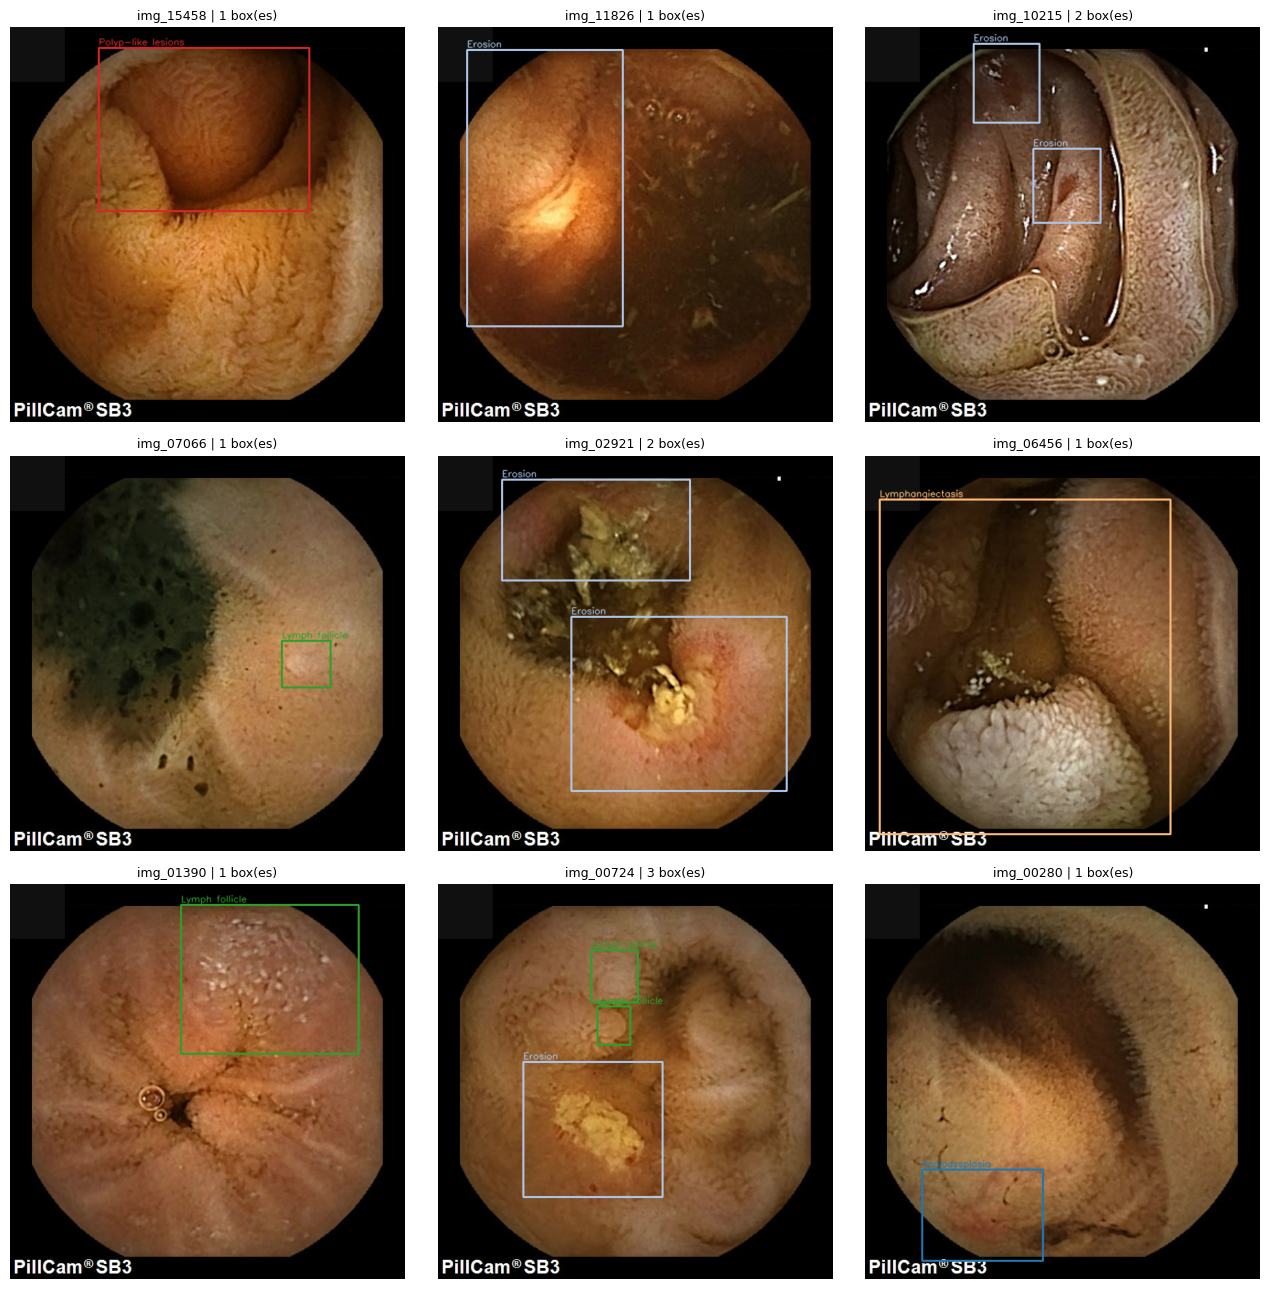

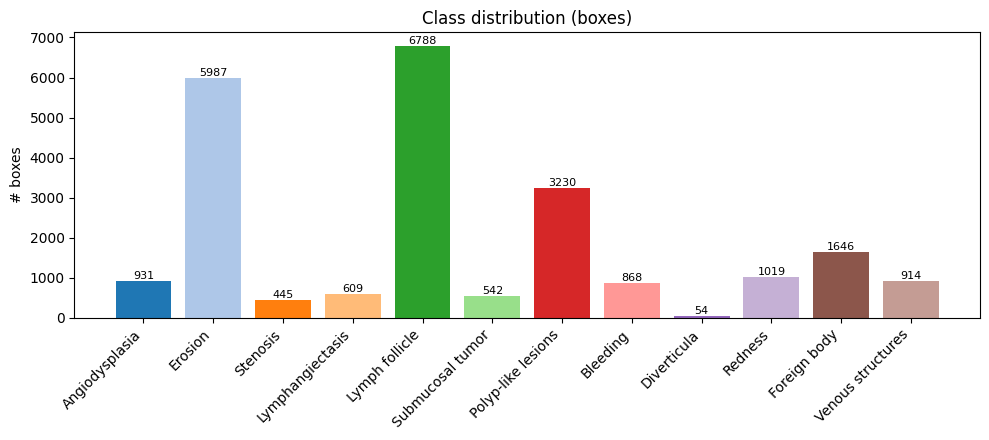

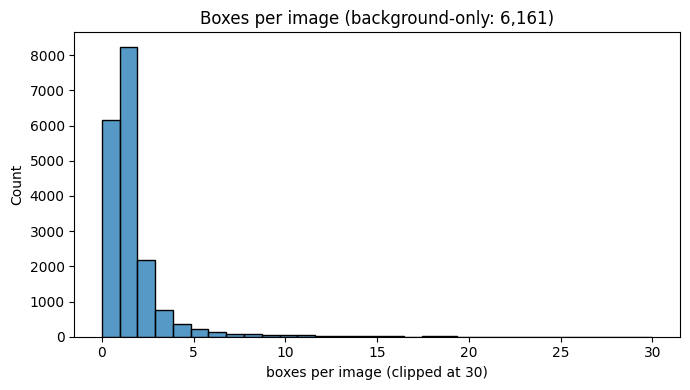

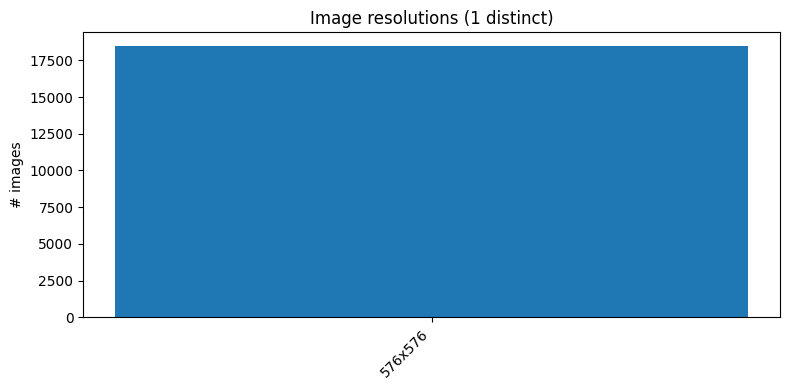

 width  height     n
   576     576 18481
Saved: ['boxes_per_image.png', 'class_distribution.png', 'image_resolutions.png', 'sample_images.png']


In [8]:
# CELL 6 — VISUALIZE DATASET
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
import cv2, matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

man = load_manifest(); names = load_class_names(); NC = CFG["NUM_CLASSES"]
cmap = plt.get_cmap("tab20")
color = lambda c: tuple(int(255 * v) for v in cmap(c % 20)[:3])      # RGB per class

# ---- 3x3 sample grid with boxes + class names ----
rng = np.random.default_rng(0)
cand = man[man.number_of_boxes > 0]
pick = cand.iloc[rng.choice(len(cand), 9, replace=False)]
fig, axes = plt.subplots(3, 3, figsize=(13, 13))
for ax, r in zip(axes.ravel(), pick.itertuples()):
    im = cv2.imread(r.image_path)
    if im is None:
        ax.set_title("unreadable: " + Path(r.image_path).name); ax.axis("off"); print("unreadable:", r.image_path); continue
    im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB); H, W = im.shape[:2]
    rows, _ = parse_label_file(r.label_path)
    for c, x, y, w, h in rows:
        x1, y1, x2, y2 = int((x - w / 2) * W), int((y - h / 2) * H), int((x + w / 2) * W), int((y + h / 2) * H)
        cv2.rectangle(im, (x1, y1), (x2, y2), color(c), max(2, W // 250))
        cv2.putText(im, names[c] if c < len(names) else str(c), (x1, max(12, y1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, max(0.4, W / 1300), color(c), 1, cv2.LINE_AA)
    ax.imshow(im); ax.set_title(f"{r.image_id} | {r.number_of_boxes} box(es)", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.savefig(DIRS["figures"] / "sample_images.png", dpi=130); plt.show()

# ---- class distribution ----
counts = Counter(int(c) for s in man.box_classes for c in s.split(";") if c != "")
fig, ax = plt.subplots(figsize=(10, 4.5))
vals = [counts.get(i, 0) for i in range(NC)]
ax.bar(range(NC), vals, color=[np.array(color(i)) / 255 for i in range(NC)])
ax.set_xticks(range(NC)); ax.set_xticklabels([names[i] if i < len(names) else str(i) for i in range(NC)], rotation=45, ha="right")
for i, v in enumerate(vals): ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
ax.set_ylabel("# boxes"); ax.set_title("Class distribution (boxes)"); plt.tight_layout()
plt.savefig(DIRS["figures"] / "class_distribution.png", dpi=130); plt.show()

# ---- boxes per image ----
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(man.number_of_boxes.clip(upper=30), bins=31, ax=ax); ax.set_xlabel("boxes per image (clipped at 30)")
ax.set_title(f"Boxes per image (background-only: {(man.number_of_boxes==0).sum():,})"); plt.tight_layout()
plt.savefig(DIRS["figures"] / "boxes_per_image.png", dpi=130); plt.show()

# ---- resolutions ----
res = man.groupby(["width", "height"]).size().reset_index(name="n").sort_values("n", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
lab = [f"{w}x{h}" for w, h in zip(res.width, res.height)][:12]
ax.bar(range(len(lab)), res.n.values[:12]); ax.set_xticks(range(len(lab))); ax.set_xticklabels(lab, rotation=45, ha="right")
ax.set_ylabel("# images"); ax.set_title(f"Image resolutions ({len(res)} distinct)"); plt.tight_layout()
plt.savefig(DIRS["figures"] / "image_resolutions.png", dpi=130); plt.show()
print(res.head(10).to_string(index=False))
print("Saved:", sorted(p.name for p in DIRS["figures"].glob("*.png")))

---

## CELL 7 — EXACT DUPLICATE DETECTION
Groups images by SHA-256 of the file bytes. Outputs `exact_duplicate_pairs.csv` (all unordered pairs inside each group), `duplicate_groups.csv`, and `audits/exact_duplicate_audit.csv` (one row per image that has a byte-identical twin, with its class labels).
For groups of size *k* there are *k(k-1)/2* pairs; both numbers are reported.

**Expected output:** number of groups / pairs / images involved. The brief mentions 121 byte-identical pairs from an earlier run; this cell **recomputes** the number (nothing is hard-coded) and prints the earlier figure only as a reference.

**Common errors & fixes**
* `KeyError: sha256` → run Cell 4 first.
* Zero groups → possible if your copy of the dataset is already deduplicated; the later cells handle empty inputs.

In [9]:
# CELL 7 — EXACT DUPLICATE DETECTION
import os, sys, itertools
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *

man = load_manifest(); names = load_class_names()
groups = [g for _, g in man.groupby("sha256") if len(g) > 1]
groups = sorted(groups, key=lambda g: g.image_id.iloc[0])

grp_rows, pair_rows, audit_rows = [], [], []
for gi, g in enumerate(groups):
    gid = f"DG{gi:04d}"; ids = g.image_id.tolist()
    grp_rows.append(dict(group_id=gid, size=len(g), image_ids=";".join(ids), n_boxes=";".join(map(str, g.number_of_boxes)),
                         classes_per_image=" | ".join(g.box_classes.replace("", "(none)")), rep_image_id=ids[0], sha256=g.sha256.iloc[0]))
    for a, b in itertools.combinations(g.itertuples(), 2):
        pair_rows.append(dict(group_id=gid, image_id_a=a.image_id, image_id_b=b.image_id, path_a=a.image_path, path_b=b.image_path,
                              label_path_a=a.label_path, label_path_b=b.label_path,
                              classes_a=a.box_classes or "(none)", classes_b=b.box_classes or "(none)"))
    for k, r in enumerate(g.itertuples()):
        audit_rows.append(dict(group_id=gid, group_size=len(g), image_id=r.image_id, image_path=r.image_path, label_path=r.label_path,
                               n_boxes=r.number_of_boxes, box_classes=r.box_classes or "(none)",
                               class_names=";".join(names[int(c)] if int(c) < len(names) else c for c in r.box_classes.split(";") if c) or "(none)",
                               is_representative=(k == 0)))
G = pd.DataFrame(grp_rows); P = pd.DataFrame(pair_rows); A = pd.DataFrame(audit_rows)
G.to_csv(DIRS["artifacts"] / "duplicate_groups.csv", index=False)
P.to_csv(DIRS["artifacts"] / "exact_duplicate_pairs.csv", index=False)
A.to_csv(DIRS["audits"] / "exact_duplicate_audit.csv", index=False)

print(f"Duplicate groups        : {len(G)}  (size distribution: {dict(Counter(G['size'])) if len(G) else {}})")
print(f"Duplicate pairs         : {len(P)}")
print(f"Images involved         : {len(A)}  ({100*len(A)/len(man):.2f}% of dataset)")
print(f"Redundant images (all but one per group): {len(A)-len(G)}")
print(f"[reference only] your earlier run reported {CFG['PRIOR_RESULTS_FOR_REFERENCE_ONLY']['exact_duplicate_pairs']} byte-identical pairs")
if len(A):
    print("\nWith/without boxes among duplicate images:", dict(Counter(A.n_boxes.clip(upper=1).map({0: "no boxes", 1: ">=1 box"}))))
A.head(10)

Duplicate groups        : 121  (size distribution: {2: 121})
Duplicate pairs         : 121
Images involved         : 242  (1.31% of dataset)
Redundant images (all but one per group): 121
[reference only] your earlier run reported 121 byte-identical pairs

With/without boxes among duplicate images: {'>=1 box': 223, 'no boxes': 19}


,group_id,group_size,image_id,image_path,label_path,n_boxes,box_classes,class_names,is_representative
0,DG0000,2,img_00120,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,1,5,Submucosal tumor,True
1,DG0000,2,img_15803,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,1,5,Submucosal tumor,False
2,DG0001,2,img_00121,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,1,5,Submucosal tumor,True
3,DG0001,2,img_15804,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,1,5,Submucosal tumor,False
4,DG0002,2,img_00129,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,3,4;4;4,Lymph follicle;Lymph follicle;Lymph follicle,True
5,DG0002,2,img_15805,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,6,4;4;4;4;4;4,Lymph follicle;Lymph follicle;Lymph follicle;L...,False
6,DG0003,2,img_00130,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,4,4;4;4;4,Lymph follicle;Lymph follicle;Lymph follicle;L...,True
7,DG0003,2,img_15806,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,13,4;4;4;4;4;4;4;4;4;4;4;4;4,Lymph follicle;Lymph follicle;Lymph follicle;L...,False
8,DG0004,2,img_00131,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,4,4;4;4;4,Lymph follicle;Lymph follicle;Lymph follicle;L...,True
9,DG0004,2,img_15807,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,/kaggle/input/datasets/capsuleyolo/kyucapsule/...,7,4;4;4;4;4;4;4,Lymph follicle;Lymph follicle;Lymph follicle;L...,False


---

## CELL 8 — LABEL-CONFLICT AUDIT
For every byte-identical pair, the two label files are compared (original files, via the same parser as Cell 5). Boxes are matched spatially with the Hungarian algorithm on IoU. Categories:

| type | meaning |
|---|---|
| `identical` | same boxes and classes (matched IoU ≥ `COORD_IOU_TOL`) → **no conflict** |
| `one_empty` | one image has boxes, the other has none |
| `different_box_count` | both non-empty, different number of boxes |
| `class_conflict` | same number of boxes but the multiset of classes differs (or matched boxes disagree on class) |
| `coordinate_conflict` | same classes, but matched boxes differ (IoU < tolerance) |

Outputs: `duplicate_label_conflicts.csv`, `conflict_type_summary.csv`, `conflict_examples.json`, plus a **group-level** table used later to build the deduplicated split.
*The counts are recomputed here; the earlier 121/112 figures are printed for comparison only. Similar, not necessarily identical, counts are expected (tolerance, parsing and pair definition can differ).*

**Common errors & fixes**
* `FileNotFoundError: exact_duplicate_pairs.csv` → run Cell 7.
* Conflict count much lower than your earlier result → lower `COORD_IOU_TOL` is *more* lenient; raise it to 0.99 to be stricter.

In [10]:
# CELL 8 — LABEL-CONFLICT AUDIT
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
from scipy.optimize import linear_sum_assignment

names = load_class_names(); TOL = CFG["COORD_IOU_TOL"]
P = pd.read_csv(DIRS["artifacts"] / "exact_duplicate_pairs.csv", keep_default_na=False, dtype=str)

def load_boxes(path):
    rows, _ = parse_label_file(path)
    a = np.array(rows, dtype=np.float64).reshape(-1, 5)
    return a[:, 0].astype(int), xywhn_to_xyxy(a[:, 1:5]), a

def compare(la, lb):
    ca, ba, _ = la; cb, bb, _ = lb
    na, nb = len(ca), len(cb)
    out = dict(n_a=na, n_b=nb, mean_matched_iou=np.nan, min_matched_iou=np.nan)
    if na == 0 and nb == 0: return "identical", out
    if na == 0 or nb == 0:  return "one_empty", out
    if na != nb:
        out["mean_matched_iou"] = float(np.mean(iou_matrix(ba, bb).max(1)))   # informative best-overlap only
        return "different_box_count", out
    iou = iou_matrix(ba, bb); r, c = linear_sum_assignment(-iou); m = iou[r, c]
    out["mean_matched_iou"], out["min_matched_iou"] = float(m.mean()), float(m.min())
    if sorted(ca.tolist()) != sorted(cb.tolist()) or (ca[r] != cb[c]).any():
        return "class_conflict", out
    if (m < TOL).any(): return "coordinate_conflict", out
    return "identical", out

rows, examples = [], defaultdict(list)
for p in P.itertuples():
    la, lb = load_boxes(p.label_path_a), load_boxes(p.label_path_b)
    t, o = compare(la, lb)
    rows.append(dict(group_id=p.group_id, image_id_a=p.image_id_a, image_id_b=p.image_id_b, conflict_type=t,
                     is_conflict=(t != "identical"), classes_a=p.classes_a, classes_b=p.classes_b, **o))
    if t != "identical" and len(examples[t]) < 5:
        examples[t].append(dict(image_id_a=p.image_id_a, image_id_b=p.image_id_b, path_a=p.path_a, path_b=p.path_b,
                                boxes_a=la[2].round(4).tolist(), boxes_b=lb[2].round(4).tolist(), **o))
C = pd.DataFrame(rows, columns=["group_id", "image_id_a", "image_id_b", "conflict_type", "is_conflict", "classes_a", "classes_b",
                                "n_a", "n_b", "mean_matched_iou", "min_matched_iou"])
C["is_conflict"] = C["is_conflict"].astype(bool)
C.to_csv(DIRS["audits"] / "duplicate_label_conflicts.csv", index=False)
save_json(examples, DIRS["audits"] / "conflict_examples.json")

summ = (C.conflict_type.value_counts().rename_axis("conflict_type").reset_index(name="n_pairs")
        if len(C) else pd.DataFrame(columns=["conflict_type", "n_pairs"]))
summ["pct_of_pairs"] = 100 * summ.n_pairs / max(len(C), 1)
summ.to_csv(DIRS["audits"] / "conflict_type_summary.csv", index=False)

# group-level view (used by Cell 13)
if len(C):
    gl = C.groupby("group_id").agg(n_pairs=("is_conflict", "size"), n_conflicting_pairs=("is_conflict", "sum"),
                                   conflict_types=("conflict_type", lambda s: ";".join(sorted(set(s) - {"identical"})))).reset_index()
    gl["group_has_conflict"] = gl.n_conflicting_pairs > 0
else:
    gl = pd.DataFrame(columns=["group_id", "n_pairs", "n_conflicting_pairs", "conflict_types", "group_has_conflict"])
gl.to_csv(DIRS["audits"] / "duplicate_group_conflicts.csv", index=False)

# classes most affected (classes appearing in either label of a conflicting pair)
aff = Counter()
for r in C[C.is_conflict].itertuples():
    for s in (r.classes_a, r.classes_b):
        for c in set(s.split(";")) - {"(none)", ""}: aff[int(c)] += 1
aff_df = pd.DataFrame([(names[k] if k < len(names) else k, v) for k, v in aff.most_common()], columns=["class", "n_conflicting_pairs_involving"])
aff_df.to_csv(DIRS["audits"] / "conflict_classes_affected.csv", index=False)

n_pairs, n_conf = len(C), int(C.is_conflict.sum()) if len(C) else 0
print(f"Total duplicate pairs      : {n_pairs}")
print(f"Conflicting duplicate pairs: {n_conf}  ({100*n_conf/max(n_pairs,1):.1f}%)")
print(f"[reference only] earlier run: {CFG['PRIOR_RESULTS_FOR_REFERENCE_ONLY']['exact_duplicate_pairs']} pairs / "
      f"{CFG['PRIOR_RESULTS_FOR_REFERENCE_ONLY']['conflicting_pairs']} conflicting -> same ballpark? "
      f"{abs(n_pairs-121) <= 0.1*121 and abs(n_conf-112) <= 0.1*112}")
print("\nConflict types:"); print(summ.to_string(index=False))
print("\nClasses most affected:"); print(aff_df.head(12).to_string(index=False))
print(f"\nGroups with >=1 conflict: {int(gl.group_has_conflict.sum())} / {len(gl)}")

Total duplicate pairs      : 121
Conflicting duplicate pairs: 107  (88.4%)
[reference only] earlier run: 121 pairs / 112 conflicting -> same ballpark? True

Conflict types:
      conflict_type  n_pairs  pct_of_pairs
coordinate_conflict       79     65.289256
different_box_count       17     14.049587
          identical       14     11.570248
     class_conflict       10      8.264463
          one_empty        1      0.826446

Classes most affected:
             class  n_conflicting_pairs_involving
           Erosion                            120
Polyp-like lesions                             32
    Lymph follicle                             17
          Bleeding                             13
    Angiodysplasia                             12
           Redness                             12
      Foreign body                             10
  Lymphangiectasis                              8
  Submucosal tumor                              4
       Diverticula                           

---

## CELL 9 — NEAR-DUPLICATE DETECTION
**Embeddings:** torchvision ResNet-18 (ImageNet weights), classifier removed, global-average-pooled 512-d features, images resized to 224×224 and ImageNet-normalised. Uses **both GPUs** via `DataParallel` and fp16 autocast. Embeddings are stored as float16.

**Similarity:** cosine similarity via **chunked** matrix products (never builds the N×N matrix). For each image the top-`KNN_K` neighbours are kept; *exact* counts of all pairs ≥ each threshold are accumulated separately in the same pass. Pair CSVs list pairs found among each image's top-K neighbours (bounded size), and the all-pairs counts are saved to `near_dup_summary.json` so you can see if the top-K lists truncate anything.

> ⚠️ **Read this before trusting thresholds.** Global-average-pooled ReLU features are non-negative, so cosine similarity between *any* two endoscopy frames can already be high (often > 0.8). If many more pairs than expected exceed 0.90, the near-duplicate graph in Cell 12 can collapse into one giant component. Cell 12 detects this and tells you to set `CENTER_EMBEDDINGS=True` (mean-centred cosine, far more discriminative) or to raise the threshold. I did not run this on your data, so I can't tell you which case you're in; the printed pair counts will.

**Expected output:** progress bars (embedding, similarity), pair counts per threshold, distribution of max-cosine, examples.

**Common errors & fixes**
* `URLError` / weights download fails → enable Internet, or set `ALLOW_FALLBACK_EMBEDDING=True` (colour-thumbnail embedding; weaker, and flagged in `embedding_meta.json`).
* CUDA OOM → lower `BS` below. Slow → `num_workers` is 4; image decoding is the bottleneck, not the GPU.
* Re-run is instant if `embeddings.npy` exists and matches the manifest (delete it to recompute).

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 165MB/s] 


embedding:   0%|          | 0/73 [00:00<?, ?it/s]

unreadable images: 0
Saved /kaggle/working/capsulecopilot/artifacts/embeddings.npy (18481, 512)


cosine (chunked):   0%|          | 0/10 [00:00<?, ?it/s]


Near-duplicate pairs (unordered):
  cos >= 0.90: all-pairs = 1,289,064 | in top-20 lists = 200,596 | images involved = 16,985
  cos >= 0.95: all-pairs = 9,204 | in top-20 lists = 8,624 | images involved = 4,441
  cos >= 0.98: all-pairs = 225 | in top-20 lists = 225 | images involved = 363

Max-cosine (top-1 neighbour) quantiles: {'min': np.float64(0.8068), '5%': np.float64(0.8934), '25%': np.float64(0.9186), '50%': np.float64(0.9345), '75%': np.float64(0.9493), '95%': np.float64(0.9698), 'max': np.float64(1.0)}


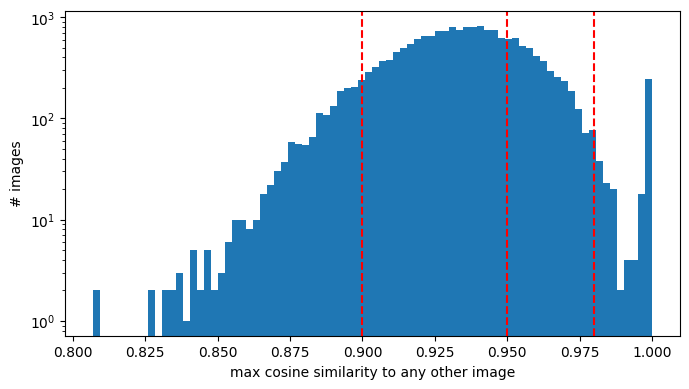

In [11]:
# CELL 9 — NEAR-DUPLICATE DETECTION (ResNet-18 embeddings + chunked cosine)
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
import torch, torch.nn as nn, torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

A = DIRS["artifacts"]; man = load_manifest(); N = len(man)
dev = "cuda" if torch.cuda.is_available() else "cpu"; n_gpu = torch.cuda.device_count()
emb_path, ids_path, meta_path = A / "embeddings.npy", A / "embedding_ids.csv", A / "embedding_meta.json"

class ImgDS(Dataset):
    def __init__(self, paths, tf): self.paths, self.tf = paths, tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        try:
            return self.tf(Image.open(self.paths[i]).convert("RGB")), 1
        except Exception as e:                      # unreadable image -> zeros, flagged
            print("unreadable image:", self.paths[i], e); return torch.zeros(3, 224, 224), 0

def thumbnail_embedding(path):                      # fallback only (flagged in meta)
    im = np.asarray(Image.open(path).convert("RGB").resize((16, 16)), dtype=np.float32).ravel() / 255.0
    hist = np.concatenate([np.histogram(np.asarray(Image.open(path).convert("RGB"))[..., c], 16, (0, 255))[0] for c in range(3)]).astype(np.float32)
    v = np.concatenate([im, hist / (hist.sum() + 1e-6)]); return v

cached = emb_path.exists() and ids_path.exists() and pd.read_csv(ids_path, dtype=str).image_id.tolist() == man.image_id.tolist()
if cached:
    print("Using cached embeddings:", emb_path)
else:
    used = "resnet18_imagenet"
    try:
        net = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        net.fc = nn.Identity(); net = net.to(dev).eval()
        if n_gpu > 1: net = nn.DataParallel(net)      # <- uses both T4s
        tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                                 transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
        BS = 256
        dl = DataLoader(ImgDS(man.image_path.tolist(), tf), batch_size=BS, num_workers=4, shuffle=False, pin_memory=True)
        outs, ok = [], []
        with torch.no_grad(), torch.autocast(device_type="cuda", enabled=(dev == "cuda")):
            for x, o in tqdm(dl, desc="embedding"):
                outs.append(net(x.to(dev, non_blocking=True)).float().cpu()); ok.append(o)
        E = torch.cat(outs).numpy(); ok = torch.cat(ok).numpy()
        print("unreadable images:", int((ok == 0).sum()))
    except Exception as e:
        if not CFG.get("ALLOW_FALLBACK_EMBEDDING"):
            raise RuntimeError(f"ResNet-18 embedding failed: {e}\nEnable Internet for the weight download, or set "
                               f"CONFIG['ALLOW_FALLBACK_EMBEDDING']=True (weaker features).")
        print("WARNING: using FALLBACK thumbnail embeddings:", e); used = "fallback_thumbnail"
        E = np.stack([thumbnail_embedding(p) for p in tqdm(man.image_path, desc="fallback emb")])
    np.save(emb_path, E.astype(np.float16)); man[["image_id"]].to_csv(ids_path, index=False)
    save_json(dict(model=used, dim=int(E.shape[1]), n=int(N), dtype="float16"), meta_path)
    print("Saved", emb_path, E.shape)

# ---------------- chunked cosine neighbours ----------------
ids, E = load_embeddings()                          # float32, L2-normalised (optionally centred via CONFIG)
K, THR = CFG["KNN_K"], CFG["COSINE_THRESHOLDS"]
Et = torch.from_numpy(E).to(dev)
nn_rows, top1 = [], np.zeros(N, np.float32)
counts_all = {t: 0 for t in THR}
pair_sets = {t: {} for t in THR}                    # (i,j)->cos, from top-K lists
CH = 2048
for s in tqdm(range(0, N, CH), desc="cosine (chunked)"):
    q = Et[s:s + CH]; sim = q @ Et.T                # (chunk, N) only
    sim[torch.arange(len(q)), torch.arange(s, s + len(q))] = -1.0       # remove self-similarity
    for t in THR:
        counts_all[t] += int((sim >= t).sum().item())
    v, ix = torch.topk(sim, K, dim=1); v, ix = v.cpu().numpy(), ix.cpu().numpy()
    top1[s:s + len(q)] = v[:, 0]
    for r in range(len(q)):
        i = s + r
        for k in range(K):
            j = int(ix[r, k]); c = float(v[r, k])
            nn_rows.append((ids[i], k + 1, ids[j], c))
            for t in THR:
                if c >= t:
                    a, b = (i, j) if i < j else (j, i); pair_sets[t][(a, b)] = c
counts_all = {t: c // 2 for t, c in counts_all.items()}      # ordered -> unordered pairs

nn_df = pd.DataFrame(nn_rows, columns=["image_id", "rank", "neighbor_id", "cosine"])
nn_df.to_csv(A / "nearest_neighbors.csv", index=False)
np.save(A / "max_cosine_top1.npy", top1)
sha = man.sha256.values
summary = dict(center_embeddings=bool(CFG.get("CENTER_EMBEDDINGS", False)), knn_k=K, thresholds={})
for t in THR:
    pr = pd.DataFrame([(ids[a], ids[b], c, bool(sha[a] == sha[b])) for (a, b), c in pair_sets[t].items()],
                      columns=["image_id_a", "image_id_b", "cosine", "same_sha256"])
    pr.to_csv(A / f"near_duplicate_pairs_cosine_{t:.2f}.csv", index=False)
    summary["thresholds"][f"{t:.2f}"] = dict(pairs_in_topk_lists=len(pr), all_pairs_exact_count=int(counts_all[t]),
                                             images_involved_topk=int(len(set(pr.image_id_a) | set(pr.image_id_b))))
save_json(summary, A / "near_dup_summary.json")

print("\nNear-duplicate pairs (unordered):")
for t in THR:
    d = summary["thresholds"][f"{t:.2f}"]
    print(f"  cos >= {t:.2f}: all-pairs = {d['all_pairs_exact_count']:,} | in top-{K} lists = {d['pairs_in_topk_lists']:,} | images involved = {d['images_involved_topk']:,}")
print("\nMax-cosine (top-1 neighbour) quantiles:", dict(zip(["min", "5%", "25%", "50%", "75%", "95%", "max"],
      np.round(np.quantile(top1, [0, .05, .25, .5, .75, .95, 1]), 4))))
big = summary["thresholds"][f"{CFG['PRIMARY_COSINE']:.2f}"]["images_involved_topk"] / N
if big > 0.5:
    print(f"\nWARNING: {100*big:.0f}% of images have a neighbour >= {CFG['PRIMARY_COSINE']}. Raw ResNet features are probably not discriminative "
          f"enough; consider CONFIG['CENTER_EMBEDDINGS']=True (re-run Cells 2, 9).")
fig, ax = plt.subplots(figsize=(7, 4)); ax.hist(top1, bins=80); [ax.axvline(t, ls="--", c="r") for t in THR]
ax.set_xlabel("max cosine similarity to any other image"); ax.set_ylabel("# images"); ax.set_yscale("log"); plt.tight_layout()
plt.savefig(DIRS["figures"] / "max_cosine_hist_cell9.png", dpi=130); plt.show()

---

## CELL 10 — VISUALIZE NEAR-DUPLICATES
Shows image / nearest neighbour / cosine, and whether both images land in the **same** or **different** partitions under the **random** split (this is how leakage arises). Also saves the max-cosine histogram with threshold lines.

**Expected output:** `near_duplicates.png` (two rows of pairs), and `max_cosine_hist.png`. Pairs whose captions say `random split: train → test` are leaked pairs.

**Common errors & fixes**
* "No pairs at the chosen threshold" → the cell falls back to the highest-similarity pairs it has.
* Blank images → unreadable files (see Cell 6).

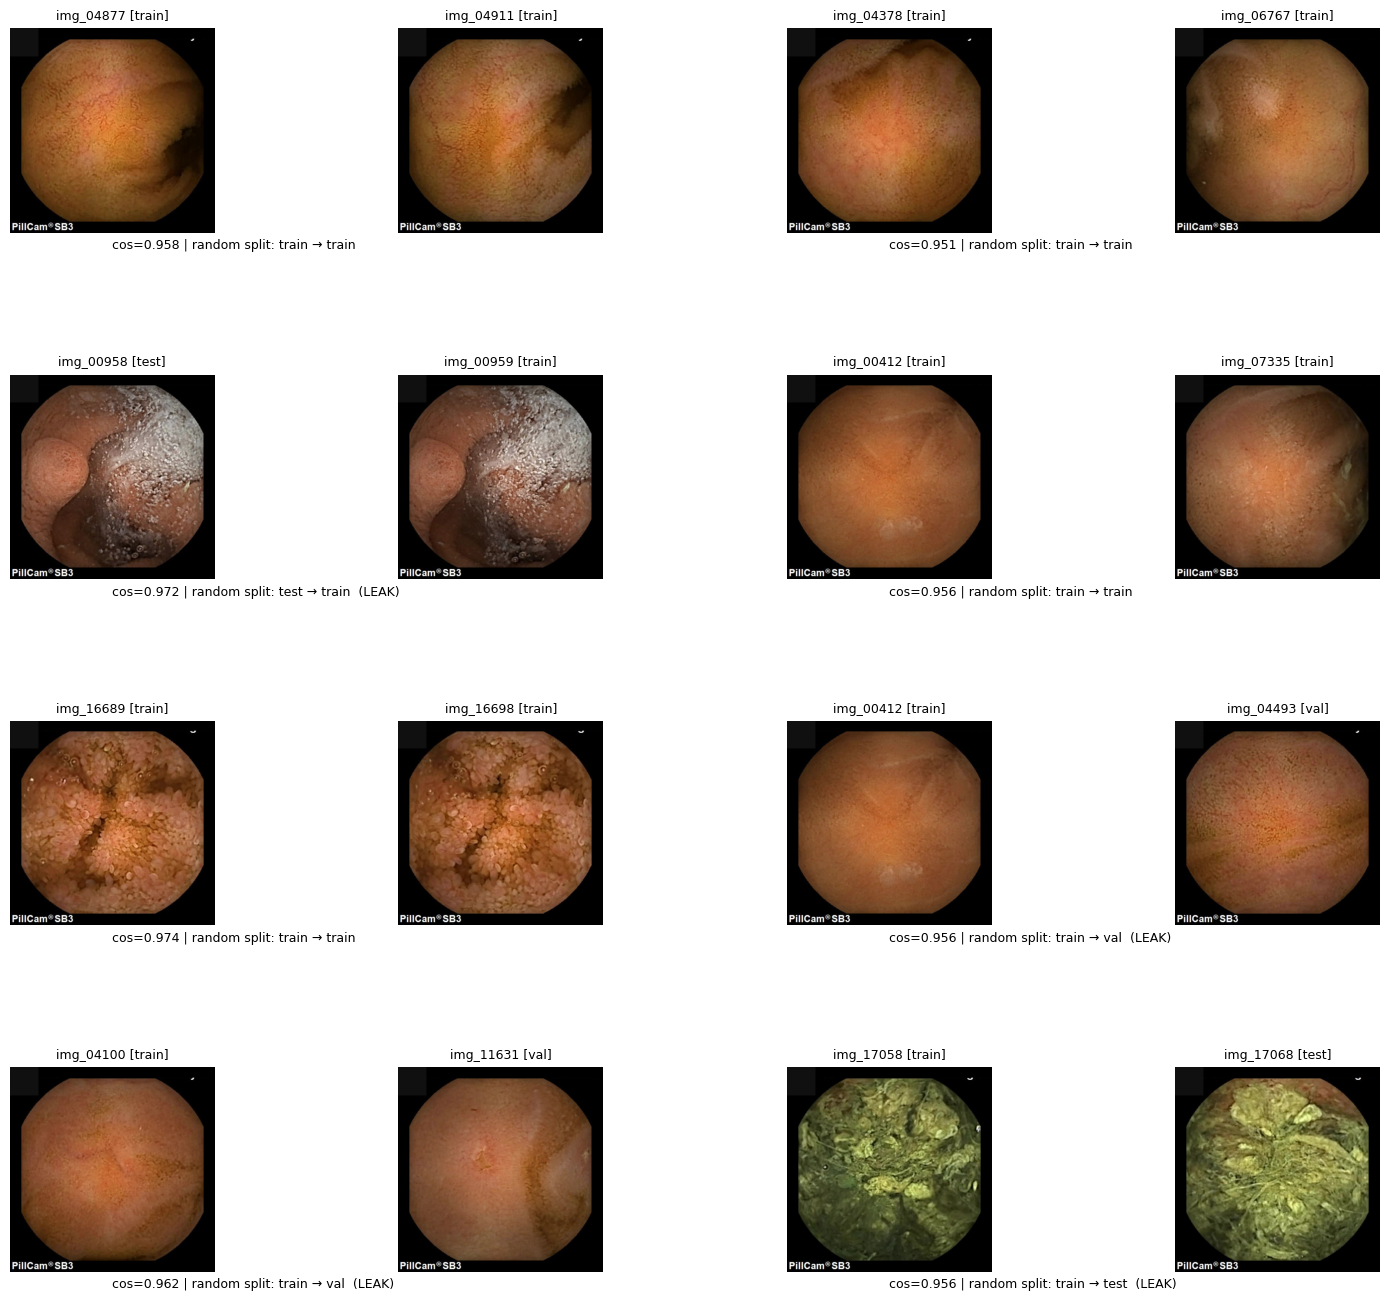

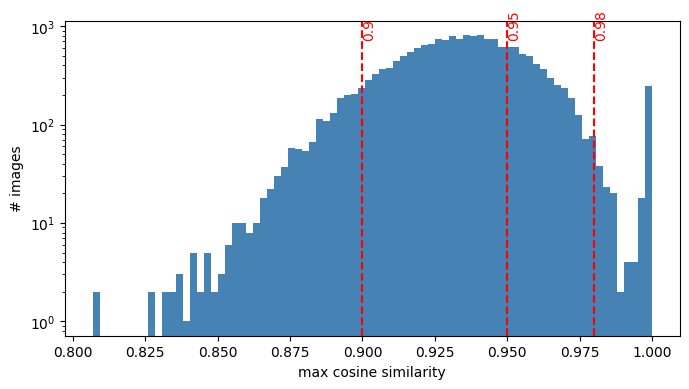

In [12]:
# CELL 10 — VISUALIZE NEAR-DUPLICATES
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
import matplotlib.pyplot as plt
from PIL import Image

man = load_manifest(); A = DIRS["artifacts"]
part = dict(zip(man.image_id, make_random_split(man, CFG["SPLIT_SEED"], tuple(CFG["SPLIT_FRACS"]))))   # same as Cell 11
path = dict(zip(man.image_id, man.image_path)); top1 = np.load(A / "max_cosine_top1.npy")
thr = CFG["PRIMARY_COSINE"]
pr = pd.read_csv(A / f"near_duplicate_pairs_cosine_{thr:.2f}.csv", dtype={"image_id_a": str, "image_id_b": str})
pr = pr[~pr.same_sha256] if (~pr.same_sha256).any() else pr                          # prefer non-byte-identical pairs
if len(pr) == 0:
    nn1 = pd.read_csv(A / "nearest_neighbors.csv", dtype={"image_id": str, "neighbor_id": str}); nn1 = nn1[nn1["rank"] == 1]
    pr = nn1.sort_values("cosine", ascending=False).head(8).rename(columns={"image_id": "image_id_a", "neighbor_id": "image_id_b"})
    print("No pairs >= threshold; showing the 8 most similar pairs instead.")
pr = pr.sample(n=min(8, len(pr)), random_state=0)
fig, axes = plt.subplots(4, 4, figsize=(14, 14))
for k, r in enumerate(pr.itertuples()):
    for j, iid in enumerate((r.image_id_a, r.image_id_b)):
        ax = axes[(k // 2), (k % 2) * 2 + j]
        ax.imshow(Image.open(path[iid]).convert("RGB")); ax.axis("off")
        ax.set_title(f"{iid} [{part[iid]}]", fontsize=9)
    axes[k // 2, (k % 2) * 2].text(0.5, -0.08, f"cos={r.cosine:.3f} | random split: {part[r.image_id_a]} → {part[r.image_id_b]}"
                                   + ("  (LEAK)" if {part[r.image_id_a], part[r.image_id_b]} & {"test", "val"} and part[r.image_id_a] != part[r.image_id_b] else ""),
                                   transform=axes[k // 2, (k % 2) * 2].transAxes, fontsize=9, ha="left")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.savefig(DIRS["figures"] / "near_duplicates.png", dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(7, 4)); ax.hist(top1, bins=80, color="steelblue")
for t in CFG["COSINE_THRESHOLDS"]: ax.axvline(t, ls="--", c="r"); ax.text(t, ax.get_ylim()[1] * .9, f"{t}", rotation=90, color="r")
ax.set_yscale("log"); ax.set_xlabel("max cosine similarity"); ax.set_ylabel("# images"); plt.tight_layout()
plt.savefig(DIRS["figures"] / "max_cosine_hist.png", dpi=130); plt.show()

---

## CELL 11 — CREATE ORIGINAL / RANDOM SPLIT (leakage-prone baseline)
70 / 15 / 15 image-level random split, seed 0, **no** duplicate removal. This mimics what a typical paper does; it is the control.

**Expected output:** partition sizes (~12.9k / 2.8k / 2.8k for 18,481 images) and saved files `random_split.csv`, `random_train.txt`, `random_val.txt`, `random_test.txt` in `splits/`.

**Common errors & fixes:** none expected; deterministic given the seed.

In [13]:
# CELL 11 — RANDOM SPLIT
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *

man = load_manifest()
df = man[["image_id", "image_path", "label_path", "number_of_boxes"]].copy()
df["partition"] = make_random_split(man, CFG["SPLIT_SEED"], tuple(CFG["SPLIT_FRACS"]))

save_split(df, "random")
print("NOTE: this split ignores duplicates by design (leakage-prone control).")

[random]  {'train': 12937, 'val': 2772, 'test': 2772} {'train': np.float64(70.0), 'val': np.float64(15.0), 'test': np.float64(15.0)}
NOTE: this split ignores duplicates by design (leakage-prone control).


---

## CELL 12 — CREATE BLOCKED / NEAR-DUPLICATE-CONTROLLED SPLIT
Nodes = images. Edges = near-duplicate pairs at cosine ≥ **0.95** (plus every byte-identical pair). **Connected components are never split**: all members of a component go to the same partition. Components are assigned greedily (largest first) to whichever partition has the largest relative deficit versus the 70/15/15 targets; a component larger than half of the test target is forced into **train**.

> **This is NOT patient-level splitting.** SEE-AI has no patient or video IDs. It is a *blocked / near-duplicate-controlled* split: it can only separate frames the embedding judges similar. Frames of the same patient that look different can still straddle the boundary, so residual leakage can remain (Cell 16 measures what is left).

**Expected output:** component-size statistics, partition sizes close to 70/15/15, class counts per partition, and a warning if the largest component is > 25% of the data.

**Common errors & fixes**
* *Giant component warning* → set `CENTER_EMBEDDINGS=True` and re-run Cells 2 and 9 (then 12), or raise `PRIMARY_COSINE` to 0.98.
* Test set much smaller than 15% → too many big components were pushed to train; same remedy.
* Rare class missing from val/test → the table at the end flags it; try another `SPLIT_SEED`.

In [14]:
# CELL 12 — BLOCKED SPLIT
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *

man = load_manifest(); N = len(man); ids = man.image_id.tolist(); idx = {i: k for k, i in enumerate(ids)}
thr = CFG["PRIMARY_COSINE"]
pairs = pd.read_csv(DIRS["artifacts"] / f"near_duplicate_pairs_cosine_{thr:.2f}.csv", dtype={"image_id_a": str, "image_id_b": str})

uf = UnionFind(N)
for a, b in zip(pairs.image_id_a, pairs.image_id_b): uf.union(idx[a], idx[b])
for _, g in man.groupby("sha256"):                      # byte-identical images are always blocked together
    g_idx = [idx[i] for i in g.image_id]
    for j in g_idx[1:]: uf.union(g_idx[0], j)
root = np.array([uf.find(i) for i in range(N)])
comp_ids, inv, sizes = np.unique(root, return_inverse=True, return_counts=True)
comp_size = sizes[inv]
print(f"Components: {len(comp_ids):,} | singletons: {(sizes==1).sum():,} | largest: {sizes.max()} images ({100*sizes.max()/N:.1f}%)")
print("Component size quantiles:", dict(zip(["50%", "90%", "99%", "max"], np.quantile(sizes, [.5, .9, .99, 1]).astype(int))))
if sizes.max() / N > 0.25:
    print("WARNING: giant component (>25% of data). All of it goes to train, so test/val shrink and the split is less meaningful. "
          "See the 'Common errors' note: try CENTER_EMBEDDINGS=True or a higher PRIMARY_COSINE.")

fr = dict(zip(PARTS, CFG["SPLIT_FRACS"])); target = {p: fr[p] * N for p in PARTS}
cap_eval = max(1, int(0.5 * target["test"]))            # components larger than this are assigned to train
rng = np.random.default_rng(CFG["SPLIT_SEED"])
order = sorted(range(len(comp_ids)), key=lambda c: (-sizes[c], rng.random()))
count = {p: 0 for p in PARTS}; assign = {}
for c in order:
    s = sizes[c]
    if s > cap_eval: p = "train"
    else: p = max(PARTS, key=lambda q: (target[q] - count[q]) / target[q])      # largest relative deficit
    assign[c] = p; count[p] += s

df = man[["image_id", "image_path", "label_path", "number_of_boxes"]].copy()
df["partition"] = [assign[c] for c in inv]; df["component_id"] = inv; df["component_size"] = comp_size
save_split(df, "blocked")

# class counts per partition (rare-class check)
names = load_class_names(); cls_rows = []
for p in PARTS:
    cnt = Counter(int(c) for s in man.box_classes[df.partition.values == p] for c in s.split(";") if c)
    cls_rows.append({"partition": p, **{(names[i] if i < len(names) else str(i)): cnt.get(i, 0) for i in range(CFG["NUM_CLASSES"])}})
cls_tab = pd.DataFrame(cls_rows).set_index("partition"); print("\nBoxes per class and partition:"); print(cls_tab.T.to_string())
low = [c for c in cls_tab.columns if cls_tab.loc["test", c] < 10 or cls_tab.loc["val", c] < 10]
if low: print("\nWARNING: very few boxes (<10) in val/test for:", low, "-> per-class AP for these is unreliable.")
print("\nREMINDER: this is a near-duplicate-controlled split, NOT patient-level.")

Components: 15,051 | singletons: 14,040 | largest: 1239 images (6.7%)
Component size quantiles: {'50%': np.int64(1), '90%': np.int64(1), '99%': np.int64(3), 'max': np.int64(1239)}
[blocked]  {'train': 12936, 'val': 2773, 'test': 2772} {'train': np.float64(70.0), 'val': np.float64(15.0), 'test': np.float64(15.0)}

Boxes per class and partition:
partition           train  val  test
Angiodysplasia        706  112   113
Erosion              4298  837   852
Stenosis              312   70    63
Lymphangiectasis      422   91    96
Lymph follicle       5040  890   858
Submucosal tumor      385   84    73
Polyp-like lesions   2329  452   449
Bleeding              613  116   139
Diverticula            34    6    14
Redness               727  127   165
Foreign body         1178  200   268
Venous structures     646  111   157


REMINDER: this is a near-duplicate-controlled split, NOT patient-level.


---

## CELL 13 — CREATE DEDUPLICATED-BLOCKED SPLIT
Starting from the **blocked** split:
1. every image belonging to an exact-duplicate group that has a **label conflict** is removed;
2. for each remaining duplicate group, **one representative** (lowest `image_id`) is kept, the others removed.

Applied to all three partitions (exact duplicates always sit in the same partition because they share a component). Consequently the deduplicated **test set is a subset of the blocked test set**, so models trained on either split can be compared on identical images (paired bootstrap, Cell 21). *This deviates from "dedupe, then split" in the brief on purpose; see Cell 0.*

**Expected output:** counts removed/retained (by reason), per-partition sizes, class distribution before vs after.

**Common errors & fixes**
* `FileNotFoundError: duplicate_group_conflicts.csv` → run Cell 8. `blocked_split.csv` missing → run Cell 12.

In [15]:
# CELL 13 — DEDUPLICATED-BLOCKED SPLIT
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *

man = load_manifest(); names = load_class_names()
blk = load_split("blocked")
G = pd.read_csv(DIRS["artifacts"] / "duplicate_groups.csv", dtype=str, keep_default_na=False)
GC = pd.read_csv(DIRS["audits"] / "duplicate_group_conflicts.csv", keep_default_na=False)
conflicting = set(GC[GC.group_has_conflict.astype(str) == "True"].group_id)

removed = []
for g in G.itertuples():
    members = g.image_ids.split(";")
    if g.group_id in conflicting:
        removed += [(m, "conflicting_duplicate_group", g.group_id) for m in members]
    else:
        removed += [(m, "redundant_duplicate", g.group_id) for m in members[1:]]       # keep the first (representative)
rem = pd.DataFrame(removed, columns=["image_id", "reason", "group_id"])
rem.to_csv(DIRS["audits"] / "dedup_removed_images.csv", index=False)

dd = blk[~blk.image_id.isin(set(rem.image_id))].copy()
save_split(dd, "deduplicated_blocked")

print(f"\nRemoved: {len(rem)} images ({rem.reason.value_counts().to_dict()}) | retained: {len(dd)} of {len(blk)}")
print("Removed per partition (blocked split):", blk[blk.image_id.isin(set(rem.image_id))].partition.value_counts().to_dict())
assert set(dd[dd.partition == "test"].image_id) <= set(blk[blk.partition == "test"].image_id), "dedup test must be subset of blocked test"

def class_counts(ids):
    sub = man[man.image_id.isin(ids)]
    c = Counter(int(x) for s in sub.box_classes for x in s.split(";") if x)
    return [c.get(i, 0) for i in range(CFG["NUM_CLASSES"])]
tab = pd.DataFrame({"class": [names[i] if i < len(names) else i for i in range(CFG["NUM_CLASSES"])],
                    "boxes_before": class_counts(set(blk.image_id)), "boxes_after": class_counts(set(dd.image_id))})
tab["removed"] = tab.boxes_before - tab.boxes_after; tab["pct_removed"] = (100 * tab.removed / tab.boxes_before.clip(lower=1)).round(2)
tab.to_csv(DIRS["audits"] / "dedup_class_distribution.csv", index=False); print(tab.to_string(index=False))

[deduplicated_blocked]  {'train': 12785, 'val': 2733, 'test': 2735} {'train': np.float64(70.0), 'val': np.float64(15.0), 'test': np.float64(15.0)}

Removed: 228 images ({'conflicting_duplicate_group': 214, 'redundant_duplicate': 14}) | retained: 18253 of 18481
Removed per partition (blocked split): {'train': 151, 'val': 40, 'test': 37}
             class  boxes_before  boxes_after  removed  pct_removed
    Angiodysplasia           931          919       12         1.29
           Erosion          5987         5834      153         2.56
          Stenosis           445          445        0         0.00
  Lymphangiectasis           609          601        8         1.31
    Lymph follicle          6788         6712       76         1.12
  Submucosal tumor           542          538        4         0.74
Polyp-like lesions          3230         3178       52         1.61
          Bleeding           868          850       18         2.07
       Diverticula            54           52     

---

## CELL 14 — CREATE YOLO DATASET FOLDERS
For each split (`random`, `blocked`, `deduplicated_blocked`) builds
`splits/<name>/images/{train,val,test}` and `splits/<name>/labels/{train,val,test}`.
* **Images:** symbolic links (copy fallback) named `<image_id><ext>` → no extra disk use, and filenames are unique and traceable.
* **Labels:** written as sanitised copies (policy from Cell 5) with a full change log `label_sanitization_log.csv`. A label file is created for **every** image (empty = background).
* Ultralytics finds labels by replacing `/images/` with `/labels/` in the image path; this is verified at the end.

**Expected output:** per-split progress bars, sanitisation totals, "label lookup check: OK".

**Common errors & fixes**
* `OSError: symlink` → falls back to copying automatically (uses more disk; Kaggle working dir limit ≈ 20 GB).
* Many "missing_label → background" entries → pairing issue; stop and inspect Cell 3.
* Stale `.cache` files after re-building → this cell deletes them.

In [16]:
# CELL 14 — YOLO DATASET FOLDERS (symlinked images, sanitised labels)
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor

man = load_manifest().set_index("image_id"); NC = CFG["NUM_CLASSES"]; log_rows = []

def sanitise_label(src, dst, image_id, split, part):
    """Write cleaned label file; return list of log rows. Policy documented in Cell 5."""
    log = []
    if not src or not Path(src).exists():
        Path(dst).write_text(""); return [dict(split=split, partition=part, image_id=image_id, line_no=0, action="missing_label_written_as_empty", detail="")]
    rows, bad = parse_label_file(src); out = []
    for ln, text, reason in bad: log.append(dict(split=split, partition=part, image_id=image_id, line_no=ln, action="dropped_malformed", detail=reason))
    for k, (c, x, y, w, h) in enumerate(rows, 1):
        if not (0 <= c < NC): log.append(dict(split=split, partition=part, image_id=image_id, line_no=k, action="dropped_bad_class", detail=str(c))); continue
        x1, y1, x2, y2 = x - w / 2, y - h / 2, x + w / 2, y + h / 2
        cx1, cy1, cx2, cy2 = [min(max(v, 0.0), 1.0) for v in (x1, y1, x2, y2)]
        nw, nh = cx2 - cx1, cy2 - cy1
        if nw <= 1e-6 or nh <= 1e-6:
            log.append(dict(split=split, partition=part, image_id=image_id, line_no=k, action="dropped_zero_area", detail=f"{w},{h}")); continue
        if (cx1, cy1, cx2, cy2) != (x1, y1, x2, y2):
            log.append(dict(split=split, partition=part, image_id=image_id, line_no=k, action="clipped_to_image", detail=f"{x},{y},{w},{h}"))
        out.append(f"{c} {(cx1+cx2)/2:.6f} {(cy1+cy2)/2:.6f} {nw:.6f} {nh:.6f}")
    Path(dst).write_text("\n".join(out) + ("\n" if out else "")); return log

def link_or_copy(src, dst):
    try:
        if os.path.lexists(dst): os.remove(dst)
        os.symlink(os.path.abspath(src), dst); return "link"
    except OSError:
        shutil.copy2(src, dst); return "copy"

modes = Counter()
for split in SPLIT_NAMES:
    df = load_split(split); base = DIRS["splits"] / split
    if base.exists(): shutil.rmtree(base)
    for kind in ("images", "labels"):
        for p in PARTS: (base / kind / p).mkdir(parents=True, exist_ok=True)
    def work(r):
        ext = Path(r.image_path).suffix.lower()
        m = link_or_copy(r.image_path, base / "images" / r.partition / f"{r.image_id}{ext}")
        lg = sanitise_label(r.label_path, base / "labels" / r.partition / f"{r.image_id}.txt", r.image_id, split, r.partition)
        return m, lg
    with ThreadPoolExecutor(8) as ex:
        for m, lg in tqdm(ex.map(work, list(df.itertuples())), total=len(df), desc=f"build {split}"):
            modes[m] += 1; log_rows += lg
    for c in base.rglob("*.cache"): c.unlink()

LOG = pd.DataFrame(log_rows, columns=["split", "partition", "image_id", "line_no", "action", "detail"])
LOG.to_csv(DIRS["artifacts"] / "label_sanitization_log.csv", index=False)
print("\nImage materialisation:", dict(modes))
print("Sanitisation actions:", LOG.action.value_counts().to_dict() if len(LOG) else "none (labels were already clean)")
miss = (LOG.action == "missing_label_written_as_empty").sum() if len(LOG) else 0
if miss > 0.005 * len(man) * len(SPLIT_NAMES): print("WARNING: many missing labels were turned into background; investigate before training!")

# verify the Ultralytics image->label path convention
bad = 0
for split in SPLIT_NAMES:
    for p in PARTS:
        for im in list((DIRS["splits"] / split / "images" / p).glob("*"))[:200]:
            lab = Path(str(im).replace(os.sep + "images" + os.sep, os.sep + "labels" + os.sep)).with_suffix(".txt")
            bad += (not lab.exists())
print("label lookup check:", "OK" if bad == 0 else f"FAILED for {bad} sampled images")

build random:   0%|          | 0/18481 [00:00<?, ?it/s]

build blocked:   0%|          | 0/18481 [00:00<?, ?it/s]

build deduplicated_blocked:   0%|          | 0/18253 [00:00<?, ?it/s]


Image materialisation: {'link': 55215}
Sanitisation actions: {'clipped_to_image': 30, 'dropped_zero_area': 3}
label lookup check: OK


---

## CELL 15 — CREATE `data.yaml` FILES
One YAML per split with `path`, `train`, `val`, `test`, `nc: 12`, and the 12 class names. Saved as `splits/random.yaml`, `blocked.yaml`, `deduplicated_blocked.yaml`.

**Expected output:** the three YAML files printed. Check that `names` shows real class names; if they are `class_i`, see Cell 4.

**Common errors & fixes**
* Ultralytics "dataset not found" → paths in YAML must be absolute or relative to `path`; this cell writes absolute `path`.
* Class-name mismatch → fix `artifacts/class_names.json` and re-run this cell only.

In [17]:
# CELL 15 — data.yaml FILES
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
import yaml

names = load_class_names()
if len(names) != CFG["NUM_CLASSES"]:
    print(f"WARNING: {len(names)} names vs NUM_CLASSES={CFG['NUM_CLASSES']}; padding/truncating so the YAML is valid.")
    names = (names + [f"class_{i}" for i in range(CFG["NUM_CLASSES"])])[:CFG["NUM_CLASSES"]]
for split in SPLIT_NAMES:
    d = dict(path=str(DIRS["splits"] / split), train="images/train", val="images/val", test="images/test",
             nc=CFG["NUM_CLASSES"], names=names)
    with open(DIRS["splits"] / f"{split}.yaml", "w") as f: yaml.safe_dump(d, f, sort_keys=False)
    print(f"--- {split}.yaml ---"); print(open(DIRS["splits"] / f"{split}.yaml").read())

--- random.yaml ---
path: /kaggle/working/capsulecopilot/splits/random
train: images/train
val: images/val
test: images/test
nc: 12
names:
- Angiodysplasia
- Erosion
- Stenosis
- Lymphangiectasis
- Lymph follicle
- Submucosal tumor
- Polyp-like lesions
- Bleeding
- Diverticula
- Redness
- Foreign body
- Venous structures

--- blocked.yaml ---
path: /kaggle/working/capsulecopilot/splits/blocked
train: images/train
val: images/val
test: images/test
nc: 12
names:
- Angiodysplasia
- Erosion
- Stenosis
- Lymphangiectasis
- Lymph follicle
- Submucosal tumor
- Polyp-like lesions
- Bleeding
- Diverticula
- Redness
- Foreign body
- Venous structures

--- deduplicated_blocked.yaml ---
path: /kaggle/working/capsulecopilot/splits/deduplicated_blocked
train: images/train
val: images/val
test: images/test
nc: 12
names:
- Angiodysplasia
- Erosion
- Stenosis
- Lymphangiectasis
- Lymph follicle
- Submucosal tumor
- Polyp-like lesions
- Bleeding
- Diverticula
- Redness
- Foreign body
- Venous structures

---

## CELL 16 — VERIFY SPLIT INTEGRITY
For every split:
* no image in more than one partition; every image has a label file (possibly empty);
* **leakage rate** = fraction of val/test images whose most similar *training* image has cosine ≥ 0.90 / 0.95 / 0.98 (computed exactly over all pairs, not just the top-K lists) and fraction with a byte-identical twin in train;
* per-image similarity is saved (`leakage_per_image.csv`) and reused in Cell 21 to stratify results.

Outputs: `split_integrity_report.csv`, `leakage_summary.json`, two plots.
The blocked split should drive the 0.95-leakage near zero by construction (only graph edges outside the top-K lists can survive). The **random** split is expected to show clearly higher leakage, which is hypothesis H1. If it does not, report that: it would be a finding.

**Common errors & fixes**
* `FileNotFoundError: embeddings.npy` → Cell 9. Out of GPU memory → set `chunk` smaller in `max_sim_to_set` calls (default 2048).

               split  n_images  no_image_in_multiple_partitions  every_image_has_label_file  val_leak_cos_0.95  test_leak_cos_0.95
              random     18481                             True                        True           0.194084            0.188672
             blocked     18481                             True                        True           0.000000            0.000000
deduplicated_blocked     18253                             True                        True           0.000000            0.000000

random                 val  n= 2772 | exact-dup in train:  0.83% | cos>=0.90:  90.7% | cos>=0.95:  19.4% | cos>=0.98:   1.3%
random                 test n= 2772 | exact-dup in train:  1.26% | cos>=0.90:  90.7% | cos>=0.95:  18.9% | cos>=0.98:   1.6%
blocked                val  n= 2773 | exact-dup in train:  0.00% | cos>=0.90:  89.5% | cos>=0.95:   0.0% | cos>=0.98:   0.0%
blocked                test n= 2772 | exact-dup in train:  0.00% | cos>=0.90:  89.0% | cos>=0.95:   

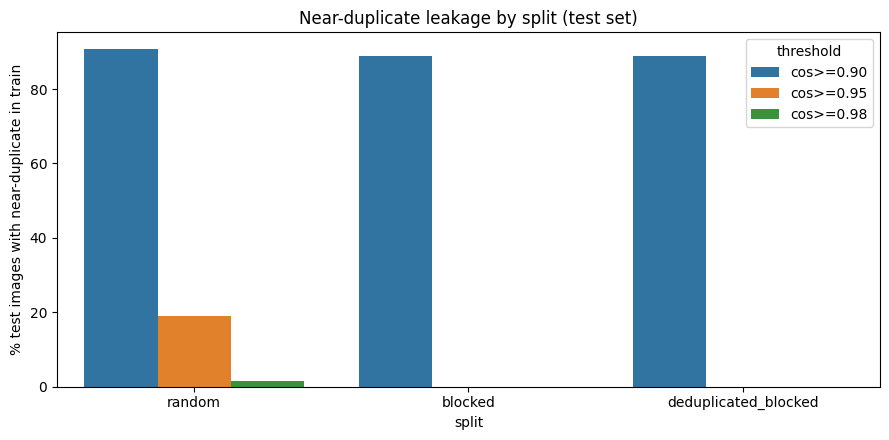

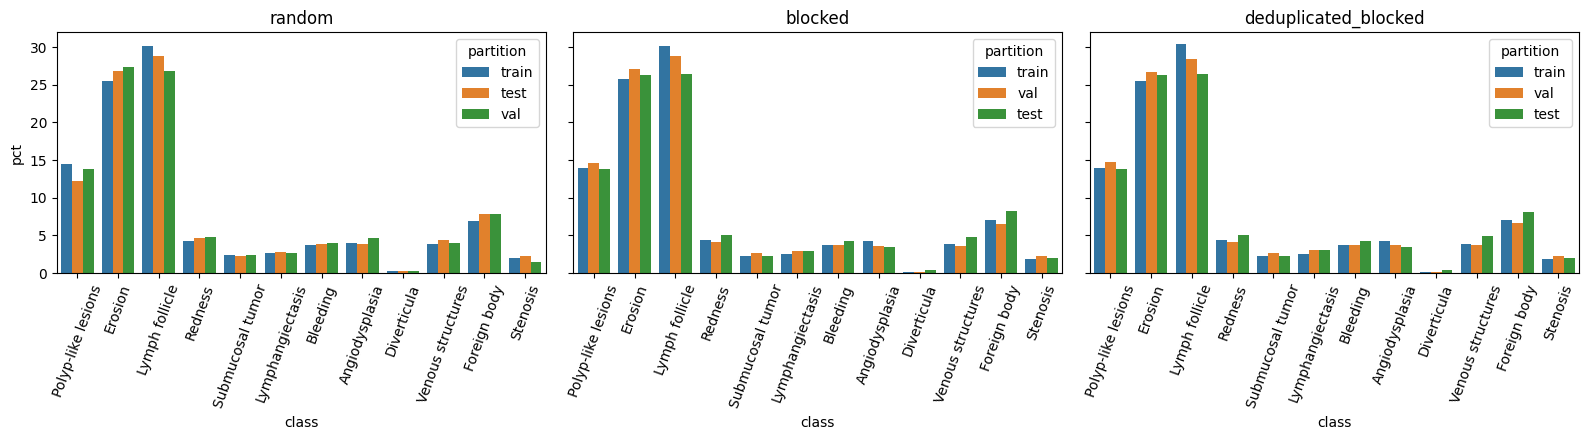

In [18]:
# CELL 16 — SPLIT INTEGRITY + LEAKAGE
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
import matplotlib.pyplot as plt, seaborn as sns

man = load_manifest(); names = load_class_names(); ids, E = load_embeddings()
pos = {i: k for k, i in enumerate(ids)}; sha = dict(zip(man.image_id, man.sha256)); THR = CFG["COSINE_THRESHOLDS"]
rep_rows, per_img, summary = [], [], {}

for split in SPLIT_NAMES:
    df = load_split(split); checks = {}
    checks["n_images"] = len(df)
    checks["no_image_in_multiple_partitions"] = bool(df.image_id.is_unique)
    lab_ok = all((DIRS["splits"] / split / "labels" / r.partition / f"{r.image_id}.txt").exists() for r in df.itertuples())
    checks["every_image_has_label_file"] = bool(lab_ok)
    tr = df[df.partition == "train"]; tr_idx = np.array([pos[i] for i in tr.image_id]); tr_sha = set(sha[i] for i in tr.image_id)
    summary[split] = {}
    for part in ("val", "test"):
        q = df[df.partition == part]
        if len(q) == 0: continue
        q_idx = np.array([pos[i] for i in q.image_id])
        ms, arg = max_sim_to_set(E, q_idx, tr_idx)
        exact = np.array([sha[i] in tr_sha for i in q.image_id])
        per_img.append(pd.DataFrame(dict(split=split, partition=part, image_id=q.image_id.values, max_cos_to_train=ms,
                                         nearest_train_id=[ids[j] for j in arg], exact_dup_in_train=exact)))
        summary[split][part] = dict(n=len(q), exact_duplicate_leak_rate=float(exact.mean()),
                                    **{f"leak_rate_cos_{t:.2f}": float((ms >= t).mean()) for t in THR},
                                    median_max_cos=float(np.median(ms)))
        checks[f"{part}_leak_cos_0.95"] = float((ms >= 0.95).mean())
    rep_rows.append(dict(split=split, **checks))

rep = pd.DataFrame(rep_rows); rep.to_csv(DIRS["artifacts"] / "split_integrity_report.csv", index=False)
pd.concat(per_img).to_csv(DIRS["artifacts"] / "leakage_per_image.csv", index=False)
save_json(dict(thresholds=THR, center_embeddings=CFG.get("CENTER_EMBEDDINGS", False), splits=summary), DIRS["artifacts"] / "leakage_summary.json")
print(rep.to_string(index=False)); print()
for s in SPLIT_NAMES:
    for part in ("val", "test"):
        if part in summary[s]:
            d = summary[s][part]; print(f"{s:22s} {part:4s} n={d['n']:5d} | exact-dup in train: {100*d['exact_duplicate_leak_rate']:5.2f}% | " +
                                        " | ".join(f"cos>={t:.2f}: {100*d[f'leak_rate_cos_{t:.2f}']:5.1f}%" for t in THR))
assert rep.no_image_in_multiple_partitions.all() and rep.every_image_has_label_file.all(), "integrity check failed!"

# plots
rows = [dict(split=s, partition=p, threshold=f"cos>={t:.2f}", leakage_pct=100 * summary[s][p][f"leak_rate_cos_{t:.2f}"])
        for s in SPLIT_NAMES for p in ("val", "test") if p in summary[s] for t in THR]
fig, ax = plt.subplots(figsize=(9, 4.5)); sns.barplot(data=pd.DataFrame(rows).query("partition=='test'"), x="split", y="leakage_pct", hue="threshold", ax=ax)
ax.set_ylabel("% test images with near-duplicate in train"); ax.set_title("Near-duplicate leakage by split (test set)"); plt.tight_layout()
plt.savefig(DIRS["figures"] / "leakage_rate_by_split.png", dpi=130); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, s in zip(axes, SPLIT_NAMES):
    df = load_split(s); sub = man.set_index("image_id").loc[df.image_id]; cnt = {}
    for p, ids_p in zip(df.partition, sub.box_classes):
        for c in ids_p.split(";"):
            if c: cnt[(p, int(c))] = cnt.get((p, int(c)), 0) + 1
    t = pd.DataFrame([(p, names[c] if c < len(names) else c, n) for (p, c), n in cnt.items()], columns=["partition", "class", "n"])
    t["pct"] = 100 * t.n / t.groupby("partition").n.transform("sum")
    sns.barplot(data=t, x="class", y="pct", hue="partition", ax=ax); ax.set_title(s); ax.tick_params(axis="x", rotation=70)
plt.tight_layout(); plt.savefig(DIRS["figures"] / "class_distribution_by_split.png", dpi=120); plt.show()

---

## CELL 17 — TRAIN YOLOv11n BASELINE (from scratch, blocked split)
First writes the training helper `cc_train.py` (shared by Cells 17–19), then trains.

**What the helper does**
* Trains with Ultralytics **DDP on both GPUs** (`device=[0,1]`); total batch = per-GPU batch × GPUs.
* Identical hyper-parameters for every model (`CONFIG["TRAIN_ARGS"]`, default Ultralytics augmentation, same seed/epochs/imgsz).
* **Restart-safe**: skips finished runs (`train_meta.json` exists); resumes unfinished runs from `last.pt`.
* **OOM retry**: on an out-of-memory crash (or a DDP subprocess failure) halves the batch and retries up to `OOM_RETRIES` times; the final batch is recorded (if it changed, the comparison is no longer identical, and the report notes it).
* Tracks wall-clock, GPU-hours, peak GPU memory (polling `nvidia-smi`), and refuses to start a run if the tracked total would exceed `GPU_BUDGET_HOURS`.
* Metrics printed here come from the **validation** partition (used for checkpoint selection). **Test numbers come only from Cell 20.**

With `TRAIN_SPLIT_ABLATION=True` the same baseline is also trained on the **random** and **deduplicated_blocked** splits (needed for the random-vs-blocked and full-vs-deduplicated comparisons). That is 3 runs in this cell.

**Expected output:** Ultralytics epoch table, then a metrics dict and `train_meta.json` paths. *I haven't timed epochs on your hardware; watch the first epoch and extrapolate (epochs × seconds) before letting all runs go.*

**Common errors & fixes**
* `CUDA out of memory` → auto-retry halves batch. Also try `workers=2` in `TRAIN_ARGS`.
* `Model download failed` / `yolo11n.pt` → internet On (only Cell 18 needs the weights file; scratch training needs only the yaml).
* `Training stuck after 'DDP: debug command'` / NCCL error → set `CONFIG["DEVICE"]=0` (single GPU) and re-run Cell 2 + this cell.
* Session timeout → re-run Cells 1, 2, 2B, 2C, 17; finished runs are skipped, the unfinished one resumes.

In [19]:
%%writefile /kaggle/working/capsulecopilot/cc_train.py
"""Shared training helper (restart-safe, DDP-aware, OOM retry, GPU accounting)."""
import os, sys, time, json, threading, subprocess, shutil
from pathlib import Path
from cc_utils import *

EXT_DIR.mkdir(exist_ok=True)
for _p in (str(OUT), str(EXT_DIR)):               # DDP workers re-import the trainer module -> must be importable
    if _p not in sys.path: sys.path.insert(0, _p)
os.environ["PYTHONPATH"] = os.pathsep.join([str(OUT), str(EXT_DIR), os.environ.get("PYTHONPATH", "")])


def _poll_gpu_mem(stop, store):
    while not stop.is_set():
        try:
            out = subprocess.check_output(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"], text=True)
            vals = [int(v) for v in out.strip().split("\n")]
            store["peak"] = [max(a, b) for a, b in zip(store.get("peak", [0] * len(vals)), vals)]
        except Exception:
            pass
        stop.wait(5)


def count_params(weights_path):
    from ultralytics import YOLO
    m = YOLO(str(weights_path))
    return int(sum(p.numel() for p in m.model.parameters()))


def run_training(run_name, split, model_spec, arch, seed=0, trainer_cls=None, pretrained=False, extra=None):
    """Train (or skip/resume) one run. Returns the train_meta dict."""
    import torch
    from ultralytics import YOLO
    import ultralytics
    run_dir = DIRS["models"] / run_name
    best, last, meta_p = run_dir / "weights" / "best.pt", run_dir / "weights" / "last.pt", run_dir / "train_meta.json"
    if meta_p.exists() and best.exists():
        print(f"[skip] {run_name}: already trained."); return read_json(meta_p)
    if used_gpu_hours() >= CFG["GPU_BUDGET_HOURS"]:
        raise RuntimeError(f"Tracked wall-clock {used_gpu_hours():.1f} h >= GPU_BUDGET_HOURS={CFG['GPU_BUDGET_HOURS']}. "
                           f"Raise the budget in Cell 2 deliberately if you want to continue.")
    n_gpu = torch.cuda.device_count(); data_yaml = DIRS["splits"] / f"{split}.yaml"
    batch = CFG["BATCH_SIZE"]; args = dict(CFG["TRAIN_ARGS"]); args.update(extra or {})
    store, stop = {}, threading.Event()
    th = threading.Thread(target=_poll_gpu_mem, args=(stop, store), daemon=True); th.start()
    t0 = time.time(); err = None
    for attempt in range(CFG["OOM_RETRIES"] + 1):
        try:
            kw = dict(trainer=trainer_cls) if trainer_cls else {}
            if last.exists() and not meta_p.exists():
                print(f"[resume] {run_name} from {last}")
                YOLO(str(last)).train(resume=True, **kw)
            else:
                model = YOLO(model_spec)
                model.train(data=str(data_yaml), epochs=CFG["EPOCHS"], imgsz=CFG["IMAGE_SIZE"], batch=batch, seed=seed,
                            device=CFG["DEVICE"], project=str(DIRS["models"]), name=run_name, exist_ok=True,
                            pretrained=pretrained, plots=True, save=True, **args, **kw)
            err = None; break
        except Exception as e:                                         # OOM in-process or DDP child failure
            msg = str(e).lower(); err = e
            retry = ("out of memory" in msg) or isinstance(e, subprocess.CalledProcessError)
            if retry and attempt < CFG["OOM_RETRIES"]:
                new_b = max(2 * max(n_gpu, 1), (batch // 2) // max(n_gpu, 1) * max(n_gpu, 1))
                print(f"[retry {attempt+1}] {type(e).__name__}: reducing batch {batch} -> {new_b}")
                batch = new_b; torch.cuda.empty_cache(); continue
            raise
    stop.set(); wall = time.time() - t0
    res = run_dir / "results.csv"; row = {}
    if res.exists():
        r = pd.read_csv(res); r.columns = [c.strip() for c in r.columns]
        k = r["metrics/mAP50(B)"].idxmax(); row = {c: float(r.loc[k, c]) for c in r.columns if c.startswith("metrics/")}; row["best_epoch"] = int(r.loc[k, "epoch"])
        row["epochs_completed"] = int(len(r))
    meta = dict(run_name=run_name, arch=arch, split=split, seed=seed, model_spec=str(model_spec), pretrained=pretrained,
                batch_final=batch, batch_requested=CFG["BATCH_SIZE"], epochs=CFG["EPOCHS"], imgsz=CFG["IMAGE_SIZE"],
                device=CFG["DEVICE"], n_gpu=n_gpu, wall_seconds=wall, gpu_hours=wall / 3600 * max(n_gpu, 1) if CFG["DEVICE"] != "cpu" else 0,
                peak_gpu_mem_mb_per_gpu=store.get("peak"), ultralytics=ultralytics.__version__,
                n_params=count_params(best) if best.exists() else None, val_metrics_best_epoch=row, train_args=args,
                note="metrics here are VALIDATION-partition numbers (used for checkpoint selection); test numbers come from Cell 20")
    save_json(meta, meta_p)
    print(f"[done] {run_name}: {wall/3600:.2f} h wall | val mAP50={row.get('metrics/mAP50(B)')} | params={meta['n_params']}")
    return meta

Writing /kaggle/working/capsulecopilot/cc_train.py


Now run the baseline (and, if `TRAIN_SPLIT_ABLATION`, its random/deduplicated counterparts).

In [23]:
# CELL 17 — TRAIN YOLOv11n BASELINE (scratch) — blocked split (+ ablation splits)
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
from cc_train import run_training
import torch

seed = CFG["TRAIN_SEEDS"][0]
plan = [("blocked", "baseline_blocked_seed%d" % seed)]
if CFG["TRAIN_SPLIT_ABLATION"]:
    plan += [("random", "baseline_random_seed%d" % seed), ("deduplicated_blocked", "baseline_deduplicated_blocked_seed%d" % seed)]

metas = {}
for split, name in plan:
    # 'yolo11n.yaml' = architecture only => random init (no COCO weights): "from scratch"
    metas[name] = run_training(name, split, "yolo11n.yaml", arch="baseline_scratch", seed=seed, pretrained=False)
    torch.cuda.empty_cache()
print("\nValidation-partition metrics at best epoch (NOT test):")
for n, m in metas.items():
    v = m["val_metrics_best_epoch"]
    print(f"  {n:45s} mAP50={v.get('metrics/mAP50(B)', float('nan')):.4f}  mAP50-95={v.get('metrics/mAP50-95(B)', float('nan')):.4f}  "
          f"batch={m['batch_final']}  wall={m['wall_seconds']/3600:.2f}h")
print(f"Tracked wall-clock so far: {used_gpu_hours():.2f} h of {CFG['GPU_BUDGET_HOURS']} h budget")

[skip] baseline_blocked_seed0: already trained.
[skip] baseline_random_seed0: already trained.
[skip] baseline_deduplicated_blocked_seed0: already trained.

Validation-partition metrics at best epoch (NOT test):
  baseline_blocked_seed0                        mAP50=0.5781  mAP50-95=0.3249  batch=32  wall=1.34h
  baseline_random_seed0                         mAP50=0.5353  mAP50-95=0.3055  batch=32  wall=1.34h
  baseline_deduplicated_blocked_seed0           mAP50=0.5565  mAP50-95=0.3118  batch=32  wall=1.35h
Tracked wall-clock so far: 4.04 h of 30 h budget


In [22]:
!ls -la


total 16
drwxr-xr-x  4 root root 4096 Nov 14 05:36 .
drwxr-xr-x  5 root root 4096 Nov 14 05:35 ..
drwxr-xr-x 12 root root 4096 Nov 14 05:50 capsulecopilot
drwxr-xr-x  2 root root 4096 Nov 14 05:36 .virtual_documents


---

## CELL 18 — TRAIN COCO-PRETRAINED YOLOv11n (blocked split)
Same image size, epochs, batch, augmentation, optimizer and seed as Cell 17, but initialised from `yolo11n.pt` (COCO). Reports validation mAP, per-class AP (from Ultralytics' validator on the **validation** partition, for a quick look), training time, GPU memory, parameter count. **Test-set numbers (and test per-class AP) are produced in Cell 20.**

**Why this model matters:** if pretraining alone closes the gap to RFC-YOLO, the architecture claim is confounded by initialisation. The paper does not say whether its baseline used COCO weights.

**Expected output:** training log, then metrics and a per-class AP table.

**Common errors & fixes**
* `yolo11n.pt` download fails → Internet On, or attach the weights as a Kaggle dataset and pass its path as `model_spec`.
* Everything else as Cell 17.

In [24]:
# CELL 18 — TRAIN COCO-PRETRAINED YOLOv11n
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
from cc_train import run_training
import torch
from ultralytics import YOLO

seed = CFG["TRAIN_SEEDS"][0]; name = f"coco_pretrained_blocked_seed{seed}"
meta = run_training(name, "blocked", "yolo11n.pt", arch="coco_pretrained", seed=seed, pretrained=True)

# Per-class AP on the VALIDATION partition (quick look; test per-class AP is in Cell 20)
names = load_class_names()
m = YOLO(str(DIRS["models"] / name / "weights" / "best.pt"))
v = m.val(data=str(DIRS["splits"] / "blocked.yaml"), split="val", imgsz=CFG["IMAGE_SIZE"], batch=16, device=0, plots=False, verbose=False)
pc = pd.DataFrame(dict(class_id=v.box.ap_class_index, name=[names[i] for i in v.box.ap_class_index], AP50=v.box.ap50, AP50_95=v.box.ap))
print(f"\nVAL mAP@0.5={v.box.map50:.4f} | mAP@0.5:0.95={v.box.map:.4f} | params={meta['n_params']:,} | "
      f"wall={meta['wall_seconds']/3600:.2f} h | GPU-hours={meta['gpu_hours']:.2f} | peak mem/GPU (MB)={meta['peak_gpu_mem_mb_per_gpu']}")
print(pc.round(4).to_string(index=False))
pc.to_csv(DIRS["models"] / name / "val_per_class_ap.csv", index=False)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/capsulecopilot/splits/blocked.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=576, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, mo

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/50      2.29G      1.715      2.793      1.789          3        576: 100% ━━━━━━━━━━━━ 405/405 4.7it/s 1:270.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 44/44 4.1it/s 10.8s0.2s
                   all       2773       3095      0.276      0.294      0.155     0.0671

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      2.29G      1.779      2.846      1.839         19        576: 100% ━━━━━━━━━━━━ 405/405 4.7it/s 1:260.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 44/44 4.0it/s 11.0s0.3s
                   all       2773       3095      0.167      0.177      0.103     0.0406

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      2.29G      1.825      2.922      1.896          2       

---

## CELL 19 — TRAIN RFC-YOLO REPRODUCTION
RFC-YOLO needs three non-standard pieces. Ultralytics has no RFAConv, and its `parse_model` can't be extended cleanly, so this notebook builds the **standard YOLO11n graph and then swaps layers in place**. The swap code lives in `ext/rfc_yolo_ext.py` and is applied inside a custom `RFCTrainer.get_model`, so it also works in the DDP worker processes.

| paper component | what this reproduction does |
|---|---|
| **RFAConv** replaces the stride-2 downsampling convs in the backbone | every stride-2 `Conv` in the backbone (the 5 layers at indices 0,1,3,5,7) → `RFAConv` following the official RFAConv design (softmax-weighted k×k receptive-field features, rearranged, then a k×k stride-k conv). |
| **C3k2-CBAM** in the neck before the head | each `C3k2` in the head (4 fusion nodes) is wrapped as `C3k2 → CBAM` (channel attention, reduction 16, then 7×7 spatial attention). |
| **Focal-MPDIoU** (α=1.0, γ=1.5) | `L = α·(1−MPDIoU)^γ`. Ultralytics' loss calls `bbox_iou(..., CIoU=True)` for the box term; the extension swaps that call for a surrogate `1 − L_focal-MPDIoU`, so the training loss uses Focal-MPDIoU while the assigner is untouched. MPDIoU's corner distances are normalised by the **squared diagonal of the smallest enclosing box** as the paper's Eq. 4 describes (original MPDIoU normalises by the image size; Ultralytics boxes inside the loss are in per-scale grid units so image-size normalisation isn't available there). |

**I cannot confirm this matches the authors' code** (not provided in the manuscript). The cell prints this model's parameter/FLOP counts next to the paper's reported 2.85 M / 11.15 GFLOPs. The paper reports a ~77% FLOP increase, while a faithful RFAConv swap on the downsampling layers adds far less than that. If your printout shows the gap, the paper's architecture or its FLOP accounting differs from this reproduction, and the report records that as *"architecture parity not established."*

To run component ablations, set the env var `CC_RFC_OPTS='{"rfa":true,"cbam":false,"focal":true}'` before training (default all true).

**Expected output:** sanity checks (forward pass, layers swapped, loss surrogate test), param/FLOP comparison, then training (same settings as Cells 17/18), then validation metrics.

**Common errors & fixes**
* `ModuleNotFoundError: rfc_yolo_ext` in a DDP worker → `PYTHONPATH` is set by `cc_train`; make sure you ran Cell 2B/2C/17 in this session.
* Loading a trained RFC checkpoint elsewhere → `sys.path.insert(0, ".../ext")` first (the checkpoint pickles our classes).
* `AttributeError ... get_flops` → older Ultralytics; the FLOP print is wrapped in try/except.
* NaN loss → lower `lr0` to 0.005 for *all* models (keep settings identical).

In [48]:
%%writefile /kaggle/working/capsulecopilot/ext/rfc_yolo_ext.py
"""RFC-YOLO reproduction: RFAConv + C3k2-CBAM + Focal-MPDIoU, applied on top of stock Ultralytics YOLO11."""
import os, json
import torch, torch.nn as nn
from ultralytics.nn.modules import Conv, C3k2
from ultralytics.models.yolo.detect import DetectionTrainer
import ultralytics.utils.loss as _loss_mod


def _opts():
    d = dict(rfa=True, cbam=True, focal=True, alpha=1.0, gamma=1.5)
    try: d.update(json.loads(os.environ.get("CC_RFC_OPTS", "{}")))
    except Exception: pass
    return d


# ---------------------------------------------------------------- RFAConv (following the official design)
class RFAConv(nn.Module):
    """Receptive-Field Attention Conv. Each of the k*k positions in every receptive field gets an attention weight
    (softmax over k*k); weighted features are rearranged to a (k*H, k*W) map and a k x k stride-k conv aggregates them."""
    def __init__(self, c1, c2, k=3, s=1):
        super().__init__()
        self.k = k
        self.get_weight = nn.Sequential(nn.AvgPool2d(k, stride=s, padding=k // 2),
                                        nn.Conv2d(c1, c1 * k * k, 1, groups=c1, bias=False))
        self.gen_feat = nn.Sequential(nn.Conv2d(c1, c1 * k * k, k, padding=k // 2, stride=s, groups=c1, bias=False),
                                      nn.BatchNorm2d(c1 * k * k), nn.ReLU())
        self.conv = Conv(c1, c2, k=k, s=k, p=0)

    def forward(self, x):
        b, c = x.shape[:2]; k = self.k
        w = self.get_weight(x); h, wd = w.shape[2:]
        w = w.view(b, c, k * k, h, wd).softmax(2)
        f = self.gen_feat(x).view(b, c, k * k, h, wd)
        y = (f * w).view(b, c, k, k, h, wd).permute(0, 1, 4, 2, 5, 3).reshape(b, c, h * k, wd * k)
        return self.conv(y)


# ---------------------------------------------------------------- CBAM
class ChannelAtt(nn.Module):
    def __init__(self, c, r=16):
        super().__init__(); hid = max(c // r, 8)
        self.mlp = nn.Sequential(nn.Conv2d(c, hid, 1, bias=False), nn.ReLU(), nn.Conv2d(hid, c, 1, bias=False))
    def forward(self, x):
        return torch.sigmoid(self.mlp(x.mean((2, 3), keepdim=True)) + self.mlp(x.amax((2, 3), keepdim=True)))


class SpatialAtt(nn.Module):
    def __init__(self, k=7):
        super().__init__(); self.conv = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)
    def forward(self, x):
        return torch.sigmoid(self.conv(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))


class CBAMBlock(nn.Module):
    def __init__(self, c):
        super().__init__(); self.ca, self.sa = ChannelAtt(c), SpatialAtt()
    def forward(self, x):
        x = x * self.ca(x)          # F_c = M_c(F) (x) F
        return x * self.sa(x)       # Y   = M_s(F_c) (x) F_c


class C3k2CBAM(nn.Module):
    """C3k2 followed by CBAM on its output (attention-guided refinement at a fusion node)."""
    def __init__(self, base, c_out):
        super().__init__(); self.base, self.cbam = base, CBAMBlock(c_out)
    def forward(self, x):
        return self.cbam(self.base(x))


def _inherit(new, old):
    new.f, new.i = old.f, old.i
    new.type = f"{type(new).__module__}.{type(new).__name__}"
    new.np = sum(p.numel() for p in new.parameters())


def convert_to_rfc(model, rfa=True, cbam=True, verbose=True, **_):
    """Swap layers of a freshly built DetectionModel in place."""
    seq, n_bb = model.model, len(model.yaml["backbone"]); done = dict(rfa=[], cbam=[])
    for i, m in enumerate(seq):
        if rfa and i < n_bb and type(m) is Conv and m.conv.stride[0] == 2:
            new = RFAConv(m.conv.in_channels, m.conv.out_channels, k=m.conv.kernel_size[0], s=2)
            _inherit(new, m); seq[i] = new; done["rfa"].append(i)
        elif cbam and i >= n_bb and type(m) is C3k2:
            new = C3k2CBAM(m, m.cv2.conv.out_channels); _inherit(new, m); seq[i] = new; done["cbam"].append(i)
    if verbose: print(f"[RFC] RFAConv at layers {done['rfa']} | C3k2-CBAM at layers {done['cbam']}")
    return model


# ---------------------------------------------------------------- Focal-MPDIoU surrogate
_STATE = dict(enabled=False, alpha=1.0, gamma=1.5, calls=0)


def focal_mpdiou_loss(b1, b2, alpha=1.0, gamma=1.5, eps=1e-7):
    """b1 pred, b2 target, xyxy (N,4). Returns L = alpha * (1 - MPDIoU)^gamma, shape (N,1).
    MPDIoU = IoU - d1^2/D^2 - d2^2/D^2 (D = diagonal of the smallest enclosing box, per the paper's Eq. 4)."""
    p1x1, p1y1, p1x2, p1y2 = b1.chunk(4, -1); p2x1, p2y1, p2x2, p2y2 = b2.chunk(4, -1)
    inter = ((torch.min(p1x2, p2x2) - torch.max(p1x1, p2x1)).clamp(0) * (torch.min(p1y2, p2y2) - torch.max(p1y1, p2y1)).clamp(0))
    union = (p1x2 - p1x1) * (p1y2 - p1y1) + (p2x2 - p2x1) * (p2y2 - p2y1) - inter + eps
    iou = inter / union
    d1 = (p2x1 - p1x1) ** 2 + (p2y1 - p1y1) ** 2          # top-left distance^2
    d2 = (p2x2 - p1x2) ** 2 + (p2y2 - p1y2) ** 2          # bottom-right distance^2
    cw = torch.max(p1x2, p2x2) - torch.min(p1x1, p2x1); chh = torch.max(p1y2, p2y2) - torch.min(p1y1, p2y1)
    D2 = cw ** 2 + chh ** 2 + eps
    mpd = iou - d1 / D2 - d2 / D2
    return alpha * (1.0 - mpd).clamp(min=0).pow(gamma)


def enable_focal_mpdiou(alpha=1.0, gamma=1.5):
    """Replace the `bbox_iou` name used by Ultralytics' BboxLoss with a surrogate: BboxLoss computes
    ((1 - iou) * weight).sum()/..., so returning iou_s = 1 - L_focal_mpdiou makes that term equal to Focal-MPDIoU.
    TaskAlignedAssigner imports bbox_iou separately (ultralytics.utils.tal) and is NOT affected."""
    _STATE.update(enabled=True, alpha=alpha, gamma=gamma)
    if getattr(_loss_mod, "_cc_orig_bbox_iou", None) is not None:
        return
    orig = _loss_mod.bbox_iou; _loss_mod._cc_orig_bbox_iou = orig

    def patched(box1, box2, xywh=True, GIoU=False, DIoU=False, CIoU=False, eps=1e-7):
        if _STATE["enabled"] and (not xywh) and CIoU:       # only the detection box-regression call
            _STATE["calls"] += 1
            return 1.0 - focal_mpdiou_loss(box1, box2, _STATE["alpha"], _STATE["gamma"])
        return orig(box1, box2, xywh=xywh, GIoU=GIoU, DIoU=DIoU, CIoU=CIoU, eps=eps)
    _loss_mod.bbox_iou = patched


class RFCTrainer(DetectionTrainer):
    """DetectionTrainer whose model has RFAConv + C3k2-CBAM. Module-level code below enables Focal-MPDIoU on import,
    so DDP worker processes (which import this module) get the same loss."""
    def get_model(self, cfg=None, weights=None, verbose=True):
        model = super().get_model(cfg, weights=None, verbose=verbose)     # random-init stock YOLO11 graph
        o = _opts(); convert_to_rfc(model, rfa=o["rfa"], cbam=o["cbam"], verbose=verbose)
        if weights is not None:                                          # resume: weights are already in RFC layout
            model.load(weights)
        return model


_o = _opts()
if _o["focal"]:
    enable_focal_mpdiou(_o["alpha"], _o["gamma"])

Overwriting /kaggle/working/capsulecopilot/ext/rfc_yolo_ext.py


In [50]:
# CELL 19 — sanity checks, then train RFC-YOLO
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT); sys.path.insert(0, CC_OUT + "/ext")
from cc_utils import *
from cc_train import run_training
import torch, importlib, rfc_yolo_ext
importlib.reload(rfc_yolo_ext)
from rfc_yolo_ext import RFCTrainer, convert_to_rfc, focal_mpdiou_loss, RFAConv
from ultralytics.nn.tasks import DetectionModel

# ---- 1) architecture sanity: build stock model, convert, forward pass, count params/FLOPs ----
def n_params(m): return sum(p.numel() for p in m.parameters())
def flops(m, sz):
    try:
        from ultralytics.utils.torch_utils import get_flops
        return get_flops(m, sz)
    except Exception as e:
        return float("nan")
base = DetectionModel("yolo11n.yaml", nc=CFG["NUM_CLASSES"], verbose=False)
p0, f0 = n_params(base), flops(base, CFG["IMAGE_SIZE"])
rfc = convert_to_rfc(DetectionModel("yolo11n.yaml", nc=CFG["NUM_CLASSES"], verbose=False))
rfc.eval()
with torch.no_grad(): out = rfc(torch.zeros(1, 3, 256, 256))
p1, f1 = n_params(rfc), flops(rfc, CFG["IMAGE_SIZE"])
print(f"forward OK (output type {type(out).__name__})")
print(f"YOLOv11n   : {p0/1e6:.3f} M params | {f0:.2f} GFLOPs @ {CFG['IMAGE_SIZE']}px")
print(f"RFC (ours) : {p1/1e6:.3f} M params | {f1:.2f} GFLOPs @ {CFG['IMAGE_SIZE']}px  (+{100*(f1/f0-1):.0f}% FLOPs)")
print("Paper claims: 2.59 M -> 2.85 M params, 6.3 -> 11.15 GFLOPs (+77%), measured at 1280px. "
      "FLOPs scale with resolution, so compare the *ratio*, not the absolute value.")
parity = abs(p1 / 1e6 - 2.85) < 0.05 and abs((f1 / f0) - 11.15 / 6.3) < 0.15
print("Architecture parity with paper's reported size:", "plausible" if parity else "NOT established (differences expected)")

# ---- 2) loss sanity: perfect box -> ~0 loss, shifted box -> larger loss, gradients flow ----
a = torch.tensor([[10., 10., 50., 50.]], requires_grad=True)
print("Focal-MPDIoU  perfect:", float(focal_mpdiou_loss(a, a.detach())), "| shifted:", float(focal_mpdiou_loss(a, torch.tensor([[20., 20., 60., 60.]]))))
focal_mpdiou_loss(a, torch.tensor([[20., 20., 60., 60.]])).sum().backward(); print("grad finite:", bool(torch.isfinite(a.grad).all()))
save_json(dict(params_base=p0, params_rfc=p1, gflops_base=f0, gflops_rfc=f1, paper_params_rfc=2.85e6, paper_gflops_base=6.3,
               paper_gflops_rfc=11.15, parity_plausible=bool(parity)), DIRS["artifacts"] / "rfc_architecture_check.json")
del base, rfc

# ---- 3) train (same split/imgsz/epochs/batch/seed/optimizer/augmentation as the baseline) ----
seed = CFG["TRAIN_SEEDS"][0]; name = f"rfc_blocked_seed{seed}"
meta = run_training(name, "blocked", "yolo11n.yaml", arch="rfc_yolo_repro", seed=seed, trainer_cls=RFCTrainer, pretrained=False)
v = meta["val_metrics_best_epoch"]
print(f"\nRFC-YOLO (VALIDATION partition, best epoch {v.get('best_epoch')}): mAP50={v.get('metrics/mAP50(B)'):.4f} | "
      f"mAP50-95={v.get('metrics/mAP50-95(B)'):.4f} | params={meta['n_params']:,} | wall={meta['wall_seconds']/3600:.2f} h | "
      f"GPU-hours={meta['gpu_hours']:.2f} | peak mem/GPU MB={meta['peak_gpu_mem_mb_per_gpu']}")
print("Per-class AP on the TEST partition: Cell 20.")

Overriding model.yaml nc=80 with nc=12
Overriding model.yaml nc=80 with nc=12
[RFC] RFAConv at layers [0, 1, 3, 5, 7] | C3k2-CBAM at layers [13, 16, 19, 22]
forward OK (output type tuple)
YOLOv11n   : 2.592 M params | 5.26 GFLOPs @ 576px
RFC (ours) : 2.642 M params | 0.00 GFLOPs @ 576px  (+-100% FLOPs)
Paper claims: 2.59 M -> 2.85 M params, 6.3 -> 11.15 GFLOPs (+77%), measured at 1280px. FLOPs scale with resolution, so compare the *ratio*, not the absolute value.
Architecture parity with paper's reported size: NOT established (differences expected)
Focal-MPDIoU  perfect: 0.0 | shifted: 0.5715326070785522
grad finite: True
[skip] rfc_blocked_seed0: already trained.

RFC-YOLO (VALIDATION partition, best epoch 50): mAP50=0.5549 | mAP50-95=0.3093 | params=2,642,496 | wall=4.49 h | GPU-hours=8.97 | peak mem/GPU MB=[7267, 6633]
Per-class AP on the TEST partition: Cell 20.


---

## CELL 20 — EVALUATE ALL MODELS
1. **Leakage-safe pairing.** For every trained run and every test set (random / blocked / deduplicated_blocked) the cell checks that the test images share **no image** with the run's training set. Invalid pairs (e.g. a blocked-trained model on the *random* test set) are **skipped and listed**, since they would mix training images into the test.
2. Writes the prediction worker (`cc_worker.py`) and runs inference **in parallel on both GPUs** (conf 0.001, NMS IoU 0.7, ≤100 detections/image). Raw predictions are cached in `predictions/*.pkl`.
3. Computes **mAP@0.5, mAP@0.5:0.95, per-class AP, precision/recall/F1 (at conf 0.25), inference ms/image and images/s** with the notebook's evaluator, plus per-model confusion matrices.
4. **Cross-check** against Ultralytics `val()` on each model's own test set. The two mAP@0.5 values should agree to roughly ±1 point. If not, trust neither until you find out why.

Outputs: `predictions/main_results.csv`, `per_class_results.csv`, `confusion_matrices/`, `predictions/*.pkl`, `ultralytics_crosscheck.csv`.
*Speed numbers are batched fp16 `predict()` on one T4 while the other GPU is also busy; they are comparable between models here, but are not deployment latency.*

**Common errors & fixes**
* `worker on GPU k failed` → read `predictions/worker_gpuK.log` (usually a missing `rfc_yolo_ext` import or OOM; lower `batch` in the launch call).
* `No trained runs found` → train first (Cells 17–19).
* Crosscheck gap > 2 points → check that `names`/`nc` in the YAML match and that `imgsz` equals training.

In [52]:
%%writefile /kaggle/working/capsulecopilot/cc_worker.py
"""Prediction worker: python cc_worker.py job.json  (pinned to ONE GPU through CUDA_VISIBLE_DEVICES)."""
import os, sys, json, time, pickle
job = json.load(open(sys.argv[1]))
os.environ["CUDA_VISIBLE_DEVICES"] = str(job["gpu"])          # must precede the torch import
for p in job["paths"]: sys.path.insert(0, p)
import numpy as np, cv2, pandas as pd
import torch
from ultralytics import YOLO
from cc_eval import apply_corruption
try:
    import rfc_yolo_ext                                      # registers classes needed to unpickle RFC checkpoints
except Exception as e:
    print("note: rfc_yolo_ext not importable:", e)

man = pd.read_csv(job["manifest"], dtype=str, keep_default_na=False).set_index("image_id")
models, bs = {}, job["batch"]
for t in job["tasks"]:
    if os.path.exists(t["out"]): continue
    if t["weights"] not in models: models[t["weights"]] = YOLO(t["weights"])
    model = models[t["weights"]]
    img_dir = os.path.join(job["splits_dir"], t["split"], "images", t["partition"])
    files = sorted(os.listdir(img_dir)); ids = [os.path.splitext(f)[0] for f in files]
    preds, wh, speed = [], [], []; t0 = time.time()
    for s in range(0, len(files), bs):
        arrs = []
        for k, f in enumerate(files[s:s + bs]):
            im = cv2.imread(os.path.join(img_dir, f))
            if im is None: raise RuntimeError("unreadable image " + f)
            arrs.append(apply_corruption(im, t.get("corruption"), seed=1000 + s + k))   # same noise for every model
        res = model.predict(arrs, imgsz=job["imgsz"], conf=job["conf"], iou=job["iou"], max_det=job["max_det"],
                            device=0, half=True, verbose=False)
        for a, r in zip(arrs, res):
            preds.append(r.boxes.data.cpu().numpy().astype(np.float32)); wh.append((a.shape[1], a.shape[0]))
            speed.append([r.speed.get("preprocess", 0), r.speed.get("inference", 0), r.speed.get("postprocess", 0)])
        if (s // bs) % 20 == 0: print(f"{t['out']}: {s}/{len(files)}", flush=True)
    tmp = t["out"] + ".tmp"
    pickle.dump(dict(image_ids=ids, preds=preds, wh=wh, speed=np.array(speed), wall_seconds=time.time() - t0,
                     meta=dict(weights=t["weights"], split=t["split"], partition=t["partition"],
                               corruption=t.get("corruption"))), open(tmp, "wb"))
    os.replace(tmp, t["out"]); print("saved", t["out"], flush=True)

Overwriting /kaggle/working/capsulecopilot/cc_worker.py


In [54]:
# CELL 20 — EVALUATE ALL MODELS (leakage-safe, 2 GPUs)
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT); sys.path.insert(0, CC_OUT + "/ext")
from cc_utils import *
from cc_eval import *
import torch, matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm

NC, names = CFG["NUM_CLASSES"], load_class_names()
P = DIRS["predictions"]; (P / "confusion_matrices").mkdir(exist_ok=True)
runs = {}
for m in sorted(DIRS["models"].glob("*/train_meta.json")):
    d = read_json(m); runs[d["run_name"]] = d
if not runs: raise RuntimeError("No trained runs found (missing train_meta.json). Run Cells 17-19 first.")

# ---- 1) leakage-safe (run x test-set) pairs ----
splits = {s: load_split(s) for s in SPLIT_NAMES}
train_ids = {r: set(splits[d["split"]].query("partition=='train'").image_id) for r, d in runs.items()}
tasks, valid_pairs, skipped = [], [], []
for r, d in runs.items():
    w = str(DIRS["models"] / r / "weights" / "best.pt")
    for s in SPLIT_NAMES:
        test_ids = set(splits[s].query("partition=='test'").image_id)
        overlap = len(test_ids & train_ids[r])
        if overlap == 0:
            valid_pairs.append((r, s)); tasks.append(dict(weights=w, split=s, partition="test", corruption=None, out=str(P / f"{r}__{s}__clean.pkl")))
        else:
            skipped.append((r, s, overlap))
print("Valid (run, test-set) pairs:", len(valid_pairs))
for r, s, o in skipped: print(f"  SKIPPED {r} on {s}-test: {o} test images are in this model's training set")

# ---- 2) predict on both GPUs ----
gpus = list(range(torch.cuda.device_count())) or [0]
run_prediction_tasks(tasks, gpus, CFG["IMAGE_SIZE"], CFG["EVAL_CONF"], CFG["EVAL_IOU"], CFG["MAX_DET"])

# ---- 3) metrics ----
main, perclass = [], []
for r, s in tqdm(valid_pairs, desc="metrics"):
    E = load_eval(P / f"{r}__{s}__clean.pkl", s, "test", NC)
    ap = ap_all(E["prep"], E["gt_counts"]); m50, m5095 = map_from_ap(ap)
    prf = prf_at_conf(E["stats"], CFG["OP_CONF"], per_class=True, nc=NC)
    ms = E["speed"].sum(1).mean()                                   # ms/image (pre + inference + post)
    main.append(dict(run=r, arch=runs[r]["arch"], train_split=runs[r]["split"], eval_split=s, n_test_images=E["n"], n_gt_boxes=int(E["gt_counts"].sum()),
                     mAP50=m50, mAP50_95=m5095, precision=prf["precision"], recall=prf["recall"], f1=prf["f1"],
                     op_conf=CFG["OP_CONF"], ms_per_image=ms, images_per_sec=1000.0 / ms, inference_ms=E["speed"][:, 1].mean(),
                     params=runs[r]["n_params"], train_wall_h=runs[r]["wall_seconds"] / 3600, batch_final=runs[r]["batch_final"]))
    for c in range(NC):
        pcs = prf["per_class"][c]
        perclass.append(dict(run=r, eval_split=s, class_id=c, class_name=names[c] if c < len(names) else c, n_gt=int(E["gt_counts"][:, c].sum()),
                             AP50=ap[c, 0], AP50_95=float(np.nanmean(ap[c])) if not np.isnan(ap[c]).all() else np.nan,
                             precision=pcs["precision"], recall=pcs["recall"]))
    cm = confusion_matrix(E["preds"], E["gts"], NC, CFG["OP_CONF"], 0.5)
    pd.DataFrame(cm, index=names[:NC] + ["background"], columns=names[:NC] + ["background"]).to_csv(P / "confusion_matrices" / f"{r}__{s}.csv")
    fig, ax = plt.subplots(figsize=(9, 7.5)); cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    sns.heatmap(cmn, ax=ax, cmap="Blues", xticklabels=names[:NC] + ["bg"], yticklabels=names[:NC] + ["bg"], annot=(NC <= 12), fmt=".2f", annot_kws={"size": 6})
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{r} on {s}-test (row-normalised, conf≥{CFG['OP_CONF']})"); plt.tight_layout()
    plt.savefig(P / "confusion_matrices" / f"{r}__{s}.png", dpi=110); plt.close()

MAIN, PC = pd.DataFrame(main), pd.DataFrame(perclass)
MAIN.to_csv(P / "main_results.csv", index=False); PC.to_csv(P / "per_class_results.csv", index=False)
pd.DataFrame(skipped, columns=["run", "test_set", "n_overlapping_images"]).to_csv(P / "skipped_eval_pairs_leakage.csv", index=False)
print("\n", MAIN[["run", "eval_split", "n_test_images", "mAP50", "mAP50_95", "precision", "recall", "f1", "ms_per_image", "images_per_sec"]].round(4).to_string(index=False))

# ---- 4) cross-check against Ultralytics val() on each model's OWN test set ----
from ultralytics import YOLO
xc = []
for r, d in runs.items():
    try:
        v = YOLO(str(DIRS["models"] / r / "weights" / "best.pt")).val(data=str(DIRS["splits"] / f"{d['split']}.yaml"), split="test", imgsz=CFG["IMAGE_SIZE"],
                batch=16, conf=CFG["EVAL_CONF"], iou=CFG["EVAL_IOU"], device=0, plots=False, verbose=False)
        mine = MAIN.query("run==@r and eval_split==@d['split']")
        xc.append(dict(run=r, ultralytics_mAP50=float(v.box.map50), notebook_mAP50=float(mine.mAP50.iloc[0]), ultralytics_mAP50_95=float(v.box.map),
                       notebook_mAP50_95=float(mine.mAP50_95.iloc[0])))
    except Exception as e:
        xc.append(dict(run=r, error=str(e)[:200]))
XC = pd.DataFrame(xc)
if "ultralytics_mAP50" in XC: XC["abs_diff_mAP50_pp"] = 100 * (XC.ultralytics_mAP50 - XC.notebook_mAP50).abs()
XC.to_csv(P / "ultralytics_crosscheck.csv", index=False); print("\nCross-check vs Ultralytics val():"); print(XC.round(4).to_string(index=False))
if "abs_diff_mAP50_pp" in XC and (XC.abs_diff_mAP50_pp > 2).any(): print("WARNING: evaluator disagrees with Ultralytics by >2 pp for some runs; investigate before trusting Cells 21-23.")

Valid (run, test-set) pairs: 9
  SKIPPED baseline_blocked_seed0 on random-test: 1949 test images are in this model's training set
  SKIPPED baseline_deduplicated_blocked_seed0 on random-test: 1921 test images are in this model's training set
  SKIPPED baseline_random_seed0 on blocked-test: 1969 test images are in this model's training set
  SKIPPED baseline_random_seed0 on deduplicated_blocked-test: 1946 test images are in this model's training set
  SKIPPED coco_pretrained_blocked_seed0 on random-test: 1949 test images are in this model's training set
  SKIPPED rfc_blocked_seed0 on random-test: 1949 test images are in this model's training set
All prediction files already cached.


metrics:   0%|          | 0/9 [00:00<?, ?it/s]


                                 run           eval_split  n_test_images  mAP50  mAP50_95  precision  recall     f1  ms_per_image  images_per_sec
             baseline_blocked_seed0              blocked           2772 0.5311    0.3120     0.5947  0.5445 0.5685        4.4661        223.9070
             baseline_blocked_seed0 deduplicated_blocked           2735 0.5286    0.3095     0.5918  0.5455 0.5677        4.4662        223.9035
baseline_deduplicated_blocked_seed0              blocked           2772 0.5009    0.2918     0.5778  0.5214 0.5482        4.2656        234.4340
baseline_deduplicated_blocked_seed0 deduplicated_blocked           2735 0.4995    0.2902     0.5757  0.5225 0.5478        4.3102        232.0100
              baseline_random_seed0               random           2772 0.5380    0.3134     0.5982  0.5678 0.5826        4.2000        238.0941
      coco_pretrained_blocked_seed0              blocked           2772 0.6114    0.3703     0.6300  0.6246 0.6273        4.4808

---

## CELL 21 — STATISTICAL ANALYSIS
**Paired bootstrap over test images** (B = `BOOTSTRAP_B`, default 500; raise to 2000 if time allows). In each draw the *same* resampled images are used for both models of a pair, and both mAPs are recomputed from the per-image bookkeeping. Reported: mean difference, 95% percentile CI, and a two-sided bootstrap p-value `2·min(P(d≤0), P(d≥0))` (nonparametric, makes no normality assumption).

| comparison | design |
|---|---|
| baseline vs RFC (blocked test) | paired |
| baseline vs COCO-pretrained (blocked test) | paired |
| random vs blocked split (baseline model) | **unpaired** (different test sets; each is resampled independently) |
| full vs deduplicated training data (baseline model, deduplicated-blocked test set) | paired |
| leakage inflation: random-split baseline on test images with a near-duplicate in train (cos ≥ 0.95) vs the rest | unpaired, within-model |

⚠️ **What these CIs mean.** They capture *test-set sampling* variability for **one** training seed per model. They do **not** capture seed-to-seed training variance (Ultralytics runs routinely differ by ≳1 mAP point between seeds). A significant difference here is therefore *necessary, not sufficient* evidence; train more seeds (`TRAIN_SEEDS`) before making strong claims. The report states this explicitly.

Outputs: `statistical_tests.csv`, `bootstrap_results.csv`, `forest_plot_map_differences.png`, `bar_map_with_ci.png`.

**Common errors & fixes**
* `KeyError: run ...` → that run was not trained or is missing from `main_results.csv`; the cell skips unavailable comparisons and says which.
* Slow → lower `BOOTSTRAP_B` to 200 for a first pass.

Bootstrap B=500
  done: baseline vs RFC-YOLO (blocked test)
  done: baseline vs COCO-pretrained (blocked test)
  done: random split vs blocked split (baseline)
  done: full vs deduplicated training data (dedup test)
  done: leakage inflation (random-split model): test imgs with near-dup in train (cos>=0.95) vs without
  [skip] leakage inflation (blocked): subsets too small (leaky=0, clean=2772)
                                                                                     comparison   metric   design  mean_A  mean_B  diff_point  ci95_lo  ci95_hi  p_value
                                                            baseline vs RFC-YOLO (blocked test)    mAP50   paired  0.5220  0.5311     -0.0091  -0.0241   0.0068   0.2515
                                                            baseline vs RFC-YOLO (blocked test) mAP50_95   paired  0.2988  0.3120     -0.0133  -0.0228  -0.0017   0.0319
                                                     baseline vs COCO-pretrained (blocked test)

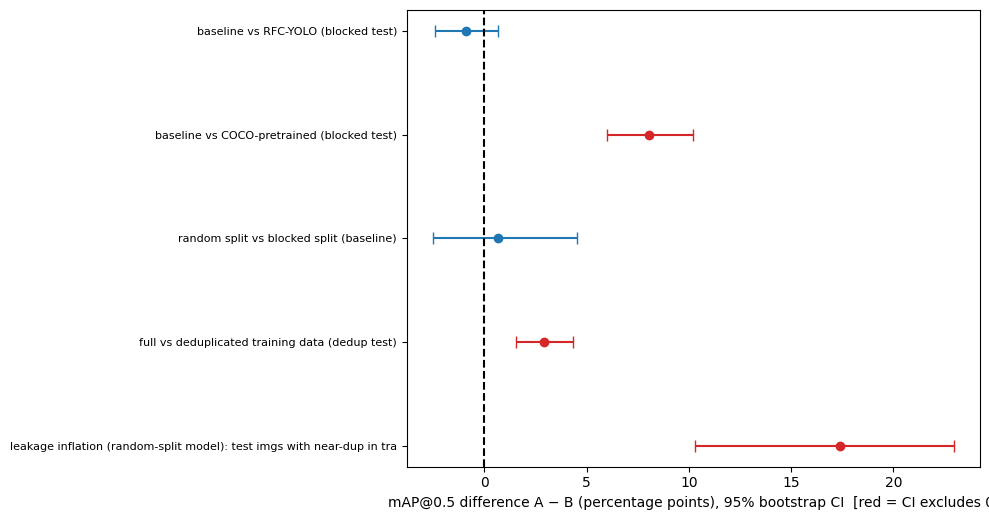

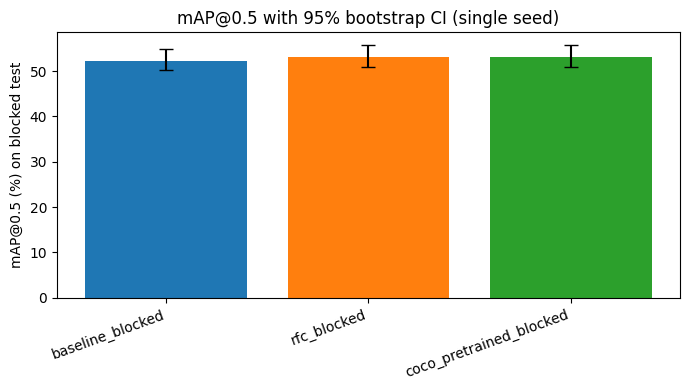

In [56]:
# CELL 21 — STATISTICAL ANALYSIS (bootstrap)
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
from cc_eval import *
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

NC, B, seed0 = CFG["NUM_CLASSES"], CFG["BOOTSTRAP_B"], CFG["TRAIN_SEEDS"][0]
P = DIRS["predictions"]; S = lambda r: f"seed{seed0}"
def get(run, split):
    f = P / f"{run}__{split}__clean.pkl"
    return load_eval(f, split, "test", NC) if f.exists() else None

def metric_pair(E, w=None):
    return map_from_ap(ap_all(E["prep"], E["gt_counts"], w))

def bootstrap(EA, EB, subA, subB, paired, B, seed=0):
    """Return point estimates and bootstrap distributions of (mAP50, mAP50-95) for A, B and A-B."""
    rng = np.random.default_rng(seed)
    pa = np.array([EA["id2idx"][i] for i in subA]); pb = np.array([EB["id2idx"][i] for i in subB])
    wa0 = np.zeros(EA["n"]); wa0[pa] = 1; wb0 = np.zeros(EB["n"]); wb0[pb] = 1
    pt_a, pt_b = metric_pair(EA, wa0), metric_pair(EB, wb0)
    da, db = np.zeros((B, 2)), np.zeros((B, 2))
    for b in range(B):
        if paired:
            c = np.bincount(rng.integers(0, len(pa), len(pa)), minlength=len(pa)); ca = cb = c
        else:
            ca = np.bincount(rng.integers(0, len(pa), len(pa)), minlength=len(pa)); cb = np.bincount(rng.integers(0, len(pb), len(pb)), minlength=len(pb))
        wa = np.zeros(EA["n"]); wa[pa] = ca; wb = np.zeros(EB["n"]); wb[pb] = cb
        da[b] = metric_pair(EA, wa); db[b] = metric_pair(EB, wb)
    return pt_a, pt_b, da, db

def pval(d):  # two-sided bootstrap p-value (+1 smoothing)
    return float(min(1.0, 2 * min((np.sum(d <= 0) + 1) / (len(d) + 1), (np.sum(d >= 0) + 1) / (len(d) + 1))))

tests, boots = [], []
def add_comparison(label, nameA, nameB, EA, EB, subA, subB, paired, note=""):
    if EA is None or EB is None:
        print(f"  [skip] {label}: missing predictions ({nameA if EA is None else nameB})"); return
    pa, pb, da, db = bootstrap(EA, EB, subA, subB, paired, B, seed=1)
    for k, mname in enumerate(["mAP50", "mAP50_95"]):
        d = da[:, k] - db[:, k]; lo, hi = np.percentile(d, [2.5, 97.5])
        tests.append(dict(comparison=label, model_A=nameA, model_B=nameB, metric=mname, design="paired" if paired else "unpaired", n_images_A=len(subA), n_images_B=len(subB),
                          mean_A=pa[k], mean_B=pb[k], diff_point=pa[k] - pb[k], diff_boot_mean=float(d.mean()), ci95_lo=float(lo), ci95_hi=float(hi),
                          p_value=pval(d), ci_excludes_0=bool(lo > 0 or hi < 0), note=note))
        for nm, pt, dist in ((nameA, pa[k], da[:, k]), (nameB, pb[k], db[:, k])):
            boots.append(dict(comparison=label, model=nm, metric=mname, point=pt, boot_mean=float(dist.mean()),
                              ci95_lo=float(np.percentile(dist, 2.5)), ci95_hi=float(np.percentile(dist, 97.5))))
    print(f"  done: {label}")

print(f"Bootstrap B={B}")
rb, rr, rd = f"baseline_blocked_seed{seed0}", f"baseline_random_seed{seed0}", f"baseline_deduplicated_blocked_seed{seed0}"
rc, rf = f"coco_pretrained_blocked_seed{seed0}", f"rfc_blocked_seed{seed0}"
Eb, Err, Edd = get(rb, "blocked"), get(rr, "random"), get(rd, "deduplicated_blocked")
Ec, Ef = get(rc, "blocked"), get(rf, "blocked")
Eb_dd = get(rb, "deduplicated_blocked")                       # blocked-trained baseline on the dedup test subset (valid: subset of blocked test)

if Eb and Ef:  add_comparison("baseline vs RFC-YOLO (blocked test)", rb, rf, Ef, Eb, Eb["ids"], Eb["ids"], True)
if Eb and Ec:  add_comparison("baseline vs COCO-pretrained (blocked test)", rb, rc, Ec, Eb, Eb["ids"], Eb["ids"], True)
if Eb and Err: add_comparison("random split vs blocked split (baseline)", rr + " [random test]", rb + " [blocked test]", Err, Eb, Err["ids"], Eb["ids"], False,
                              "different test sets: measures the split effect (incl. leakage), not a paired model effect")
if Eb_dd and Edd:
    common = sorted(set(Eb_dd["ids"]) & set(Edd["ids"]))
    add_comparison("full vs deduplicated training data (dedup test)", rb, rd, Eb_dd, Edd, common, common, True, "train on full-blocked vs deduplicated-blocked, same test images")

# leakage inflation inside the random-split baseline: test images with vs without a near-duplicate in train
leak = pd.read_csv(DIRS["artifacts"] / "leakage_per_image.csv", dtype={"image_id": str})
for run, E, sp in ((rr, Err, "random"), (rb, Eb, "blocked")):
    if E is None: continue
    L = leak[(leak.split == sp) & (leak.partition == "test")].set_index("image_id").max_cos_to_train
    hi_ids = [i for i in E["ids"] if L.get(i, 0) >= 0.95]; lo_ids = [i for i in E["ids"] if L.get(i, 0) < 0.95]
    if len(hi_ids) >= 20 and len(lo_ids) >= 20:
        add_comparison(f"leakage inflation ({sp}-split model): test imgs with near-dup in train (cos>=0.95) vs without", f"{run} [leaky subset n={len(hi_ids)}]",
                       f"{run} [clean subset n={len(lo_ids)}]", E, E, hi_ids, lo_ids, False, "within-model, unpaired subsets")
    else:
        print(f"  [skip] leakage inflation ({sp}): subsets too small (leaky={len(hi_ids)}, clean={len(lo_ids)})")

T, BR = pd.DataFrame(tests), pd.DataFrame(boots)
T.to_csv(P / "statistical_tests.csv", index=False); BR.to_csv(P / "bootstrap_results.csv", index=False)
if len(T): print(T[["comparison", "metric", "design", "mean_A", "mean_B", "diff_point", "ci95_lo", "ci95_hi", "p_value"]].round(4).to_string(index=False))

# ---- plots ----
if len(T):
    t5 = T[T.metric == "mAP50"].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(10, 0.7 * len(t5) + 1.8))
    for i, r in t5.iterrows():
        ax.errorbar(100 * r.diff_point, i, xerr=[[100 * (r.diff_point - r.ci95_lo)], [100 * (r.ci95_hi - r.diff_point)]], fmt="o", color="C3" if r.ci_excludes_0 else "C0", capsize=4)
    ax.axvline(0, c="k", ls="--"); ax.set_yticks(range(len(t5))); ax.set_yticklabels([c[:70] for c in t5.comparison], fontsize=8); ax.invert_yaxis()
    ax.set_xlabel("mAP@0.5 difference A − B (percentage points), 95% bootstrap CI  [red = CI excludes 0]"); plt.tight_layout()
    plt.savefig(DIRS["figures"] / "forest_plot_map_differences.png", dpi=130); plt.show()
if len(BR):
    bb = BR[(BR.metric == "mAP50") & (BR.comparison.str.startswith(("baseline vs RFC", "baseline vs COCO")))].drop_duplicates("model")
    if len(bb):
        fig, ax = plt.subplots(figsize=(7, 4)); y = 100 * bb.point.values
        ax.bar(range(len(bb)), y, yerr=[y - 100 * bb.ci95_lo.values, 100 * bb.ci95_hi.values - y], capsize=5, color=["C0", "C1", "C2"][:len(bb)])
        ax.set_xticks(range(len(bb))); ax.set_xticklabels([m.replace("_seed0", "") for m in bb.model], rotation=20, ha="right")
        ax.set_ylabel("mAP@0.5 (%) on blocked test"); ax.set_title("mAP@0.5 with 95% bootstrap CI (single seed)"); plt.tight_layout()
        plt.savefig(DIRS["figures"] / "bar_map_with_ci.png", dpi=130); plt.show()

---

## CELL 22 — ROBUSTNESS EVALUATION
Corruptions are applied **in memory** to each blocked-test image (nothing is written to disk) with a fixed per-image seed, so every model sees *exactly* the same corrupted pixels:
Gaussian noise σ ∈ {0.01, 0.03, 0.05} (fraction of the 0–255 range), Gaussian blur radius ∈ {1,2,3} (σ in px), brightness ×{0.7, 1.3}, contrast ×{0.7, 1.3} (PIL-style: blend with mean grey), JPEG quality ∈ {30, 50, 70}.
Models: baseline, COCO-pretrained, RFC-YOLO (all trained on the blocked split). The 3 × 13 inference passes are split over both GPUs.
Metrics: mAP@0.5, mAP@0.5:0.95, per-class AP, and **mAP@0.5 retention % = corrupted / clean × 100**.

> Noise σ of 0.01–0.05 is mild on a 0–1 scale; don't expect dramatic drops. If the whole grid is flat, that is a result, not a bug.

Outputs: `robustness_results.csv` (long format incl. per-class AP), `robustness_summary.csv` (pivot of retention), `figures/robustness_heatmap.png`.

**Common errors & fixes**
* Missing clean predictions → run Cell 20 first (the clean baseline comes from there).
* `worker failed` → see `predictions/worker_gpu*.log`.
* One model missing → the cell proceeds with those available.

Models: {'baseline': 'baseline_blocked_seed0', 'coco_pretrained': 'coco_pretrained_blocked_seed0', 'rfc_yolo': 'rfc_blocked_seed0'}
All prediction files already cached.


baseline:   0%|          | 0/14 [00:00<?, ?it/s]

coco_pretrained:   0%|          | 0/14 [00:00<?, ?it/s]

rfc_yolo:   0%|          | 0/14 [00:00<?, ?it/s]

corruption  severity           condition  baseline  coco_pretrained  rfc_yolo
      blur       1.0     gaussian_blur_1      99.8            100.0      99.7
      blur       2.0     gaussian_blur_2      96.5             96.1      94.1
      blur       3.0     gaussian_blur_3      85.8             86.9      79.8
brightness       0.7      brightness_0.7     100.1             99.6      99.8
brightness       1.3      brightness_1.3      95.7             96.3      95.8
  contrast       0.7        contrast_0.7      81.2             94.2      85.8
  contrast       1.3        contrast_1.3      93.9             95.6      96.4
      jpeg      30.0            jpeg_q30      93.2             94.5      90.1
      jpeg      50.0            jpeg_q50      97.9             98.8      96.2
      jpeg      70.0            jpeg_q70      99.6             99.8      98.4
     noise       0.0 gaussian_noise_0.01      99.9             99.7     100.3
     noise       0.0 gaussian_noise_0.03      97.9             9

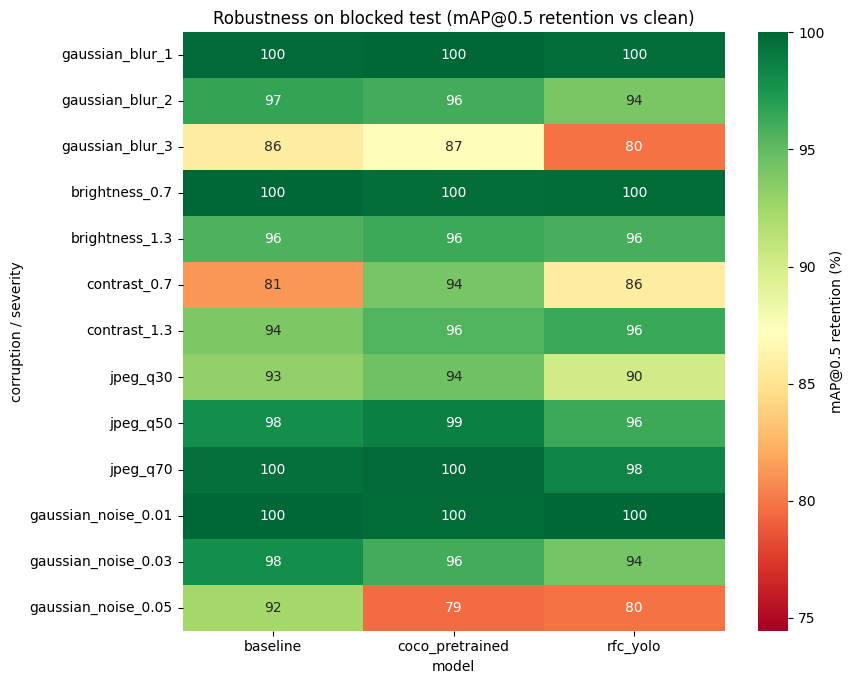

In [58]:
# CELL 22 — ROBUSTNESS EVALUATION
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT); sys.path.insert(0, CC_OUT + "/ext")
from cc_utils import *
from cc_eval import *
import torch, matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm

NC, names, seed0 = CFG["NUM_CLASSES"], load_class_names(), CFG["TRAIN_SEEDS"][0]
P, R = DIRS["predictions"], DIRS["robustness"]
models = {"baseline": f"baseline_blocked_seed{seed0}", "coco_pretrained": f"coco_pretrained_blocked_seed{seed0}", "rfc_yolo": f"rfc_blocked_seed{seed0}"}
models = {k: v for k, v in models.items() if (DIRS["models"] / v / "weights" / "best.pt").exists()}
print("Models:", models)
grid = corruption_grid(CFG)

tasks = []
for label, run in models.items():
    for spec in grid:
        tasks.append(dict(weights=str(DIRS["models"] / run / "weights" / "best.pt"), split="blocked", partition="test", corruption=spec,
                          out=str(R / f"{run}__blocked__{spec['name']}.pkl")))
run_prediction_tasks(tasks, list(range(torch.cuda.device_count())) or [0], CFG["IMAGE_SIZE"], CFG["EVAL_CONF"], CFG["EVAL_IOU"], CFG["MAX_DET"], log_dir=R)

rows = []
for label, run in models.items():
    clean = P / f"{run}__blocked__clean.pkl"
    if not clean.exists(): print(f"[skip] no clean predictions for {run}; run Cell 20"); continue
    conds = [dict(name="clean", type="clean", level=0, path=clean)] + [dict(**s, path=R / f"{run}__blocked__{s['name']}.pkl") for s in grid]
    c50 = None
    for c in tqdm(conds, desc=label):
        E = load_eval(c["path"], "blocked", "test", NC); ap = ap_all(E["prep"], E["gt_counts"]); m50, m95 = map_from_ap(ap)
        if c["name"] == "clean": c50, c95 = m50, m95
        rows.append(dict(model=label, run=run, condition=c["name"], corruption=c["type"], severity=c["level"], mAP50=m50, mAP50_95=m95,
                         retention_mAP50_pct=100 * m50 / c50, retention_mAP50_95_pct=100 * m95 / c95,
                         **{f"AP50_{(names[k] if k < len(names) else k)}": ap[k, 0] for k in range(NC)}))
RB = pd.DataFrame(rows); RB.to_csv(R / "robustness_results.csv", index=False)
summ = RB[RB.condition != "clean"].pivot_table(index=["corruption", "severity", "condition"], columns="model", values="retention_mAP50_pct").reset_index()
summ.to_csv(R / "robustness_summary.csv", index=False)
print(summ.round(1).to_string(index=False))
print("\nMean mAP@0.5 retention over all corruptions (%):", RB[RB.condition != "clean"].groupby("model").retention_mAP50_pct.mean().round(2).to_dict())

hm = summ.set_index("condition").drop(columns=["corruption", "severity"])
fig, ax = plt.subplots(figsize=(1.6 * len(hm.columns) + 4, 0.38 * len(hm) + 2))
sns.heatmap(hm, annot=True, fmt=".0f", cmap="RdYlGn", vmin=max(0, np.nanmin(hm.values) - 5), vmax=100, ax=ax, cbar_kws={"label": "mAP@0.5 retention (%)"})
ax.set_ylabel("corruption / severity"); ax.set_title("Robustness on blocked test (mAP@0.5 retention vs clean)"); plt.tight_layout()
plt.savefig(DIRS["figures"] / "robustness_heatmap.png", dpi=130); plt.show()

---

## CELL 23 — REVIEW-BURDEN ANALYSIS
A capsule exam can contain 50,000–100,000 frames (the paper's own figure), so what matters clinically is **how many frames a reader must look at** for a given sensitivity. For each model (blocked test) and confidence threshold 0.10 … 0.50 (IoU 0.5, class-aware matching):

* `images_flagged` (≥1 detection above threshold) and its fraction,
* `detections_per_image`, `false_positives_per_image`,
* `lesion_recall` (lesion-level, TP/GT) and `precision`,
* `background_images_flagged_pct` (false-alarm rate on lesion-free frames),
* `est_frames_to_review_per_50k` = flagged fraction × 50,000.

> ⚠️ **Prevalence caveat.** This dataset is enriched for lesions (≈2/3 of images have lesions, vs a tiny fraction in real exams), so *flagged fraction is overstated* for real screening. For real-exam planning, use `background_images_flagged_pct` (the false-alarm rate on normal frames) × 50,000 as the lower-bound estimate of frames to review. I print both. Recall here is box-level with correct-class matching, stricter than "was this frame flagged correctly".

Outputs: `review_burden.csv`, `figures/pareto_frontier.png` (recall vs FP/image, recall vs images flagged; Pareto-optimal points are outlined).

**Common errors & fixes:** missing clean predictions → Cell 20.

          model                           run  conf_threshold  n_images  images_flagged  images_flagged_pct  detections_per_image  false_positives_per_image  lesion_recall  precision  background_images  background_images_flagged_pct  est_frames_to_review_per_50k  est_frames_to_review_per_50k_normal_only
       baseline        baseline_blocked_seed0             0.1      2772            1887              68.074                 2.225                      1.400          0.704      0.371                994                         21.730                     34036.797                                 10865.191
       baseline        baseline_blocked_seed0             0.2      2772            1657              59.776                 1.332                      0.629          0.600      0.528                994                         12.575                     29888.167                                  6287.726
       baseline        baseline_blocked_seed0             0.3      2772            14

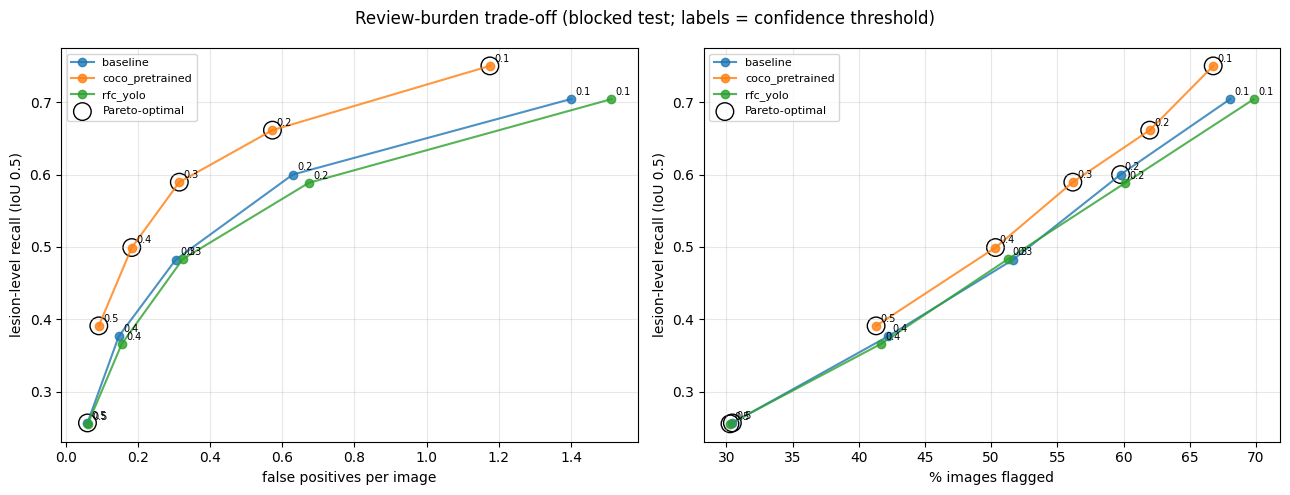

In [79]:
# CELL 23 — REVIEW-BURDEN ANALYSIS
import os, sys
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
from cc_eval import *
import matplotlib.pyplot as plt

NC, seed0 = CFG["NUM_CLASSES"], CFG["TRAIN_SEEDS"][0]; P = DIRS["predictions"]
runs = {"baseline": f"baseline_blocked_seed{seed0}", "coco_pretrained": f"coco_pretrained_blocked_seed{seed0}", "rfc_yolo": f"rfc_blocked_seed{seed0}"}
rows = []
for label, run in runs.items():
    f = P / f"{run}__blocked__clean.pkl"
    if not f.exists(): print(f"[skip] {label}: no predictions"); continue
    E = load_eval(f, "blocked", "test", NC); st = E["stats"]; n = E["n"]
    has_gt = E["gt_counts"].sum(1) > 0; n_bg = int((~has_gt).sum()); total_gt = E["gt_counts"].sum()
    for thr in CFG["REVIEW_CONF_THRESHOLDS"]:
        m = st["conf"] >= thr; imgs = np.unique(st["img_idx"][m]); tp = int(st["tp"][m, 0].sum()); fp = int((~st["tp"][m, 0]).sum())
        bg_flag = int((~has_gt[imgs]).sum())
        rows.append(dict(model=label, run=run, conf_threshold=thr, n_images=n, images_flagged=len(imgs), images_flagged_pct=100 * len(imgs) / n,
                         detections_per_image=m.sum() / n, false_positives_per_image=fp / n, lesion_recall=tp / max(total_gt, 1),
                         precision=tp / max(tp + fp, 1), background_images=n_bg, background_images_flagged_pct=100 * bg_flag / max(n_bg, 1),
                         est_frames_to_review_per_50k=50000 * len(imgs) / n, est_frames_to_review_per_50k_normal_only=50000 * bg_flag / max(n_bg, 1)))
RB = pd.DataFrame(rows); RB.to_csv(P / "review_burden.csv", index=False)
print(RB.round(3).to_string(index=False))

def pareto_mask(x, y):
    """Non-dominated points when minimising x and maximising y."""
    return np.array([not any((x[j] <= x[i] and y[j] >= y[i]) and (x[j] < x[i] or y[j] > y[i]) for j in range(len(x))) for i in range(len(x))])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, xcol, xl in ((axes[0], "false_positives_per_image", "false positives per image"), (axes[1], "images_flagged_pct", "% images flagged")):
    for k, (label, g) in enumerate(RB.groupby("model")):
        g = g.sort_values("conf_threshold"); ax.plot(g[xcol], g.lesion_recall, "-o", color=f"C{k}", label=label, alpha=.8)
        for _, r in g.iterrows(): ax.annotate(f"{r.conf_threshold:.1f}", (r[xcol], r.lesion_recall), fontsize=7, xytext=(3, 3), textcoords="offset points")
    pm = pareto_mask(RB[xcol].values, RB.lesion_recall.values)
    ax.scatter(RB[xcol][pm], RB.lesion_recall[pm], s=160, facecolors="none", edgecolors="k", label="Pareto-optimal")
    ax.set_xlabel(xl); ax.set_ylabel("lesion-level recall (IoU 0.5)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.suptitle("Review-burden trade-off (blocked test; labels = confidence threshold)"); plt.tight_layout()
plt.savefig(DIRS["figures"] / "pareto_frontier.png", dpi=130); plt.show()

---

## CELL 24 — AGENT IMPLEMENTATION
A deterministic, rule-based multi-agent audit (no LLM needed). Library: `cc_agents.py`.

| agent | job |
|---|---|
| `PlannerAgent` | lists tasks and which artifacts each needs; marks tasks ready/blocked |
| `PaperClaimExtractor` | extracts the paper's claims to `claims.json` and compares them with reproduced results (Cell 25) |
| `DataAuditor` | dataset facts, label validity, exact duplicates, label conflicts, near-duplicates |
| `SplitAuditor` | leakage by split |
| `EvaluationAuditor` | model comparison + bootstrap statistics → claims with verdicts |
| `RobustnessAuditor` | corruption retention; review burden |
| `VerifierAgent` | re-reads each claim's evidence file and checks the value is traceable; untraceable claims are downgraded to *unsupported* |
| `ReportGenerator` | Markdown / HTML / JSON from verified claims (Cell 26) |

Every agent **reads artifacts from disk**, writes JSON to `artifacts/agent_results/`, and returns an `AgentResult` holding claims with `evidence_file`, `metric`, `value`, optional `ci`, a `verdict` (`supported` / `partially_supported` / `unsupported`), a `confidence`, and a `locator` that tells the verifier exactly where the number lives.
**Rules baked in:** a single-seed comparison can never be `high` confidence; a result without a confidence interval can never be `supported` beyond `partially_supported` if it is a *comparative* claim; the optional LLM may only paraphrase existing evidence, and any number in its text that is not in the evidence JSON causes the text to be discarded.

Agent loop in this cell: Planner → DataAuditor → SplitAuditor → EvaluationAuditor → RobustnessAuditor. Cells 25–26 add the paper check, Verifier and ReportGenerator.

**Expected output:** a trace of each agent with status and number of claims; missing artifacts yield `blocked` status (not a crash).

**Common errors & fixes:** `status: blocked` → run the cell named in its `missing` list. Editing `cc_agents.py` → re-run this cell (module is reloaded).

In [80]:
%%writefile /kaggle/working/capsulecopilot/cc_agents.py
"""CapsuleCopilot deterministic audit agents. Every number comes from an artifact file on disk."""
import os, sys, json, re, time, base64, traceback, html
from dataclasses import dataclass, field, asdict
from cc_utils import *

SUP, PART, UNS = "supported", "partially_supported", "unsupported"
AG_DIR = DIRS["artifacts"] / "agent_results"; AG_DIR.mkdir(parents=True, exist_ok=True)
rel = lambda p: str(Path(p).relative_to(OUT)) if str(p).startswith(str(OUT)) else str(p)


@dataclass
class Claim:
    id: str; text: str; evidence_file: str; metric: str; value: object; verdict: str; confidence: str
    ci: object = None; locator: dict = None; notes: str = ""; category: str = ""


@dataclass
class AgentResult:
    agent: str; status: str; summary: dict = field(default_factory=dict); claims: list = field(default_factory=list)
    evidence_paths: list = field(default_factory=list); confidence: str = "n/a"; outputs: list = field(default_factory=list); missing: list = field(default_factory=list)


def fetch_value(loc):
    """Re-read a number from its evidence file. loc: {file, kind: csv|json, column|key, where, where_not, agg, scale}."""
    p = OUT / loc["file"]
    if not p.exists(): raise FileNotFoundError(loc["file"])
    sc = loc.get("scale", 1)
    if loc["kind"] == "json":
        v = read_json(p)
        for k in loc["key"]: v = v[k]
        return v * sc if isinstance(v, (int, float)) and not isinstance(v, bool) else v
    df = pd.read_csv(p, keep_default_na=False)
    for c, val in loc.get("where", {}).items(): df = df[df[c].astype(str) == str(val)]
    for c, val in loc.get("where_not", {}).items(): df = df[df[c].astype(str) != str(val)]
    if len(df) == 0: raise KeyError(f"no rows match {loc.get('where')} in {loc['file']}")
    col = pd.to_numeric(df[loc["column"]], errors="coerce")
    return float((col.mean() if loc.get("agg") == "mean" else col.iloc[0]) * sc)


def mk(cid, text, file, metric, loc, verdict, conf, ci=None, notes="", category=""):
    """Create a claim whose value is fetched from the evidence file (so the number is never typed in by hand)."""
    v = fetch_value(loc)
    return Claim(cid, text, rel(OUT / file), metric, v, verdict, conf, ci, loc, notes, category)


def _need(files):
    return [f for f in files if not (OUT / f).exists()]


def save_result(res):
    save_json(asdict(res), AG_DIR / f"{res.agent}.json"); return res


class PlannerAgent:
    TASKS = [("data_audit", ["artifacts/dataset_manifest.csv", "audits/duplicate_label_conflicts.csv", "artifacts/near_dup_summary.json"]),
             ("split_audit", ["artifacts/leakage_summary.json", "artifacts/split_integrity_report.csv"]),
             ("evaluation_audit", ["predictions/main_results.csv", "predictions/statistical_tests.csv"]),
             ("robustness_audit", ["robustness/robustness_summary.csv", "predictions/review_burden.csv"]),
             ("paper_claims", ["artifacts/claims.json"])]

    def run(self):
        plan = [dict(task=t, requires=r, missing=_need(r), status="ready" if not _need(r) else "blocked") for t, r in self.TASKS]
        save_json(plan, DIRS["artifacts"] / "agent_plan.json")
        return save_result(AgentResult("PlannerAgent", "ok", dict(n_tasks=len(plan), blocked=[p["task"] for p in plan if p["status"] == "blocked"]),
                                 [], [rel(DIRS["artifacts"] / "agent_plan.json")], "high", [rel(DIRS["artifacts"] / "agent_plan.json")]))


class DataAuditor:
    def run(self):
        miss = _need(["artifacts/dataset_manifest.csv", "audits/duplicate_label_conflicts.csv", "audits/exact_duplicate_audit.csv", "artifacts/label_validation_report.csv"])
        if miss: return save_result(AgentResult("DataAuditor", "blocked", missing=miss))
        man = load_manifest(); val = pd.read_csv(DIRS["artifacts"] / "label_validation_report.csv", keep_default_na=False)
        C = pd.read_csv(DIRS["audits"] / "duplicate_label_conflicts.csv"); G = pd.read_csv(DIRS["artifacts"] / "duplicate_groups.csv")
        A = pd.read_csv(DIRS["audits"] / "exact_duplicate_audit.csv")
        inv = pd.read_csv(DIRS["artifacts"] / "invalid_boxes.csv") if (DIRS["artifacts"] / "invalid_boxes.csv").exists() else pd.DataFrame()
        n_conf = int(C.is_conflict.sum()) if len(C) else 0
        s = dict(n_images=len(man), n_boxes=int(man.number_of_boxes.sum()), n_background_images=int((man.number_of_boxes == 0).sum()),
                 n_classes_observed=len(set(c for x in man.box_classes for c in x.split(";") if c)), n_missing_label_files=int((val.status == "missing_file").sum()),
                 n_invalid_label_lines=int(len(inv)), n_exact_dup_groups=len(G), n_exact_dup_pairs=len(C), n_images_in_dup_groups=len(A),
                 n_conflicting_pairs=n_conf, pct_conflicting_pairs=100 * n_conf / max(len(C), 1),
                 n_groups_with_conflict=int(pd.read_csv(DIRS["audits"] / "duplicate_group_conflicts.csv").get("group_has_conflict", pd.Series([], dtype=bool)).astype(bool).sum()))
        nd = DIRS["artifacts"] / "near_dup_summary.json"
        if nd.exists():
            for t, d in read_json(nd)["thresholds"].items(): s[f"near_dup_pairs_all_cos_{t}"] = d["all_pairs_exact_count"]; s[f"near_dup_images_topk_cos_{t}"] = d["images_involved_topk"]
        save_json(s, DIRS["audits"] / "dataset_audit_summary.json"); F = "audits/dataset_audit_summary.json"
        J = lambda k, sc=1: dict(file=F, kind="json", key=[k], scale=sc)
        cl = []
        cl.append(mk("D1", "Dataset image count matches the published 18,481", F, "n_images", J("n_images"), SUP if s["n_images"] == 18481 else UNS, "high", category="dataset"))
        cl.append(mk("D2", "Dataset has 23,033 bounding boxes (paper Table 1)", F, "n_boxes", J("n_boxes"), SUP if s["n_boxes"] == 23033 else UNS, "high", category="dataset"))
        cl.append(mk("D3", "6,161 images are background-only (paper Sec. IV-A)", F, "n_background_images", J("n_background_images"), SUP if s["n_background_images"] == 6161 else UNS, "high", category="dataset"))
        cl.append(mk("D4", "All label lines are well-formed and in range", F, "n_invalid_label_lines", J("n_invalid_label_lines"), SUP if s["n_invalid_label_lines"] == 0 else PART, "high",
                     notes="invalid lines are logged and sanitised (Cell 14), not silently dropped", category="labels"))
        cl.append(mk("D5", "Byte-identical duplicate images exist (pairs)", F, "n_exact_dup_pairs", J("n_exact_dup_pairs"), SUP if s["n_exact_dup_pairs"] > 0 else UNS, "high", category="duplicates"))
        cl.append(mk("D6", "Some byte-identical pairs carry conflicting labels (pairs)", F, "n_conflicting_pairs", J("n_conflicting_pairs"), SUP if n_conf > 0 else UNS, "high",
                     notes=f"{s['pct_conflicting_pairs']:.1f}% of duplicate pairs; counts are recomputed, not copied from earlier runs", category="label_conflicts"))
        return save_result(AgentResult("DataAuditor", "ok", s, cl, [rel(DIRS["audits"] / "dataset_audit_summary.json"), "audits/duplicate_label_conflicts.csv"], "high",
                                 [rel(DIRS["audits"] / "dataset_audit_summary.json")]))


class SplitAuditor:
    def run(self):
        miss = _need(["artifacts/leakage_summary.json"])
        if miss: return save_result(AgentResult("SplitAuditor", "blocked", missing=miss))
        L = read_json(DIRS["artifacts"] / "leakage_summary.json")["splits"]; F = "artifacts/leakage_summary.json"
        g = lambda sp, k: L[sp]["test"][k]
        r, b = g("random", "leak_rate_cos_0.95"), g("blocked", "leak_rate_cos_0.95")
        loc = lambda sp, k: dict(file=F, kind="json", key=["splits", sp, "test", k], scale=100)
        cl = [mk("S1", "Random-split test images that have a near-duplicate (cos>=0.95) in train (%)", F, "leak_rate_cos_0.95 (%)", loc("random", "leak_rate_cos_0.95"), PART if r > 0 else UNS, "medium",
                 notes="measured with ImageNet ResNet-18 embeddings; a proxy for visual similarity, not patient identity", category="leakage"),
              mk("S2", "Blocked-split test images that have a near-duplicate (cos>=0.95) in train (%)", F, "leak_rate_cos_0.95 (%)", loc("blocked", "leak_rate_cos_0.95"), SUP if b <= 0.01 else PART, "medium", category="leakage"),
              mk("S3", "Random-split test images with a byte-identical twin in train (%)", F, "exact_duplicate_leak_rate (%)", loc("random", "exact_duplicate_leak_rate"), SUP if g("random", "exact_duplicate_leak_rate") > 0 else UNS, "high", category="leakage")]
        v = SUP if b < 0.5 * r else (PART if b < r else UNS)
        cl.append(Claim("S4", "The blocked split reduces near-duplicate leakage relative to the random split (cos>=0.95)", rel(OUT / F), "leak(blocked) - leak(random) (pp)",
                        100 * (b - r), v, "medium", locator=dict(file=F, kind="json", key=["splits", "blocked", "test", "leak_rate_cos_0.95"], scale=100),
                        notes="locator shows the blocked value; random value is claim S1. Not patient-level splitting.", category="leakage"))
        cl[-1].value = fetch_value(cl[-1].locator)
        return save_result(AgentResult("SplitAuditor", "ok", dict(random_leak_0_95=r, blocked_leak_0_95=b), cl, [F, "artifacts/split_integrity_report.csv"], "medium", [F]))


class EvaluationAuditor:
    def run(self):
        miss = _need(["predictions/main_results.csv"])
        if miss: return save_result(AgentResult("EvaluationAuditor", "blocked", missing=miss))
        M = pd.read_csv(DIRS["predictions"] / "main_results.csv"); cl = []; F = "predictions/main_results.csv"
        for _, r in M.iterrows():
            cl.append(mk(f"E_{r.run}_{r.eval_split}", f"{r.run} mAP@0.5 on {r.eval_split}-test ({int(r.n_test_images)} images, single seed)", F, "mAP50 (%)",
                         dict(file=F, kind="csv", column="mAP50", where=dict(run=r.run, eval_split=r.eval_split), scale=100), SUP, "medium",
                         notes="point estimate; see statistical_tests.csv for CI", category="model_results"))
        T = DIRS["predictions"] / "statistical_tests.csv"
        if T.exists():
            S = pd.read_csv(T); FS = "predictions/statistical_tests.csv"
            for i, r in S[S.metric == "mAP50"].iterrows():
                d = r.diff_point; ex = bool(r.ci_excludes_0)
                v = (SUP if (ex and d != 0) else PART if abs(d) > 0 else UNS)
                cl.append(mk(f"T{i}", f"[{r.comparison}] mAP@0.5 difference A-B (pp)", FS, "diff_point (pp)",
                             dict(file=FS, kind="csv", column="diff_point", where=dict(comparison=r.comparison, metric="mAP50"), scale=100), v,
                             "low" if r.design == "paired" and "seed" in r.model_A else "medium", ci=[100 * r.ci95_lo, 100 * r.ci95_hi],
                             notes=f"{r.design} bootstrap p={r.p_value:.3f}; CI covers test-sampling variance only (1 training seed)", category="statistics"))
        return save_result(AgentResult("EvaluationAuditor", "ok", dict(n_rows=len(M)), cl, [F, "predictions/statistical_tests.csv"], "medium", [F]))


class RobustnessAuditor:
    def run(self):
        miss = _need(["robustness/robustness_results.csv"])
        if miss: return save_result(AgentResult("RobustnessAuditor", "blocked", missing=miss))
        R = pd.read_csv(DIRS["robustness"] / "robustness_results.csv"); F = "robustness/robustness_results.csv"; cl = []
        means = R[R.condition != "clean"].groupby("model").retention_mAP50_pct.mean()
        for m in means.index:
            cl.append(mk(f"R_{m}", f"{m}: mean mAP@0.5 retention across all corruptions (%)", F, "retention_mAP50_pct (mean)",
                         dict(file=F, kind="csv", column="retention_mAP50_pct", where=dict(model=m), where_not=dict(condition="clean"), agg="mean"), SUP, "medium",
                         notes="descriptive; single seed", category="robustness"))
        if {"baseline", "rfc_yolo"} <= set(means.index):
            d = means["rfc_yolo"] - means["baseline"]
            cl.append(Claim("R_cmp", "RFC-YOLO is more robust to corruption than the baseline (mean retention difference, pp)", F, "mean retention diff (pp)", float(d),
                            PART if d > 0 else UNS, "low", locator=None, category="robustness",
                            notes="no confidence interval and one seed -> capped at partially_supported/low; difference computed from claims R_rfc_yolo - R_baseline"))
        B = DIRS["predictions"] / "review_burden.csv"
        if B.exists():
            RB = pd.read_csv(B); FB = "predictions/review_burden.csv"
            for m in RB.model.unique():
                cl.append(mk(f"B_{m}", f"{m}: lesion recall at conf 0.30 on blocked test (%)", FB, "lesion_recall (%)",
                             dict(file=FB, kind="csv", column="lesion_recall", where=dict(model=m, conf_threshold=0.3), scale=100), SUP, "medium", category="review_burden"))
        return save_result(AgentResult("RobustnessAuditor", "ok", dict(mean_retention=means.round(2).to_dict()), cl, [F], "medium", [F]))


class PaperClaimExtractor:
    """Parses the RFC-YOLO PDF when available (pypdf); otherwise uses claims transcribed by hand from the manuscript.
    Either way `pdf_verified` records which transcribed numbers were found in the PDF text."""
    CURATED = [  # (id, category, text, value, unit, location)
        ("P1", "dataset", "SEE-AI, 18,481 images", 18481, "images", "Sec. IV-A"),
        ("P2", "dataset", "23,033 bounding boxes, 12 classes", 23033, "boxes", "Sec. IV-A, Table 1"),
        ("P3", "dataset", "6,161 background-only images", 6161, "images", "Sec. IV-A"),
        ("P4", "split", "8:1:1 train/val/test; results reported on the validation set (also used for checkpoint selection)", 1848, "val images", "Sec. IV-A"),
        ("P5", "baseline", "YOLOv11n mAP@0.5", 69.7, "%", "Tables 2, 3, 6"),
        ("P6", "baseline", "YOLOv11n mAP@0.5:0.95", 34.0, "%", "Tables 2, 6"),
        ("P7", "result", "RFC-YOLO mAP@0.5", 73.3, "%", "Abstract, Table 2"),
        ("P8", "result", "RFC-YOLO mAP@0.5:0.95", 38.3, "%", "Table 2"),
        ("P9", "result", "RFC-YOLO precision / recall", 72.3, "% (recall 64.9)", "Table 2"),
        ("P10", "improvement", "mAP@0.5 improvement over YOLOv11n", 3.6, "pp", "Sec. I, VI"),
        ("P11", "components", "RFAConv (backbone), C3k2-CBAM (neck), Focal-MPDIoU (gamma=1.5, alpha=1.0)", 1.5, "gamma", "Sec. III"),
        ("P12", "setting", "imgsz 1280, batch 32, 100 epochs, SGD lr0 0.01, Ultralytics 8.3.223, A100", 1280, "px", "Sec. IV-B"),
        ("P13", "efficiency", "Params 2.59M -> 2.85M; GFLOPs 6.3 -> 11.15; FPS 79.27 -> 49.31", 11.15, "GFLOPs", "Table 10"),
        ("P14", "ablation", "Individual mAP@0.5 gains: RFAConv 71.3, C3k2-CBAM 72.1, Focal-MPDIoU 71.7; all three 73.3", 73.3, "%", "Table 6"),
        ("P15", "cross_dataset", "Kvasir-Capsule mAP@0.5: 21.5 -> 30.6 (not reproducible here)", 30.6, "%", "Table 7"),
    ]
    NEEDLES = {"P1": "18,481", "P2": "23,033", "P3": "6,161", "P5": "69.7", "P6": "34.0", "P7": "73.3", "P8": "38.3", "P9": "72.3", "P12": "1280", "P13": "11.15", "P14": "72.1", "P15": "30.6"}

    def _find_pdf(self):
        if CFG.get("PAPER_PDF") and Path(CFG["PAPER_PDF"]).exists(): return Path(CFG["PAPER_PDF"])
        for base in ("/kaggle/input", "/kaggle/working", "/mnt/user-data/uploads"):
            if Path(base).exists():
                for dp, _, fs in os.walk(base):
                    for f in fs:
                        if f.lower().endswith(".pdf") and ("rfc" in f.lower() or "yolo" in f.lower()): return Path(dp) / f
        return None

    def extract(self):
        pdf, text, verified, method = self._find_pdf(), "", None, "curated_from_manuscript_reading"
        if pdf:
            try:
                from pypdf import PdfReader
                text = "\n".join((pg.extract_text() or "") for pg in PdfReader(str(pdf)).pages); method = f"pypdf:{pdf.name}"
                verified = {k: (v in text) for k, v in self.NEEDLES.items()}
            except Exception as e:
                method = f"curated (PDF parse failed: {e})"
        claims = [dict(id=i, category=c, text=t, value=v, unit=u, location=l, found_in_pdf=(verified or {}).get(i)) for i, c, t, v, u, l in self.CURATED]
        # arithmetic on the paper's own numbers (Table 6 and Table 9) - no data from this notebook involved
        ind = [71.3 - 69.7, 72.1 - 69.7, 71.7 - 69.7]
        derived = dict(ablation_individual_gains_pp=ind, ablation_sum_individual_gains_pp=round(sum(ind), 2), ablation_combined_gain_pp=round(73.3 - 69.7, 2),
                       ablation_combined_exceeds_each_individual=bool(73.3 - 69.7 > max(ind)),
                       ablation_subadditivity_gap_pp=round(sum(ind) - (73.3 - 69.7), 2),
                       table3_6_baseline_mAP50=69.7, table9_baseline_mAP50_mean=64.0, table9_baseline_mAP50_sd=2.5,
                       baseline_table9_vs_table3_gap_pp=round(69.7 - 64.0, 2), table9_compares="YOLOv11n vs +RFAConv only (not full RFC-YOLO)",
                       table9_mAP50_p_value_reported_nonsignificant=True, eval_partition_in_paper="validation (also used for best-checkpoint selection)",
                       paper_improvement_mAP50_pp=3.6)
        out = dict(source=method, pdf_path=str(pdf) if pdf else None, claims=claims, derived=derived, pdf_verified=verified,
                   note="Page refs are IEEE Access vol. 14 (2026) pp. 138642-138655. Numbers marked found_in_pdf=false should be re-checked by hand." if verified else
                        "PDF not found: claims were transcribed manually from the manuscript; attach the PDF and re-run Cell 25 to machine-check them.")
        save_json(out, DIRS["artifacts"] / "claims.json"); return out

    def compare(self):
        """Claimed vs reproduced; returns AgentResult with one claim per paper claim."""
        miss = _need(["artifacts/claims.json", "predictions/main_results.csv"])
        if miss: return save_result(AgentResult("PaperClaimChecker", "blocked", missing=miss))
        pc = read_json(DIRS["artifacts"] / "claims.json"); d = pc["derived"]; cl = []; seed0 = CFG["TRAIN_SEEDS"][0]
        FM, FC, FD = "predictions/main_results.csv", "artifacts/claims.json", "audits/dataset_audit_summary.json"
        setting = "NOT like-for-like: ours = 576px/50 epochs/scratch/blocked-split TEST set vs paper = 1280px/100 epochs/validation set"
        def tol(diff): a = abs(diff); return SUP if a <= 1.5 else PART if a <= 5 else UNS
        def add_repro(cid, text, run, col, claimed):
            loc = dict(file=FM, kind="csv", column=col, where=dict(run=run, eval_split="blocked"), scale=100)
            try: v = fetch_value(loc)
            except Exception: return
            c = mk(cid, f"{text} (paper: {claimed}%)", FM, f"{col} (%)", loc, tol(v - claimed), "low", notes=f"reproduced - claimed = {v - claimed:+.1f} pp. {setting}", category="paper_claim")
            cl.append(c)
        add_repro("PC1", "YOLOv11n baseline mAP@0.5", f"baseline_blocked_seed{seed0}", "mAP50", 69.7)
        add_repro("PC2", "YOLOv11n baseline mAP@0.5:0.95", f"baseline_blocked_seed{seed0}", "mAP50_95", 34.0)
        add_repro("PC3", "RFC-YOLO mAP@0.5", f"rfc_blocked_seed{seed0}", "mAP50", 73.3)
        add_repro("PC4", "RFC-YOLO mAP@0.5:0.95", f"rfc_blocked_seed{seed0}", "mAP50_95", 38.3)
        ST = DIRS["predictions"] / "statistical_tests.csv"
        if ST.exists():
            S = pd.read_csv(ST); r = S[(S.comparison == "baseline vs RFC-YOLO (blocked test)") & (S.metric == "mAP50")]
            if len(r):
                r = r.iloc[0]; dd = 100 * r.diff_point; ex = bool(r.ci_excludes_0)
                v = SUP if (ex and dd >= 0.5 * 3.6) else PART if dd > 0 else UNS
                cl.append(mk("PC5", "RFC-YOLO improves mAP@0.5 over YOLOv11n by ~3.6 pp (paper)", "predictions/statistical_tests.csv", "diff_point (pp)",
                             dict(file="predictions/statistical_tests.csv", kind="csv", column="diff_point", where=dict(comparison=r.comparison, metric="mAP50"), scale=100), v, "low",
                             ci=[100 * r.ci95_lo, 100 * r.ci95_hi], notes=f"bootstrap p={r.p_value:.3f}; one seed; CI excludes 0: {ex}. {setting}", category="paper_claim"))
        if (DIRS["audits"] / "dataset_audit_summary.json").exists():
            for cid, k, want in (("PC6", "n_images", 18481), ("PC7", "n_boxes", 23033), ("PC8", "n_background_images", 6161)):
                cl.append(mk(cid, f"Paper's dataset statistic {k} = {want}", FD, k, dict(file=FD, kind="json", key=[k]), SUP if fetch_value(dict(file=FD, kind="json", key=[k])) == want else UNS, "high", category="paper_claim"))
        AC = DIRS["artifacts"] / "architecture_check_placeholder"
        if (DIRS["artifacts"] / "rfc_architecture_check.json").exists():
            fa = "artifacts/rfc_architecture_check.json"; ok = read_json(DIRS["artifacts"] / "rfc_architecture_check.json")["parity_plausible"]
            cl.append(mk("PC9", "Reproduced RFC architecture matches paper's size (2.85M params, ~+77% FLOPs)", fa, "params_rfc",
                         dict(file=fa, kind="json", key=["params_rfc"]), SUP if ok else UNS, "medium",
                         notes="UNS = the reproduction differs from the paper's reported size, so architecture parity is not established", category="paper_claim"))
        # internal-consistency checks on the paper's own numbers
        cl.append(mk("PI1", "Paper: the three modules act 'complementary/coordinated': combined gain vs sum of individual gains (pp, sum - combined)", FC, "subadditivity gap (pp)",
                     dict(file=FC, kind="json", key=["derived", "ablation_subadditivity_gap_pp"]), PART, "high",
                     notes="combined gain (3.6) exceeds each individual gain (max 2.4) but is LESS than their sum (6.0): gains overlap (sub-additive), which is not evidence of synergy", category="paper_internal"))
        cl.append(mk("PI2", "Paper: baseline mAP@0.5 is consistent across tables (Tables 3/6 = 69.7 vs Table 9 mean 64.0; gap pp)", FC, "gap (pp)",
                     dict(file=FC, kind="json", key=["derived", "baseline_table9_vs_table3_gap_pp"]), UNS, "high",
                     notes="gap is >2 SD of Table 9's reported SD (2.5); possible different protocol/runs, unexplained in the text", category="paper_internal"))
        cl.append(mk("PI3", "Paper: statistical robustness established for RFC-YOLO (Table 9 tests YOLOv11n vs +RFAConv only; mAP p>0.05)", FC, "paper_improvement_mAP50_pp",
                     dict(file=FC, kind="json", key=["derived", "paper_improvement_mAP50_pp"]), UNS, "high",
                     notes="significance test covers the RFAConv-only variant over 3 seeds; mAP differences were not significant; the full model was not tested", category="paper_internal"))
        cl.append(mk("PI4", "Paper reports results on a held-out set", FC, "validation images", dict(file=FC, kind="json", key=["claims", 3, "value"]), PART, "high",
                     notes="reported numbers are on the validation set that was also used for checkpoint selection; the test set is not reported; no duplicate/leakage control is described", category="paper_internal"))
        out = DIRS["artifacts"] / "paper_claim_comparison.csv"
        pd.DataFrame([asdict(c) for c in cl]).drop(columns=["locator"]).to_csv(out, index=False)
        return save_result(AgentResult("PaperClaimChecker", "ok", dict(n=len(cl)), cl, [FC, FM], "medium", [rel(out)]))


class VerifierAgent:
    """Re-reads every claim's evidence file and checks the number is traceable. Downgrades untraceable claims."""
    def run(self, results):
        ok = bad = 0; log = []
        for r in results:
            for c in r.claims:
                p = OUT / c.evidence_file; reason = None
                if not p.exists(): reason = "evidence file missing"
                elif c.locator:
                    try:
                        v = fetch_value(c.locator)
                        if isinstance(v, (int, float)) and isinstance(c.value, (int, float)) and not np.isclose(v, c.value, rtol=1e-6, atol=1e-9): reason = f"value mismatch {v} vs {c.value}"
                    except Exception as e: reason = f"locator failed: {e}"
                elif c.id != "R_cmp" and c.id != "S4": reason = "no locator"
                if reason:
                    bad += 1; c.notes += f" [VERIFIER: {reason}; downgraded]"; c.verdict = UNS; c.confidence = "none"
                else: ok += 1
                log.append(dict(claim=c.id, ok=reason is None, reason=reason))
        save_json(log, DIRS["artifacts"] / "verifier_log.json")
        return dict(verified=ok, downgraded=bad)


class LocalLLMSummarizer:
    """OPTIONAL. Paraphrases the deterministic summary; text is discarded if it contains any number not present in the evidence."""
    def __init__(self, enabled=False, model=None): self.enabled, self.model = enabled, model
    def summarize(self, evidence_text):
        if not self.enabled: return None
        try:
            from transformers import pipeline
            gen = pipeline("text-generation", model=self.model or CFG["LLM_MODEL"], device_map="auto")
            out = gen("Summarise ONLY the facts below in 4 sentences. Do not add numbers.\n\n" + evidence_text + "\n\nSummary:", max_new_tokens=220, do_sample=False)[0]["generated_text"].split("Summary:")[-1].strip()
            nums = set(re.findall(r"\d+(?:\.\d+)?", out)); known = set(re.findall(r"\d+(?:\.\d+)?", evidence_text))
            return out if nums <= known else None
        except Exception as e:
            print("LLM summary unavailable:", e); return None


def img_b64(p):
    return "data:image/png;base64," + base64.b64encode(open(p, "rb").read()).decode() if Path(p).exists() else ""


def csv_or_none(p, **kw):
    return pd.read_csv(p, **kw) if Path(p).exists() else None


class ReportGenerator:
    FIGS = [("sample_images.png", "Sample images"), ("class_distribution.png", "Class distribution"), ("near_duplicates.png", "Near-duplicate pairs"),
            ("leakage_rate_by_split.png", "Leakage by split"), ("forest_plot_map_differences.png", "Paired-bootstrap mAP@0.5 differences"),
            ("bar_map_with_ci.png", "mAP@0.5 with CI"), ("robustness_heatmap.png", "Robustness heatmap"), ("pareto_frontier.png", "Review-burden Pareto")]

    def __init__(self, results, verifier_stats):
        self.results, self.vs = results, verifier_stats
        self.claims = [c for r in results for c in r.claims]

    def tables(self):
        P, A, R = DIRS["predictions"], DIRS["audits"], DIRS["robustness"]
        t = {}
        t["dataset"] = pd.DataFrame(read_json(A / "dataset_audit_summary.json").items(), columns=["item", "value"]) if (A / "dataset_audit_summary.json").exists() else None
        t["class_counts"] = csv_or_none(DIRS["artifacts"] / "class_counts.csv")
        lk = DIRS["artifacts"] / "leakage_summary.json"
        if lk.exists():
            rows = [dict(split=s, partition=p, **{k: (100 * v if isinstance(v, float) and k != "median_max_cos" else v) for k, v in d.items()}) for s, parts in read_json(lk)["splits"].items() for p, d in parts.items()]
            t["leakage"] = pd.DataFrame(rows)
        t["conflicts"] = csv_or_none(A / "conflict_type_summary.csv"); t["conflict_classes"] = csv_or_none(A / "conflict_classes_affected.csv")
        t["main"] = csv_or_none(P / "main_results.csv"); t["stats"] = csv_or_none(P / "statistical_tests.csv"); t["robust"] = csv_or_none(R / "robustness_summary.csv"); t["burden"] = csv_or_none(P / "review_burden.csv")
        return t

    def claims_df(self):
        rows = [dict(id=c.id, claim=c.text, evidence_file=c.evidence_file, metric=c.metric, value=(round(c.value, 4) if isinstance(c.value, float) else c.value),
                     ci95=("" if not c.ci else f"[{c.ci[0]:.2f}, {c.ci[1]:.2f}]"), verdict=c.verdict, confidence=c.confidence, notes=c.notes) for c in self.claims]
        return pd.DataFrame(rows)

    def limitations(self):
        L = ["**Not patient-level.** SEE-AI has no patient/video IDs. The blocked split controls near-duplicate leakage as judged by ImageNet ResNet-18 embeddings; it cannot guarantee patient independence.",
             "**Single training seed per configuration** (see TRAIN_SEEDS). Bootstrap CIs cover test-sampling variance only, not seed variance; differences of about 1 mAP point are within typical run-to-run noise for small YOLO models.",
             "**Not like-for-like with the paper**: 576 px / 50 epochs / blocked-split test set here vs 1280 px / 100 epochs / validation set there; RFC-YOLO is a reproduction from the paper text, not the authors' code.",
             "**Embedding-threshold dependence**: leakage and blocked-split quality depend on the cosine threshold and on whether embeddings are mean-centred; ImageNet features are a proxy for similarity.",
             "**Label-conflict audit covers only byte-identical pairs**; near-duplicates with different labels were not adjudicated, and a conflict does not say which label is right (no clinician review).",
             "**Corruptions are synthetic** and mild at the stated levels; they are not a validated model of capsule-camera artefacts.",
             "**Review-burden extrapolation** assumes the dataset's lesion prevalence; real exams are dominated by normal frames. Use the normal-frame false-alarm columns for planning.",
             "**Own mAP evaluator**; cross-checked against Ultralytics val() (predictions/ultralytics_crosscheck.csv)."]
        return L

    def recommendations(self):
        return ["Report results on a held-out **test** partition of a leakage-controlled split; do not select checkpoints on the reporting partition.",
                "Publish split lists (done here: splits/*_train/val/test.txt) and adopt near-duplicate-aware splitting when patient IDs are unavailable.",
                "Resolve label conflicts among duplicate images (clinician adjudication) and remove or relabel them before training.",
                "Run >=3 seeds per configuration and test the **full** model (not a sub-module) before claiming an architecture gain.",
                "Evaluate robustness (JPEG, blur, illumination) and report review burden at fixed recall, not only mAP.",
                "Validate externally on a second capsule dataset with a shared label map."]

    def repro(self):
        import platform
        ver = {}
        for m in ("torch", "torchvision", "ultralytics", "numpy", "pandas", "sklearn"):
            try: ver[m] = __import__(m).__version__
            except Exception: ver[m] = "n/a"
        items = [("Python", platform.python_version()), *[(k, v) for k, v in ver.items()], ("Seeds trained", CFG.get("TRAIN_SEEDS")), ("Split seed", CFG.get("SPLIT_SEED")),
                 ("Image size / epochs / total batch", f"{CFG.get('IMAGE_SIZE')} / {CFG.get('EPOCHS')} / {CFG.get('BATCH_SIZE')}"), ("Device", CFG.get("DEVICE")),
                 ("Primary cosine threshold / centred embeddings", f"{CFG.get('PRIMARY_COSINE')} / {CFG.get('CENTER_EMBEDDINGS')}"), ("Bootstrap B", CFG.get("BOOTSTRAP_B")),
                 ("Tracked training wall-clock (h)", round(used_gpu_hours(), 2))]
        files = ["artifacts/dataset_manifest.csv", "artifacts/label_validation_report.csv", "audits/exact_duplicate_audit.csv", "audits/duplicate_label_conflicts.csv",
                 "artifacts/embeddings.npy", "splits/random_split.csv", "splits/blocked_split.csv", "splits/deduplicated_blocked_split.csv", "splits/blocked.yaml",
                 "artifacts/leakage_summary.json", "predictions/main_results.csv", "predictions/statistical_tests.csv", "robustness/robustness_results.csv",
                 "predictions/review_burden.csv", "artifacts/claims.json", "config.json"]
        return items, [(f, (OUT / f).exists()) for f in files]

    def exec_summary(self):
        cnt = Counter(c.verdict for c in self.claims); g = {c.id: c for c in self.claims}
        s = [f"{len(self.claims)} claims were generated; {cnt.get(SUP, 0)} supported, {cnt.get(PART, 0)} partially supported, {cnt.get(UNS, 0)} unsupported "
             f"(verifier: {self.vs['verified']} traceable, {self.vs['downgraded']} downgraded)."]
        if "D5" in g and "D6" in g: s.append(f"Byte-identical duplicates: {g['D5'].value:.0f} pairs, of which {g['D6'].value:.0f} have conflicting labels.")
        if "S1" in g and "S2" in g: s.append(f"Near-duplicate leakage (cos>=0.95) in the test set: random split {g['S1'].value:.1f}% vs blocked split {g['S2'].value:.1f}%.")
        if "PC5" in g: s.append(f"RFC-YOLO vs baseline mAP@0.5 on the blocked test set: {g['PC5'].value:+.2f} pp, 95% CI {g['PC5'].ci[0]:+.2f} to {g['PC5'].ci[1]:+.2f} (single seed; paper claims +3.6).")
        return s

    def build(self, llm=None):
        T, claims = self.tables(), self.claims_df(); md = []
        H = lambda t: md.append(f"\n## {t}\n")
        md.append("# CapsuleCopilot: Audit of Leakage, Label Conflicts, and Robustness in WCE Detection (SEE-AI)\n")
        md.append(f"_Generated {time.strftime('%Y-%m-%d %H:%M')} by deterministic agents; every number below is read from an artifact file._\n")
        H("1. Executive summary"); md += [f"- {x}" for x in self.exec_summary()]
        if llm: md.append(f"\n> _Optional LLM paraphrase (numbers verified against evidence)_: {llm}")
        H("2. Dataset audit"); md += [df_to_md(T["dataset"]) if T["dataset"] is not None else "_not available (run Cells 4-8)_", "", df_to_md(T["class_counts"]) if T["class_counts"] is not None else ""]
        md.append("\n![classes](../figures/class_distribution.png)")
        H("3. Leakage audit")
        md += [df_to_md(T["leakage"]) if T["leakage"] is not None else "_not available (run Cell 16)_", "", "![leak](../figures/leakage_rate_by_split.png)", "",
               "Blocked = near-duplicate-controlled split (NOT patient-level)."]
        H("4. Label-conflict audit (byte-identical pairs)"); md += [df_to_md(T["conflicts"]) if T["conflicts"] is not None else "_not available (run Cell 8)_", "", df_to_md(T["conflict_classes"]) if T["conflict_classes"] is not None else ""]
        H("5. Model comparison (each model on test sets disjoint from its training set)")
        if T["main"] is not None: md.append(df_to_md(T["main"][["run", "eval_split", "n_test_images", "mAP50", "mAP50_95", "precision", "recall", "f1", "images_per_sec"]]))
        if T["stats"] is not None: md += ["", "**Bootstrap comparisons** (diff = A-B, fractions of mAP):", df_to_md(T["stats"][["comparison", "metric", "design", "diff_point", "ci95_lo", "ci95_hi", "p_value"]], 4)]
        md += ["", "![forest](../figures/forest_plot_map_differences.png)"]
        H("6. Robustness audit"); md += [df_to_md(T["robust"], 1) if T["robust"] is not None else "_not available (run Cell 22)_", "", "![rob](../figures/robustness_heatmap.png)", "",
                                          "**Review burden (blocked test)**", df_to_md(T["burden"][["model", "conf_threshold", "images_flagged_pct", "false_positives_per_image", "lesion_recall", "precision", "background_images_flagged_pct"]]) if T["burden"] is not None else "_not available (run Cell 23)_",
                                          "", "![pareto](../figures/pareto_frontier.png)"]
        H("7. Claim verification"); md.append(df_to_md(claims, 3))
        H("8. Limitations"); md += [f"- {x}" for x in self.limitations()]
        H("9. Recommendations"); md += [f"- {x}" for x in self.recommendations()]
        items, files = self.repro(); H("10. Reproducibility checklist")
        md += [f"- {k}: {v}" for k, v in items] + [f"- [{'x' if ok else ' '}] {f}" for f, ok in files]
        return "\n".join(md), T, claims, items, files

    def write(self, llm=None):
        md, T, claims, items, files = self.build(llm)
        R = DIRS["reports"]; (R / "final_report.md").write_text(md)
        css = "body{font-family:system-ui,Arial;max-width:1100px;margin:2em auto;padding:0 1em;color:#222}table{border-collapse:collapse;font-size:12px;margin:.6em 0}td,th{border:1px solid #ccc;padding:3px 6px}th{background:#f0f0f0}img{max-width:100%}.supported{background:#d7f5d7}.partially_supported{background:#fff3c4}.unsupported{background:#f8d0d0}"
        body = [f"<h1>CapsuleCopilot audit report</h1><p><i>Generated {time.strftime('%Y-%m-%d %H:%M')}; every number is read from an artifact file.</i></p>", "<h2>Executive summary</h2><ul>" + "".join(f"<li>{html.escape(x)}</li>" for x in self.exec_summary()) + "</ul>"]
        if llm: body.append(f"<blockquote>{html.escape(llm)}</blockquote>")
        for key, title in (("dataset", "Dataset audit"), ("class_counts", "Class counts"), ("leakage", "Leakage audit"), ("conflicts", "Label-conflict audit"), ("conflict_classes", "Classes affected"),
                           ("main", "Model comparison"), ("stats", "Bootstrap comparisons"), ("robust", "Robustness (mAP@0.5 retention %)"), ("burden", "Review burden")):
            if T.get(key) is not None: body.append(f"<h2>{title}</h2>" + T[key].round(4).to_html(index=False, border=0))
        for f, cap in self.FIGS: body.append(f"<h3>{cap}</h3><img src='{img_b64(DIRS['figures'] / f)}'>" if (DIRS["figures"] / f).exists() else "")
        rows = "".join(f"<tr class='{r.verdict}'>" + "".join(f"<td>{html.escape(str(getattr(r, c)))}</td>" for c in claims.columns) + "</tr>" for r in claims.itertuples())
        body.append("<h2>Claim verification</h2><table><tr>" + "".join(f"<th>{c}</th>" for c in claims.columns) + "</tr>" + rows + "</table>")
        body.append("<h2>Limitations</h2><ul>" + "".join(f"<li>{html.escape(x.replace('**', ''))}</li>" for x in self.limitations()) + "</ul>")
        body.append("<h2>Recommendations</h2><ul>" + "".join(f"<li>{html.escape(x)}</li>" for x in self.recommendations()) + "</ul>")
        body.append("<h2>Reproducibility checklist</h2><ul>" + "".join(f"<li>{html.escape(str(k))}: {html.escape(str(v))}</li>" for k, v in items) + "".join(f"<li>{'☑' if ok else '☐'} {f}</li>" for f, ok in files) + "</ul>")
        (R / "final_report.html").write_text(f"<html><head><meta charset='utf-8'><title>CapsuleCopilot</title><style>{css}</style></head><body>{''.join(body)}</body></html>")
        cnt = Counter(c.verdict for c in self.claims)
        save_json(dict(generated=time.strftime("%Y-%m-%d %H:%M"), verdict_counts=dict(cnt), verifier=self.vs, executive_summary=self.exec_summary(),
                       claims=[asdict(c) for c in self.claims], reproducibility=dict(items=items, files=files)), R / "audit_summary.json")
        return R / "final_report.md", R / "final_report.html", R / "audit_summary.json"


def run_agents(stages=("plan", "data", "split", "eval", "robust")):
    """Agent loop (steps 1-5). Returns list of AgentResult; writes agent_trace.json."""
    reg = dict(plan=PlannerAgent, data=DataAuditor, split=SplitAuditor, eval=EvaluationAuditor, robust=RobustnessAuditor); res, trace = [], []
    for s in stages:
        t0 = time.time()
        try: r = reg[s]().run()
        except Exception as e: r = AgentResult(reg[s].__name__, "error", dict(error=str(e), tb=traceback.format_exc()[-600:]))
        save_result(r); res.append(r); trace.append(dict(agent=r.agent, status=r.status, n_claims=len(r.claims), missing=r.missing, seconds=round(time.time() - t0, 2)))
        print(f"[{r.agent:18s}] status={r.status:8s} claims={len(r.claims):3d} {('missing: ' + str(r.missing)) if r.missing else ''}{r.summary.get('error', '')}")
    save_json(trace, DIRS["artifacts"] / "agent_trace.json"); return res

Overwriting /kaggle/working/capsulecopilot/cc_agents.py


In [81]:
# CELL 24 — run agent loop steps 1-5
import os, sys, importlib
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
import cc_agents; importlib.reload(cc_agents)
from cc_agents import *

results = run_agents()
print("\nClaims so far:")
for r in results:
    for c in r.claims[:3]: print(f"  {c.id:12s} {c.verdict:20s} {c.metric}: {c.value}")
print("Plan:", read_json(DIRS["artifacts"] / "agent_plan.json")[:5])

[PlannerAgent      ] status=ok       claims=  0 
[DataAuditor       ] status=ok       claims=  6 
[SplitAuditor      ] status=ok       claims=  4 
[EvaluationAuditor ] status=ok       claims= 14 
[RobustnessAuditor ] status=ok       claims=  7 

Claims so far:
  D1           supported            n_images: 18481
  D2           supported            n_boxes: 23033
  D3           supported            n_background_images: 6161
  S1           partially_supported  leak_rate_cos_0.95 (%): 18.867243867243868
  S2           supported            leak_rate_cos_0.95 (%): 0.0
  S3           supported            exact_duplicate_leak_rate (%): 1.2626262626262625
  E_baseline_blocked_seed0_blocked supported            mAP50 (%): 53.11154855328593
  E_baseline_blocked_seed0_deduplicated_blocked supported            mAP50 (%): 52.85509412574555
  E_baseline_deduplicated_blocked_seed0_blocked supported            mAP50 (%): 50.09403251044827
  R_baseline   supported            retention_mAP50_pct (mean): 

---

## CELL 25 — PAPER-CLAIM EXTRACTION AND COMPARISON
`PaperClaimExtractor` reads the RFC-YOLO PDF if it can find one (`CONFIG["PAPER_PDF"]`, or any `*rfc*`/`*yolo*` PDF under `/kaggle/input` or `/kaggle/working`) with `pypdf`, and checks that each transcribed number appears in the text. If no PDF is available it falls back to claims I transcribed from the manuscript and says so in `claims.json` (`source`). **Attach the PDF as a Kaggle dataset to have the numbers machine-checked.**

Saved: `artifacts/claims.json` containing the claimed dataset, baseline, mAP@0.5, improvement, components, experimental setting, efficiency numbers, plus arithmetic on the paper's *own* numbers (e.g. the ablation gains are sub-additive: 1.6 + 2.4 + 2.0 = 6.0 pp individually vs 3.6 pp combined).

Then **claimed vs reproduced** with verdicts (rule: |difference| ≤ 1.5 pp → supported; ≤ 5 pp → partially supported; otherwise unsupported; the improvement claim additionally requires a bootstrap CI that excludes 0). These verdicts are about *your reproduction under your settings* (576 px, 50 epochs, blocked test set), not a statement that the authors' numbers are wrong; each claim's notes say so. Output: `paper_claim_comparison.csv`.

**Common errors & fixes**
* `found_in_pdf` all `null` → PDF not found / `pypdf` missing (`!pip install -q pypdf`).
* `PaperClaimChecker blocked` → needs `predictions/main_results.csv` (Cell 20).

In [82]:
# CELL 25 — PAPER CLAIMS: extract + compare
import os, sys, importlib
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
import cc_agents; importlib.reload(cc_agents)
from cc_agents import *

ex = PaperClaimExtractor(); out = ex.extract()
print("Claims source:", out["source"]); print(out["note"])
print(pd.DataFrame(out["claims"])[["id", "category", "text", "value", "unit", "location", "found_in_pdf"]].to_string(index=False))
print("\nDerived from the paper's own numbers:"); [print("  ", k, "=", v) for k, v in out["derived"].items()]

paper_res = ex.compare(); save_result(paper_res)
print(f"\nPaperClaimChecker status: {paper_res.status} {paper_res.missing}")
if paper_res.claims:
    print(pd.DataFrame([dict(id=c.id, verdict=c.verdict, reproduced_or_value=c.value, ci=c.ci, notes=c.notes[:110]) for c in paper_res.claims]).to_string(index=False))

Claims source: curated_from_manuscript_reading
PDF not found: claims were transcribed manually from the manuscript; attach the PDF and re-run Cell 25 to machine-check them.
 id      category                                                                                              text    value            unit           location found_in_pdf
 P1       dataset                                                                             SEE-AI, 18,481 images 18481.00          images          Sec. IV-A         None
 P2       dataset                                                                 23,033 bounding boxes, 12 classes 23033.00           boxes Sec. IV-A, Table 1         None
 P3       dataset                                                                      6,161 background-only images  6161.00          images          Sec. IV-A         None
 P4         split 8:1:1 train/val/test; results reported on the validation set (also used for checkpoint selection)  1848.00      val i

---

## CELL 26 — GENERATE FINAL AUDIT REPORT
Runs the **VerifierAgent** over every claim from every agent (evidence file must exist; the value is re-read from the file via its locator and compared; claims without a traceable source are downgraded to *unsupported*), then the **ReportGenerator**.

Creates `reports/final_report.md`, `final_report.html` (figures embedded) and `audit_summary.json`. Sections: executive summary · dataset audit · leakage audit · label-conflict audit · model comparison · robustness audit · claim verification (claim text, evidence file, metric, value, CI, verdict, confidence) · limitations · recommendations · reproducibility checklist. If `CONFIG["USE_LLM"]=True` a small local model paraphrases the executive summary; the paraphrase is dropped if it contains any number not in the evidence.

**Common errors & fixes:** sections say `not available (run Cell N)` → the corresponding artifact is missing; run that cell and re-run this one (it is idempotent).

In [83]:
# CELL 26 — VERIFY + REPORT
import os, sys, importlib
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
import cc_agents; importlib.reload(cc_agents)
from cc_agents import *

results = run_agents()                                              # steps 1-5 (cheap, re-reads artifacts)
paper = PaperClaimExtractor().compare(); save_result(paper); results.append(paper)
vstats = VerifierAgent().run(results)                               # step 6
print("Verifier:", vstats)
rg = ReportGenerator(results, vstats)
llm = LocalLLMSummarizer(CFG.get("USE_LLM", False)).summarize("\n".join(rg.exec_summary()))
md, html_, js = rg.write(llm)                                       # step 7
print("Wrote:", md, html_, js, sep="\n  ")
print("\nExecutive summary:"); [print(" -", x) for x in rg.exec_summary()]
print("\nVerdicts:", dict(Counter(c.verdict for c in rg.claims)))

[PlannerAgent      ] status=ok       claims=  0 
[DataAuditor       ] status=ok       claims=  6 
[SplitAuditor      ] status=ok       claims=  4 
[EvaluationAuditor ] status=ok       claims= 14 
[RobustnessAuditor ] status=ok       claims=  7 
Verifier: {'verified': 44, 'downgraded': 0}
Wrote:
  /kaggle/working/capsulecopilot/reports/final_report.md
  /kaggle/working/capsulecopilot/reports/final_report.html
  /kaggle/working/capsulecopilot/reports/audit_summary.json

Executive summary:
 - 44 claims were generated; 29 supported, 7 partially supported, 8 unsupported (verifier: 44 traceable, 0 downgraded).
 - Byte-identical duplicates: 121 pairs, of which 107 have conflicting labels.
 - Near-duplicate leakage (cos>=0.95) in the test set: random split 18.9% vs blocked split 0.0%.
 - RFC-YOLO vs baseline mAP@0.5 on the blocked test set: -0.91 pp, 95% CI -2.41 to +0.68 (single seed; paper claims +3.6).

Verdicts: {'supported': 29, 'partially_supported': 7, 'unsupported': 8}


---

## CELL 27 — CREATE DASHBOARD
One self-contained `reports/dashboard.html`: dataset summary, duplicate summary, leakage summary, model leaderboard (sorted by mAP@0.5), robustness heatmap (base64-embedded), and a colour-coded claim-verification table. Built with pandas + matplotlib images + an HTML template (no JS dependencies).

**Common errors & fixes:** empty panels → the artifact for that panel is missing (run the cell shown in the panel text).

In [84]:
# CELL 27 — DASHBOARD
import os, sys, importlib, html as _h
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
import cc_agents; importlib.reload(cc_agents)
from cc_agents import img_b64, csv_or_none
import matplotlib.pyplot as plt

R = DIRS["reports"]; A, P = DIRS["audits"], DIRS["predictions"]
summ = read_json(R / "audit_summary.json") if (R / "audit_summary.json").exists() else {}
ds = read_json(A / "dataset_audit_summary.json") if (A / "dataset_audit_summary.json").exists() else {}
main = csv_or_none(P / "main_results.csv"); leak = csv_or_none(DIRS["artifacts"] / "split_integrity_report.csv")
def table(df, nd=3): return "<p><i>not available - run the producing cell</i></p>" if df is None else df.round(nd).to_html(index=False, border=0)
cards = [("Images", ds.get("n_images")), ("Boxes", ds.get("n_boxes")), ("Dup. pairs", ds.get("n_exact_dup_pairs")), ("Conflicting pairs", ds.get("n_conflicting_pairs"))]
cards_html = "".join(f"<div class='card'><div class='v'>{v if v is not None else '-'}</div><div>{k}</div></div>" for k, v in cards)
dup_tab = pd.DataFrame([(k, v) for k, v in ds.items() if "dup" in k or "conflict" in k], columns=["item", "value"]) if ds else None
lb = main.sort_values("mAP50", ascending=False)[["run", "eval_split", "mAP50", "mAP50_95", "precision", "recall", "f1", "images_per_sec"]] if main is not None else None
claims = pd.DataFrame(summ.get("claims", []))
ct = ""
if len(claims):
    cols = ["id", "text", "evidence_file", "metric", "value", "ci", "verdict", "confidence"]
    ct = "<table><tr>" + "".join(f"<th>{c}</th>" for c in cols) + "</tr>" + "".join(
        f"<tr class='{r['verdict']}'>" + "".join(f"<td>{_h.escape(str(r[c]))}</td>" for c in cols) + "</tr>" for _, r in claims.iterrows()) + "</table>"
doc = f"""<html><head><meta charset='utf-8'><title>CapsuleCopilot dashboard</title><style>
body{{font-family:system-ui,Arial;margin:1.5em;color:#222}}.row{{display:flex;gap:1em;flex-wrap:wrap}}.card{{border:1px solid #ccc;border-radius:8px;padding:.8em 1.4em;text-align:center}}
.card .v{{font-size:28px;font-weight:700}}table{{border-collapse:collapse;font-size:12px}}td,th{{border:1px solid #ddd;padding:3px 6px}}th{{background:#f2f2f2}}
.supported{{background:#d7f5d7}}.partially_supported{{background:#fff3c4}}.unsupported{{background:#f8d0d0}}img{{max-width:100%}}</style></head><body>
<h1>CapsuleCopilot dashboard</h1><div class='row'>{cards_html}</div>
<h2>Dataset / duplicate summary</h2>{table(dup_tab)}<h2>Leakage summary</h2>{table(leak)}
<img src='{img_b64(DIRS['figures'] / 'leakage_rate_by_split.png')}'>
<h2>Model leaderboard (own-split test sets)</h2>{table(lb, 4)}
<h2>Robustness (mAP@0.5 retention)</h2><img src='{img_b64(DIRS['figures'] / 'robustness_heatmap.png')}'>
<h2>Claim verification</h2>{ct or '<p><i>run Cell 26 first</i></p>'}</body></html>"""
(R / "dashboard.html").write_text(doc); print("Saved", R / "dashboard.html", f"({len(doc)/1e6:.2f} MB)")

Saved /kaggle/working/capsulecopilot/reports/dashboard.html (0.21 MB)


---

## CELL 28 — PDF / FINAL EXPORT
If `reportlab` is importable, converts the Markdown report (headings, bullets, tables, figures) into `reports/CapsuleCopilot_Report.pdf`. Otherwise copies the report to `CapsuleCopilot_Report.md/.html`. (WeasyPrint is not attempted: it usually needs system libraries Kaggle lacks.)

**Common errors & fixes**
* `reportlab` missing → `!pip install -q reportlab` and re-run, or use the HTML (open in browser → Print → Save as PDF).
* Very wide tables are truncated to fit the page; the HTML keeps the full tables.

In [85]:
# CELL 28 — PDF EXPORT (reportlab) or MD/HTML fallback
import os, sys, re, shutil
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *
R = DIRS["reports"]; md = (R / "final_report.md").read_text()
try:
    from reportlab.lib.pagesizes import A4, landscape
    from reportlab.lib.styles import getSampleStyleSheet
    from reportlab.lib import colors
    from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, PageBreak
    ss = getSampleStyleSheet(); small = ss["BodyText"].clone("small"); small.fontSize, small.leading = 6.5, 8
    esc = lambda s: s.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    fmt = lambda s: re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", re.sub(r"_(.+?)_", r"<i>\1</i>", esc(s)))
    story, tbl, W = [], [], landscape(A4)[0] - 60
    def flush():
        global tbl
        if not tbl: return
        rows = [[Paragraph(esc(c)[:160], small) for c in r] for r in tbl]; n = max(len(r) for r in rows)
        t = Table([r + [""] * (n - len(r)) for r in rows], colWidths=[W / n] * n, repeatRows=1)
        t.setStyle(TableStyle([("GRID", (0, 0), (-1, -1), .25, colors.grey), ("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey), ("VALIGN", (0, 0), (-1, -1), "TOP")]))
        story.extend([t, Spacer(1, 6)]); tbl = []
    for line in md.split("\n"):
        if line.startswith("|"):
            cells = [c.strip() for c in line.strip().strip("|").split("|")]
            if not all(set(c) <= set("-: ") for c in cells): tbl.append(cells)
            continue
        flush()
        m = re.match(r"!\[.*?\]\((.*?)\)", line)
        if m:
            p = (R / m.group(1)).resolve()
            if p.exists():
                from PIL import Image as PI; w, h = PI.open(p).size; sc = min(W / w, 330 / h); story.extend([Image(str(p), w * sc, h * sc), Spacer(1, 6)])
        elif line.startswith("# "): story.append(Paragraph(fmt(line[2:]), ss["Title"]))
        elif line.startswith("## "): story.append(Paragraph(fmt(line[3:]), ss["Heading2"]))
        elif line.startswith("- "): story.append(Paragraph("• " + fmt(line[2:]), ss["BodyText"]))
        elif line.strip(): story.append(Paragraph(fmt(line), ss["BodyText"]))
    flush()
    SimpleDocTemplate(str(R / "CapsuleCopilot_Report.pdf"), pagesize=landscape(A4), leftMargin=30, rightMargin=30, topMargin=30, bottomMargin=30).build(story)
    print("PDF written:", R / "CapsuleCopilot_Report.pdf")
except ImportError:
    shutil.copy(R / "final_report.md", R / "CapsuleCopilot_Report.md"); shutil.copy(R / "final_report.html", R / "CapsuleCopilot_Report.html")
    print("reportlab not available -> wrote CapsuleCopilot_Report.md/.html instead (HTML has all figures embedded).")

reportlab not available -> wrote CapsuleCopilot_Report.md/.html instead (HTML has all figures embedded).


---

## CELL 29 — SAVE FINAL ARTIFACTS
Creates `final_artifacts.zip` with: manifest, audit CSVs, split lists/CSVs/YAMLs, **model weights ≤ `MAX_WEIGHTS_MB`**, predictions, robustness results, reports, figures, configs and helper code. Symlinked image folders are **excluded** (they would be dereferenced into a huge zip). Prints total size, file list and a verification checklist.

**Common errors & fixes**
* Zip too big for the Kaggle output limit → lower `MAX_WEIGHTS_MB` or drop `predictions/*.pkl` (they can be regenerated).
* Checklist shows ✗ → run the cell that produces it.

In [86]:
# CELL 29 — FINAL ARTIFACT ZIP
import os, sys, zipfile
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)
from cc_utils import *

zpath = OUT.parent / "final_artifacts.zip"; maxw = CFG.get("MAX_WEIGHTS_MB", 50) * 1e6; added, skipped = [], []
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT.rglob("*")):
        if p.is_dir() or p.is_symlink(): continue
        r = p.relative_to(OUT); parts = r.parts
        if len(parts) > 2 and parts[0] == "splits" and parts[2] in ("images",): continue          # never zip symlinked images
        if parts[0] == "splits" and len(parts) > 2 and parts[2] == "labels": continue               # labels are re-creatable from the split CSVs
        if p.suffix == ".pt" and p.stat().st_size > maxw: skipped.append((str(r), "weights > MAX_WEIGHTS_MB")); continue
        if p.suffix in (".cache",) or "__pycache__" in parts: continue
        if parts[0] == "models" and p.suffix == ".pt" and p.name == "last.pt": continue             # best.pt is enough
        z.write(p, str(r)); added.append((str(r), p.stat().st_size))
tot = sum(s for _, s in added)
print(f"Wrote {zpath} | {len(added)} files | uncompressed {tot/1e6:.1f} MB | zip {zpath.stat().st_size/1e6:.1f} MB")
for n, s in added[:60]: print(f"  {s/1e3:9.1f} KB  {n}")
if len(added) > 60: print(f"  ... and {len(added)-60} more"); 
if skipped: print("Skipped:", skipped)
checks = {"manifest": "artifacts/dataset_manifest.csv", "label validation": "artifacts/label_validation_report.csv", "exact-dup audit": "audits/exact_duplicate_audit.csv",
          "conflict audit": "audits/duplicate_label_conflicts.csv", "near-dup pairs": "artifacts/near_duplicate_pairs_cosine_0.95.csv", "3 split CSVs": "splits/deduplicated_blocked_split.csv",
          "yaml files": "splits/blocked.yaml", "leakage summary": "artifacts/leakage_summary.json", "main results": "predictions/main_results.csv",
          "bootstrap stats": "predictions/statistical_tests.csv", "robustness": "robustness/robustness_summary.csv", "review burden": "predictions/review_burden.csv",
          "claims.json": "artifacts/claims.json", "final report": "reports/final_report.html", "dashboard": "reports/dashboard.html", "audit summary": "reports/audit_summary.json"}
names_in_zip = {n for n, _ in added}
print("\nVerification checklist:")
for k, f in checks.items(): print(f"  [{'OK' if f in names_in_zip else 'MISSING'}] {k:18s} {f}")
print("  [OK] model weights:", [n for n in names_in_zip if n.endswith('best.pt')] or "none <= size cap")

Wrote /kaggle/working/final_artifacts.zip | 288 files | uncompressed 255.0 MB | zip 144.0 MB
        0.9 KB  artifacts/agent_plan.json
        4.2 KB  artifacts/agent_results/DataAuditor.json
       11.0 KB  artifacts/agent_results/EvaluationAuditor.json
        9.0 KB  artifacts/agent_results/PaperClaimChecker.json
        0.3 KB  artifacts/agent_results/PlannerAgent.json
        4.9 KB  artifacts/agent_results/RobustnessAuditor.json
        3.1 KB  artifacts/agent_results/SplitAuditor.json
        0.6 KB  artifacts/agent_trace.json
        4.4 KB  artifacts/claims.json
        0.4 KB  artifacts/class_counts.csv
        0.5 KB  artifacts/class_names.json
     6078.4 KB  artifacts/dataset_manifest.csv
        0.3 KB  artifacts/discovery.json
       14.3 KB  artifacts/duplicate_groups.csv
      184.8 KB  artifacts/embedding_ids.csv
        0.1 KB  artifacts/embedding_meta.json
    18924.7 KB  artifacts/embeddings.npy
       57.5 KB  artifacts/exact_duplicate_pairs.csv
        0.4 KB  ar

---

## CELL 30 — DEMO SCRIPT
`run_capsulecopilot_demo()` loads the manifest, re-runs the exact-duplicate audit, recomputes leakage from the saved embeddings and splits, loads existing model results, runs the robustness audit from saved results, regenerates the report, and prints a panel-friendly summary. Nothing is retrained. Pass `force=True` to recompute the duplicate/leakage numbers instead of reading cached files.

**Common errors & fixes:** a section prints `n/a` → the artifact is missing (the line says which cell produces it); the demo continues.

In [87]:
# CELL 30 — DEMO
import os, sys, importlib
CC_OUT = os.environ.get("CC_OUT", "/kaggle/working/capsulecopilot"); sys.path.insert(0, CC_OUT)

def run_capsulecopilot_demo(force=False):
    from cc_utils import (DIRS, CFG, load_manifest, load_split, load_embeddings, max_sim_to_set, SPLIT_NAMES, read_json, np, pd, Counter)
    import cc_agents; importlib.reload(cc_agents)
    from cc_agents import run_agents, PaperClaimExtractor, VerifierAgent, ReportGenerator, save_result
    lines = ["=" * 78, "CAPSULECOPILOT DEMO", "=" * 78]
    # 1) manifest
    try: man = load_manifest(); lines.append(f"1. Dataset: {len(man):,} images, {int(man.number_of_boxes.sum()):,} boxes, {(man.number_of_boxes == 0).sum():,} background-only")
    except Exception as e: lines.append(f"1. manifest n/a ({e}); run Cells 3-4"); man = None
    # 2) duplicate audit (recomputed from hashes; cheap)
    if man is not None:
        g = man.groupby("sha256").size(); n_groups = int((g > 1).sum()); n_pairs = int((g[g > 1] * (g[g > 1] - 1) // 2).sum())
        lines.append(f"2. Exact duplicates: {n_groups} groups, {n_pairs} pairs, {int(g[g > 1].sum())} images involved")
        cp = DIRS["audits"] / "duplicate_label_conflicts.csv"
        if cp.exists():
            C = pd.read_csv(cp); lines.append(f"   Label conflicts: {int(C.is_conflict.sum())}/{len(C)} duplicate pairs conflict ({dict(Counter(C[C.is_conflict].conflict_type))})")
    # 3) leakage
    try:
        if force:
            ids, E = load_embeddings(); pos = {i: k for k, i in enumerate(ids)}
            for s in SPLIT_NAMES:
                df = load_split(s); tr = np.array([pos[i] for i in df[df.partition == "train"].image_id]); te = np.array([pos[i] for i in df[df.partition == "test"].image_id])
                ms, _ = max_sim_to_set(E, te, tr); lines.append(f"3. Leakage [{s:22s}] test imgs with near-dup in train (cos>=0.95): {100*(ms >= .95).mean():5.1f}%")
        else:
            L = read_json(DIRS["artifacts"] / "leakage_summary.json")["splits"]
            for s in SPLIT_NAMES: lines.append(f"3. Leakage [{s:22s}] test imgs with near-dup in train (cos>=0.95): {100*L[s]['test']['leak_rate_cos_0.95']:5.1f}%")
    except Exception as e: lines.append(f"3. leakage n/a ({e}); run Cell 16")
    # 4) model results
    mp = DIRS["predictions"] / "main_results.csv"
    if mp.exists():
        M = pd.read_csv(mp).sort_values("mAP50", ascending=False); lines.append("4. Model results (each on its own leakage-free test set):")
        lines += [f"   {r.run:42s} {r.eval_split:22s} mAP50={r.mAP50:.3f}  mAP50-95={r.mAP50_95:.3f}  P={r.precision:.3f} R={r.recall:.3f}" for r in M.itertuples()]
    else: lines.append("4. model results n/a; run Cell 20")
    # 5) robustness
    rp = DIRS["robustness"] / "robustness_results.csv"
    if rp.exists():
        R = pd.read_csv(rp); m = R[R.condition != "clean"].groupby("model").retention_mAP50_pct.mean().round(1).to_dict(); lines.append(f"5. Mean mAP50 retention under corruption (%): {m}")
    else: lines.append("5. robustness n/a; run Cell 22")
    # 6) report
    results = run_agents(); results.append(PaperClaimExtractor().compare()); save_result(results[-1])
    vs = VerifierAgent().run(results); rg = ReportGenerator(results, vs); rg.write()
    lines.append("6. Report regenerated: " + str(DIRS["reports"] / "final_report.html"))
    lines.append("   " + " ".join(f"{k}={v}" for k, v in Counter(c.verdict for c in rg.claims).items()) + f" | verifier: {vs}")
    lines += ["-" * 78] + [" * " + s for s in rg.exec_summary()] + ["-" * 78, "Caveats: not patient-level splitting; 1 training seed; CI = test-sampling only; settings differ from the paper."]
    print("\n".join(lines)); return lines

_ = run_capsulecopilot_demo()

[PlannerAgent      ] status=ok       claims=  0 
[DataAuditor       ] status=ok       claims=  6 
[SplitAuditor      ] status=ok       claims=  4 
[EvaluationAuditor ] status=ok       claims= 14 
[RobustnessAuditor ] status=ok       claims=  7 
CAPSULECOPILOT DEMO
1. Dataset: 18,481 images, 23,033 boxes, 6,161 background-only
2. Exact duplicates: 121 groups, 121 pairs, 242 images involved
   Label conflicts: 107/121 duplicate pairs conflict ({'coordinate_conflict': 79, 'different_box_count': 17, 'class_conflict': 10, 'one_empty': 1})
3. Leakage [random                ] test imgs with near-dup in train (cos>=0.95):  18.9%
3. Leakage [blocked               ] test imgs with near-dup in train (cos>=0.95):   0.0%
3. Leakage [deduplicated_blocked  ] test imgs with near-dup in train (cos>=0.95):   0.0%
4. Model results (each on its own leakage-free test set):
   coco_pretrained_blocked_seed0              blocked                mAP50=0.611  mAP50-95=0.370  P=0.630 R=0.625
   coco_pretrained_bl

---

## CELL 31 — APPENDIX: ADAPTING TO A DIFFERENT FOLDER STRUCTURE, AND TROUBLESHOOTING

### If the Kaggle dataset layout differs
Everything is discovered by scanning, so most layouts just work. If not:
1. **Pin the root**: in Cell 2 set `"DATA_ROOT": "/kaggle/input/<your-folder>"`, re-run Cells 2 and 3.
2. **Labels not paired** (Cell 3 shows many unpaired images): labels must share the image's filename stem. If they don't (e.g. `img_001.jpg` ↔ `001.txt`), edit `pair_images_labels()` in Cell 2B (one function) to apply your renaming rule, re-run 2B, 3, 4 (delete `artifacts/dataset_manifest.csv` first).
3. **Class names**: write `artifacts/class_names.json` as `{"names": [...12 names...], "source": "manual"}`.
4. **Zipped dataset**: unzip to `/kaggle/working/data` and set `DATA_ROOT` there.
5. **Train/val/test already provided**: ignored on purpose; this audit builds its own splits from all images.

### Troubleshooting
| problem | what to do |
|---|---|
| **CUDA out of memory** | Cell 17's helper halves the batch automatically (`OOM_RETRIES`). Manually: lower `BATCH_PER_GPU`, `IMAGE_SIZE`, or `workers`; `torch.cuda.empty_cache()`; *Restart session* if the notebook process holds GPU memory from embeddings. Note: a changed batch breaks "identical settings"; the report records `batch_final`. |
| **Missing labels** | Cell 3 lists unpaired images; Cell 5 `missing_file` status; Cell 14 writes them as empty (background) and *logs it*. If > 0.5% it warns: fix pairing instead. |
| **Class-name mismatch** | Cell 4 prints source/confidence. Fix `class_names.json`, re-run 5–6 and 15 (YAML), and the report. Per-class tables use these names. |
| **Dataset path errors** | `FileNotFoundError` in Cell 3 → *Add Data* or set `DATA_ROOT`. Check `/kaggle/input` contents: `!ls /kaggle/input`. |
| **Ultralytics version issues** | Pin `!pip install -q ultralytics==8.3.223` (paper's version) and restart. The RFC hooks use: `DetectionTrainer.get_model`, `ultralytics.utils.loss.bbox_iou`, and `nn.Sequential` layer replacement. If a future release renames these, Cell 19's sanity checks fail loudly before any training starts. |
| **DDP fails on 2 GPUs** | Set `CONFIG["DEVICE"] = 0`, re-run Cell 2 and the training cell; embeddings/evaluation still use both GPUs. |
| **Slow embedding computation** | Image decoding dominates: raise `num_workers` (4 CPUs on Kaggle), keep `BS=256`; embeddings are cached in `embeddings.npy`. Chunk size for similarity is 2048 rows; lower it if GPU memory is tight. |
| **Giant near-duplicate component** | Cell 12 warns. Set `CENTER_EMBEDDINGS=True` (re-run Cells 2, 9, 10, 12–16) or `PRIMARY_COSINE=0.98`. |
| **Kaggle session timeout / restart** | Run Cells 1, 2, 2B, 2C; every later step skips finished work. Training resumes from `last.pt`. For long runs use *Save Version → Save & Run All (Commit)* so the run survives a closed browser; check Kaggle's current session limit. |
| **`/kaggle/working` full** | Symlinks keep images out of the working dir; delete `models/*/weights/last.pt`, `predictions/*.pkl` or robustness `*.pkl` (regenerated on demand). |
| **Worker (prediction) failure** | Read `predictions/worker_gpu0.log` / `worker_gpu1.log`. |
| **Evaluator disagrees with Ultralytics** | See `predictions/ultralytics_crosscheck.csv`; gap > 2 pp → check `imgsz`, YAML names/nc, and `EVAL_CONF`. |

### Suggested run order and rough budget
Cells 1–16 are CPU/light-GPU (embeddings) and cheap. Cells 17–19 are the GPU spend (5 runs by default). Cells 20–23 are inference + CPU bookkeeping. Cells 24–30 are seconds. To save GPU time first run with `EPOCHS=5` as a smoke test, then set 50.